In [1]:
# Cell 1: Check the project environment

import sys
import platform
import importlib.util

print("=" * 55)
print("SENTINEL-1 LULC PROJECT — ENVIRONMENT CHECK")
print("=" * 55)

print("Python version:", sys.version)
print("Platform:", platform.platform())

# Check PyTorch
if importlib.util.find_spec("torch") is not None:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)
    else:
        print("GPU not detected. Check Colab runtime settings.")
else:
    print("\nPyTorch is not installed.")

# Check core geospatial libraries
libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "rasterio",
    "geopandas",
    "sklearn",
    "huggingface_hub",
]

print("\nLibrary availability:")
for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Available' if installed else 'Not installed'}")

print("\nEnvironment check complete.")

SENTINEL-1 LULC PROJECT — ENVIRONMENT CHECK
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

PyTorch version: 2.11.0+cpu
CUDA available: False
GPU not detected. Check Colab runtime settings.

Library availability:
numpy: Available
pandas: Available
matplotlib: Available
rasterio: Available
geopandas: Available
sklearn: Available
huggingface_hub: Available

Environment check complete.


In [2]:
import ee

PROJECT_ID = "sentinel1-lulc-project"

try:
    ee.Initialize(project=PROJECT_ID)
    print("Google Earth Engine initialized successfully.")

    count = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterDate("2021-01-01", "2022-01-01")
        .size()
        .getInfo()
    )

    print("Sentinel-1 images available for 2021:", count)

except Exception as e:
    print("Earth Engine error:", str(e))

Earth Engine error: Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.


In [3]:
import ee

ee.Authenticate()

In [4]:
import ee

ee.Initialize(project="sentinel1-lulc-project")

print("Google Earth Engine initialized successfully.")

Google Earth Engine initialized successfully.


In [5]:
count = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2021-01-01", "2022-01-01")
    .size()
    .getInfo()
)

print("Sentinel-1 images available for 2021:", count)

Sentinel-1 images available for 2021: 400252


In [6]:
import ee

# Study area around Chennai
study_area = ee.Geometry.Rectangle([
    80.15, 12.90,
    80.30, 13.05
])

# Filter Sentinel-1 data for the study area and 2021
s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        )
    )
)

print("Chennai Sentinel-1 image count:", s1_chennai.size().getInfo())

Chennai Sentinel-1 image count: 29


In [14]:
import ee

ee.Authenticate()
ee.Initialize(project='sentinel1-lulc-project')

print("Earth Engine initialized successfully!")

Earth Engine initialized successfully!


In [16]:
import ee

study_area = ee.Geometry.Rectangle([80.15, 12.90, 80.30, 13.05])

s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VH", "VV"])
)

print("Sentinel-1 images:", s1_chennai.size().getInfo())

Sentinel-1 images: 29


In [17]:
import ee

months = list(range(1, 13))
monthly_composites = {}
monthly_counts = {}

for month in months:
    start_date = ee.Date.fromYMD(2021, month, 1)
    end_date = start_date.advance(1, "month")

    monthly_collection = s1_chennai.filterDate(
        start_date, end_date
    )

    count = monthly_collection.size().getInfo()
    monthly_counts[month] = count

    if count > 0:
        composite = (
            monthly_collection
            .select(["VH", "VV"])
            .median()
            .clip(study_area)
            .set("month", month)
            .set("year", 2021)
        )

        monthly_composites[month] = composite

    print(f"2021-{month:02d}: {count} images")

print("\nMonths with data:", len(monthly_composites), "/ 12")

2021-01: 1 images
2021-02: 3 images
2021-03: 2 images
2021-04: 3 images
2021-05: 2 images
2021-06: 3 images
2021-07: 3 images
2021-08: 2 images
2021-09: 3 images
2021-10: 2 images
2021-11: 3 images
2021-12: 2 images

Months with data: 12 / 12


In [18]:
jan = monthly_composites[1]

print("January bands:", jan.bandNames().getInfo())

stats = jan.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=study_area,
    scale=10,
    maxPixels=1e8
).getInfo()

print("January pixel statistics:", stats)

January bands: ['VH', 'VV']
January pixel statistics: {'VH_max': 25.205846722388706, 'VH_min': -52.326921083435096, 'VV_max': 33.344374047171726, 'VV_min': -38.81576094511178}


In [19]:
import rasterio
import numpy as np

with rasterio.open(tif_path) as src:
    print("Band count:", src.count)
    print("Band descriptions:", src.descriptions)
    print("Data type:", src.dtypes)
    print("Scale:", src.scales)
    print("Offset:", src.offsets)
    print("Band 1 statistics:", src.statistics(1))
    print("Band 2 statistics:", src.statistics(2))

    for i in range(1, min(src.count, 2) + 1):
        arr = src.read(i, masked=True)
        print(
            f"Band {i} valid pixel range:",
            float(arr.min()),
            float(arr.max())
        )

Band count: 3
Band descriptions: ('vh', 'vv', 'label')
Data type: ('float64', 'float64', 'float64')
Scale: (1.0, 1.0, 1.0)
Offset: (0.0, 0.0, 0.0)


/tmp/ipykernel_3070/2742369334.py:10: RasterioDeprecationWarning: statistics() will be removed in 2.0.0. Please switch to stats().
  print("Band 1 statistics:", src.statistics(1))
/tmp/ipykernel_3070/2742369334.py:11: RasterioDeprecationWarning: statistics() will be removed in 2.0.0. Please switch to stats().
  print("Band 2 statistics:", src.statistics(2))


Band 1 statistics: Statistics(min=15.852691130976684, max=361.11258379908713, mean=63.43224795022799, std=20.41939558541391)
Band 2 statistics: Statistics(min=25.79776102610684, max=1036.5524877282335, mean=118.21702683708654, std=36.03151837805814)
Band 1 valid pixel range: 15.852691130976684 361.11258379908713
Band 2 valid pixel range: 25.79776102610684 1036.5524877282335


In [20]:
import rasterio

with rasterio.open(tif_path) as src:
    print("Metadata:")
    for key, value in src.tags().items():
        print(key, ":", value)

    print("\nBand 1 (VH) sample values:")
    print(src.read(1)[100:105, 100:105])

    print("\nBand 2 (VV) sample values:")
    print(src.read(2)[100:105, 100:105])

    print("\nBand 3 (labels) sample values:")
    print(src.read(3)[100:105, 100:105])

Metadata:
AREA_OR_POINT : Area

Band 1 (VH) sample values:
[[21.12959806 21.8743532  22.14541691 23.42461997 22.54295079]
 [22.07368707 21.93552416 23.16718163 23.86539434 22.58126945]
 [23.58538831 23.6093636  23.88049748 22.66096215 21.5446782 ]
 [23.25985885 23.19663378 22.67215938 20.27469417 19.15366011]
 [22.30141941 22.15196604 22.94031686 22.84277798 22.96280009]]

Band 2 (VV) sample values:
[[54.22394239 53.86017724 54.76094731 52.66772049 49.15048028]
 [52.5912197  55.2057828  51.26595988 48.34076271 49.23481058]
 [49.43524032 53.28388371 53.81778189 49.17429911 49.01907763]
 [51.02401306 51.6857082  55.08590242 54.74143783 53.47330418]
 [51.62469123 52.27338456 53.24664841 52.77521013 55.6214129 ]]

Band 3 (labels) sample values:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


In [21]:
from huggingface_hub import HfApi

api = HfApi()
info = api.dataset_info("wtr001/S1_AI4LCC")

print("Dataset:", info.id)
print("Description:", info.description)

for card in (info.card_data or {}).to_dict().items():
    print(card)

Dataset: wtr001/S1_AI4LCC
Description: 
	
		
	
	
		Sentinel-1 Land Cover Dataset (Zarr Format)
	



	
		
	
	
		Dataset Summary
	

This dataset contains land-cover labels derived from the AI4LCC benchmark dataset and corresponding Sentinel-1 satellite imagery.
The original labels and Sentinel-1 were converted into Zarr format to enable efficient storage and scalable access for large geospatial datasets. Sentinel-1 image tiles corresponding to the label locations were added to create a paired dataset suitable for machine learning… See the full description on the dataset page: https://huggingface.co/datasets/wtr001/S1_AI4LCC.
('language', ['en'])
('license', 'cc-by-4.0')
('task_categories', ['image-segmentation'])
('pretty_name', 'Sentinel-1 Land Cover Dataset (Zarr Format)')
('tags', ['sentinel-1', 'remote-sensing', 'earth-observation', 'zarr', 'geospatial'])


In [22]:
print("Dataset repository: https://huggingface.co/datasets/wtr001/S1_AI4LCC")
print("Inspect the dataset card and files for preprocessing code.")

Dataset repository: https://huggingface.co/datasets/wtr001/S1_AI4LCC
Inspect the dataset card and files for preprocessing code.


In [23]:
from huggingface_hub import HfApi

api = HfApi()
files = api.list_repo_files(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset"
)

for f in files:
    if any(word in f.lower() for word in [
        "readme", ".py", ".ipynb", "metadata", "config"
    ]):
        print(f)

README.md


In [24]:
import numpy as np
import rasterio

with rasterio.open(tif_path) as src:
    vh = src.read(1).astype("float64")
    vv = src.read(2).astype("float64")

    valid = (
        np.isfinite(vh) & np.isfinite(vv)
        & (vh > 0) & (vv > 0)
    )

    print("Median VH stored value:", np.median(vh[valid]))
    print("Median VV stored value:", np.median(vv[valid]))

    print("VH if converted using 10*log10:",
          np.median(10 * np.log10(vh[valid])))
    print("VV if converted using 10*log10:",
          np.median(10 * np.log10(vv[valid])))

Median VH stored value: 68.90626162868082
Median VV stored value: 126.59832401928118
VH if converted using 10*log10: 18.382586887758727
VV if converted using 10*log10: 21.024279562816844


In [25]:
import ee
import numpy as np
import rasterio
import requests
import torch
import os

# 1. Download January's VH and VV composite
jan = monthly_composites[1].select(["VH", "VV"])

url = jan.getDownloadURL({
    "name": "chennai_january_2021",
    "scale": 10,
    "crs": "EPSG:32644",
    "region": study_area,
    "format": "GEO_TIFF"
})

response = requests.get(url, timeout=180)
response.raise_for_status()

with open("/content/chennai_january_2021.tif", "wb") as f:
    f.write(response.content)

print("January composite downloaded.")

# 2. Read the raster
with rasterio.open("/content/chennai_january_2021.tif") as src:
    raw_db = src.read().astype(np.float32)
    profile = src.profile.copy()

print("Raster shape:", raw_db.shape)
print("Band order:", ["VH", "VV"])

# 3. Test the hypothesis that training values are
#    linear backscatter multiplied by 1000.
linear_scaled = 1000.0 * (10.0 ** (raw_db / 10.0))

print("Converted VH range:",
      np.nanpercentile(linear_scaled[0], [1, 50, 99]))
print("Converted VV range:",
      np.nanpercentile(linear_scaled[1], [1, 50, 99]))

# 4. Load the normalization statistics used in training
norm_path = "/content/lulc_training_data/normalization.npz"

norm = np.load(norm_path)
print("Normalization keys:", norm.files)

January composite downloaded.
Raster shape: (2, 1664, 1633)
Band order: ['VH', 'VV']
Converted VH range: [  0.74329412  28.44075012 199.77797775]
Converted VV range: [4.35935471e+00 2.12848289e+02 9.19122838e+03]
Normalization keys: ['means', 'stds']


In [26]:
import numpy as np

norm = np.load("/content/lulc_training_data/normalization.npz")

means = norm["means"]
stds = norm["stds"]

print("Training means (VH, VV):", means)
print("Training standard deviations (VH, VV):", stds)

for i, band in enumerate(["VH", "VV"]):
    values = linear_scaled[i]
    values = values[np.isfinite(values)]

    print(f"\n{band} January statistics:")
    print("  Mean:", float(np.mean(values)))
    print("  Std:", float(np.std(values)))
    print("  Median:", float(np.median(values)))

    normalized = (values - means[i]) / stds[i]
    print("  Normalized 1st/50th/99th percentiles:",
          np.percentile(normalized, [1, 50, 99]))

Training means (VH, VV): [ 68.72029 126.65641]
Training standard deviations (VH, VV): [19.140371 35.750645]

VH January statistics:
  Mean: 40.51090621948242
  Std: 493.1846008300781
  Median: 28.440750122070312
  Normalized 1st/50th/99th percentiles: [-3.55149836 -2.10442841  6.8471864 ]

VV January statistics:
  Mean: 818.17138671875
  Std: 6266.677734375
  Median: 212.84829711914062
  Normalized 1st/50th/99th percentiles: [ -3.42083499   2.41091812 253.54988831]


In [27]:
import rasterio
import numpy as np

with rasterio.open(tif_path) as src:
    vh_train = src.read(1)
    vv_train = src.read(2)
    labels = src.read(3)

for name, arr in [
    ("Training VH", vh_train),
    ("Training VV", vv_train),
]:
    print(f"\n{name}")
    print("Percentiles:", np.percentile(arr, [1, 10, 25, 50, 75, 90, 99]))

print("\nLabel values and counts:")
values, counts = np.unique(labels, return_counts=True)

for value, count in zip(values, counts):
    print(value, count)


Training VH
Percentiles: [nan nan nan nan nan nan nan]

Training VV
Percentiles: [nan nan nan nan nan nan nan]

Label values and counts:
0.0 1277826
1.0 1652074
2.0 1180168
3.0 11125388
4.0 119237
5.0 1230337


In [28]:
import rasterio
import numpy as np

with rasterio.open(tif_path) as src:
    vh_train = src.read(1)
    vv_train = src.read(2)
    labels = src.read(3)

for name, arr in [("Training VH", vh_train), ("Training VV", vv_train)]:
    valid = arr[np.isfinite(arr)]

    print(f"\n{name}")
    print("Valid pixels:", len(valid))
    print("Percentiles (1, 10, 25, 50, 75, 90, 99):")
    print(np.percentile(valid, [1, 10, 25, 50, 75, 90, 99]))

print("\nLabel counts:")
values, counts = np.unique(labels[np.isfinite(labels)], return_counts=True)

for value, count in zip(values, counts):
    print(f"Class {int(value)}: {count}")


Training VH
Valid pixels: 16533616
Percentiles (1, 10, 25, 50, 75, 90, 99):
[21.9820503  25.77864241 51.55875995 68.90626163 78.33917579 84.98773611
 98.84187744]

Training VV
Valid pixels: 16533616
Percentiles (1, 10, 25, 50, 75, 90, 99):
[ 41.76247523  51.89583909 100.60960431 126.59832402 139.17155634
 153.62698811 196.54997013]

Label counts:
Class 0: 1277826
Class 1: 1652074
Class 2: 1180168
Class 3: 11125388
Class 4: 119237
Class 5: 1230337


In [29]:
import numpy as np
import rasterio

with rasterio.open(tif_path) as src:
    vh = src.read(1)
    vv = src.read(2)

valid = (
    np.isfinite(vh)
    & np.isfinite(vv)
    & (vh > 0)
    & (vv > 0)
)

for name, arr in [("VH", vh), ("VV", vv)]:
    vals = arr[valid]
    print(
        name,
        "median =", float(np.median(vals)),
        "1st–99th percentile =",
        np.percentile(vals, [1, 99]).tolist()
    )

print("\nTraining normalization:")
norm = np.load("/content/lulc_training_data/normalization.npz")
print("Means:", norm["means"])
print("Stds:", norm["stds"])

VH median = 68.90626162868082 1st–99th percentile = [21.982050304910015, 98.84187743949387]
VV median = 126.59832401928118 1st–99th percentile = [41.76247523071285, 196.54997013402647]

Training normalization:
Means: [ 68.72029 126.65641]
Stds: [19.140371 35.750645]


In [30]:
import numpy as np

for i, band in enumerate(["VH", "VV"]):
    converted = linear_scaled[i]
    valid = converted[np.isfinite(converted)]

    print(f"\n{band}")
    print("January percentiles:",
          np.percentile(valid, [1, 10, 50, 90, 99]))
    print("Training percentiles:",
          np.percentile(
              (vh_train if band == "VH" else vv_train)[
                  np.isfinite(vh_train if band == "VH" else vv_train)
              ],
              [1, 10, 50, 90, 99]
          ))


VH
January percentiles: [  0.74329412   1.97340924  28.44075012  76.06679306 199.77797775]
Training percentiles: [21.9820503  25.77864241 68.90626163 84.98773611 98.84187744]

VV
January percentiles: [4.35935471e+00 1.30488362e+01 2.12848289e+02 1.51037882e+03
 9.19122838e+03]
Training percentiles: [ 41.76247523  51.89583909 126.59832402 153.62698811 196.54997013]


In [5]:
import ee

jan = monthly_composites[1].select(["VH", "VV"])

task = ee.batch.Export.image.toDrive(
    image=jan,
    description="Chennai_Sentinel1_January_2021",
    folder="Chennai_LULC_2021",
    fileNamePrefix="Chennai_S1_2021_01",
    region=study_area,
    scale=10,
    crs="EPSG:32644",
    maxPixels=1e10
)

task.start()
print("January export started.")
print("Task ID:", task.id)

January export started.
Task ID: Z6HFG6MDIUCNYULILWZEFL2P


In [8]:
print(task.status())

{'state': 'COMPLETED', 'description': 'Chennai_Sentinel1_January_2021', 'priority': 100, 'creation_timestamp_ms': 1793286233880, 'update_timestamp_ms': 1793286422786, 'start_timestamp_ms': 1793286239378, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1wMbSJItXU8y3yIbwjgQ1yw9QOldemydh'], 'attempt': 1, 'batch_eecu_usage_seconds': 58.5802001953125, 'id': 'Z6HFG6MDIUCNYULILWZEFL2P', 'name': 'projects/sentinel1-lulc-project/operations/Z6HFG6MDIUCNYULILWZEFL2P'}


In [9]:

# Export February to December 2021
export_tasks = []

for month in range(2, 13):
    image = monthly_composites[month].select(["VH", "VV"])

    task = ee.batch.Export.image.toDrive(
        image=image,
        description=f"Chennai_Sentinel1_{month:02d}_2021",
        folder="Chennai_LULC_2021",
        fileNamePrefix=f"Chennai_S1_2021_{month:02d}",
        region=study_area,
        scale=10,
        crs="EPSG:32644",
        maxPixels=1e10
    )

    task.start()
    export_tasks.append(task)
    print(f"Started export for month {month:02d}: {task.id}")

print(f"\nStarted {len(export_tasks)} monthly exports.")


Started export for month 02: XI7A3AYZM4ZCBCACNMJCKLJ6
Started export for month 03: 5BMXXRLVLT36B2R3NND2N7DA
Started export for month 04: KDJNDP3RWVYQ3MRPOYJFWE63
Started export for month 05: 75HF4MNAWZOKOPFZ4BNOKM7Q
Started export for month 06: V5MP3IWGWV4FABDMXIF43XGW
Started export for month 07: WAZ6BLYBRQSY2FPUGQ7BNZA6
Started export for month 08: MSBT6FNVXXJMRWWD5VYZNS44
Started export for month 09: PYDJAWZPPQ6AMDL75YY4SZMY
Started export for month 10: LVGVBG625Q33VU5JZENIUW4N
Started export for month 11: VTWO2HKGURHOQCAD2LAJGRND
Started export for month 12: TPSIWSMCKYIPSLGEFMQG6BHA

Started 11 monthly exports.


In [14]:

for t in export_tasks:
    status = t.status()
    print(status["description"], ":", status["state"])


Chennai_Sentinel1_02_2021 : COMPLETED
Chennai_Sentinel1_03_2021 : COMPLETED
Chennai_Sentinel1_04_2021 : COMPLETED
Chennai_Sentinel1_05_2021 : COMPLETED
Chennai_Sentinel1_06_2021 : COMPLETED
Chennai_Sentinel1_07_2021 : COMPLETED
Chennai_Sentinel1_08_2021 : COMPLETED
Chennai_Sentinel1_09_2021 : COMPLETED
Chennai_Sentinel1_10_2021 : COMPLETED
Chennai_Sentinel1_11_2021 : COMPLETED
Chennai_Sentinel1_12_2021 : COMPLETED


In [15]:
print(monthly_composites[1].bandNames().getInfo())

['VH', 'VV']


In [16]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [17]:

import os
import rasterio

folder = "/content/drive/MyDrive/Chennai_LULC_2021"

for month in range(1, 13):
    filename = f"Chennai_S1_2021_{month:02d}.tif"
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        with rasterio.open(path) as src:
            print(
                filename,
                "| Bands:", src.count,
                "| Shape:", (src.height, src.width),
                "| CRS:", src.crs
            )
    else:
        print("MISSING:", filename)


Chennai_S1_2021_01.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_02.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_03.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_04.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_05.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_06.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_07.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_08.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_09.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_10.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_11.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644
Chennai_S1_2021_12.tif | Bands: 2 | Shape: (1664, 1633) | CRS: EPSG:32644


In [18]:

import os
import numpy as np
import rasterio

folder = "/content/drive/MyDrive/Chennai_LULC_2021"

for month in range(1, 13):
    path = os.path.join(folder, f"Chennai_S1_2021_{month:02d}.tif")

    with rasterio.open(path) as src:
        print(f"\nMonth {month:02d}")

        for band_num, name in [(1, "VH"), (2, "VV")]:
            values = src.read(band_num, masked=True).compressed()
            values = values[np.isfinite(values)]

            print(
                f"{name}: min={np.min(values):.3f}, "
                f"median={np.median(values):.3f}, "
                f"max={np.max(values):.3f}"
            )



Month 01
VH: min=-52.327, median=-15.455, max=25.206
VV: min=-38.816, median=-6.712, max=33.344

Month 02
VH: min=-38.886, median=-16.431, max=24.770
VV: min=-31.557, median=-8.182, max=31.644

Month 03
VH: min=-43.673, median=-16.723, max=24.084
VV: min=-34.035, median=-8.387, max=32.790

Month 04
VH: min=-38.827, median=-16.806, max=24.658
VV: min=-35.893, median=-8.426, max=31.741

Month 05
VH: min=-41.658, median=-17.004, max=24.678
VV: min=-37.346, median=-8.554, max=31.816

Month 06
VH: min=-36.595, median=-16.707, max=24.921
VV: min=-29.143, median=-8.296, max=32.356

Month 07
VH: min=-38.157, median=-16.393, max=24.914
VV: min=-31.350, median=-8.019, max=33.226

Month 08
VH: min=-40.007, median=-16.519, max=24.332
VV: min=-30.917, median=-8.184, max=32.252

Month 09
VH: min=-42.041, median=-16.409, max=24.419
VV: min=-30.751, median=-8.029, max=32.567

Month 10
VH: min=-40.335, median=-16.065, max=24.553
VV: min=-32.976, median=-7.641, max=32.718

Month 11
VH: min=-37.708, med

In [20]:

import os
import rasterio
import numpy as np

# Original AI4LCC training raster
training_path = (
    "/root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/"
    "snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/"
    "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"
)

january_path = (
    "/content/drive/MyDrive/Chennai_LULC_2021/"
    "Chennai_S1_2021_01.tif"
)

# Verify both files exist
print("Training raster exists:", os.path.exists(training_path))
print("January raster exists:", os.path.exists(january_path))

if os.path.exists(training_path) and os.path.exists(january_path):
    for label, path in [
        ("TRAINING DATA", training_path),
        ("JANUARY 2021", january_path)
    ]:
        print(f"\n{label}")

        with rasterio.open(path) as src:
            print("Band descriptions:", src.descriptions)

            for i in [1, 2]:
                values = src.read(i, masked=True).compressed()
                values = values[np.isfinite(values)]

                print(
                    f"Band {i}: "
                    f"p1={np.percentile(values, 1):.2f}, "
                    f"p50={np.percentile(values, 50):.2f}, "
                    f"p99={np.percentile(values, 99):.2f}"
                )
else:
    print(
        "\nThe training raster may not be available after the runtime reset. "
        "If so, we need to reload the dataset before continuing."
    )


Training raster exists: False
January raster exists: True

The training raster may not be available after the runtime reset. If so, we need to reload the dataset before continuing.


In [1]:

!pip -q install huggingface_hub rasterio

from huggingface_hub import snapshot_download
import os

dataset_dir = snapshot_download(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset",
    allow_patterns=[
        "*sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"
    ]
)

print("Dataset downloaded to:", dataset_dir)

for root, dirs, files in os.walk(dataset_dir):
    for filename in files:
        if filename.endswith(".tif"):
            print(os.path.join(root, filename))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Dataset downloaded to: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943
/root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif


In [2]:
training_path = "/root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"

In [3]:
import os
print("Training raster exists:", os.path.exists(training_path))

Training raster exists: True


In [6]:

import rasterio
import numpy as np

january_path = (
    "/content/drive/MyDrive/Chennai_LULC_2021/"
    "Chennai_S1_2021_01.tif"
)

for label, path in [
    ("AI4LCC TRAINING DATA", training_path),
    ("CHENNAI JANUARY 2021", january_path)
]:
    print(f"\n{label}")

    with rasterio.open(path) as src:
        print("Band descriptions:", src.descriptions)

        for i in [1, 2]:
            values = src.read(i, masked=True).compressed()
            values = values[np.isfinite(values)]

            print(
                f"Band {i}: "
                f"P1={np.percentile(values, 1):.2f}, "
                f"P50={np.percentile(values, 50):.2f}, "
                f"P99={np.percentile(values, 99):.2f}"
            )



AI4LCC TRAINING DATA
Band descriptions: ('vh', 'vv', 'label')
Band 1: P1=21.98, P50=68.91, P99=98.84
Band 2: P1=41.76, P50=126.60, P99=196.55

CHENNAI JANUARY 2021
Band descriptions: ('VH', 'VV')
Band 1: P1=-31.28, P50=-15.46, P99=-6.99
Band 2: P1=-23.60, P50=-6.71, P99=9.64


In [7]:
import os

search_root = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_root):
    if "Chennai_S1_2021_01.tif" in files:
        january_path = os.path.join(root, "Chennai_S1_2021_01.tif")
        print("January file found:", january_path)
        break
else:
    print("January file not found in MyDrive.")

January file found: /content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif


In [8]:
import rasterio
import numpy as np

with rasterio.open(january_path) as src:
    for i, name in [(1, "VH"), (2, "VV")]:
        values = src.read(i, masked=True).compressed()
        values = values[np.isfinite(values)]

        print(
            name,
            "P1:", round(np.percentile(values, 1), 2),
            "P50:", round(np.percentile(values, 50), 2),
            "P99:", round(np.percentile(values, 99), 2)
        )

VH P1: -31.28 P50: -15.46 P99: -6.99
VV P1: -23.6 P50: -6.71 P99: 9.64


In [9]:
import rasterio

with rasterio.open(training_path) as src:
    print("PROFILE:")
    print(src.profile)

    print("\nDATASET TAGS:")
    print(src.tags())

    print("\nBAND 1 TAGS:")
    print(src.tags(1))

    print("\nBAND 2 TAGS:")
    print(src.tags(2))

    print("\nSCALES:", src.scales)
    print("OFFSETS:", src.offsets)
    print("NODATA:", src.nodata)

PROFILE:
{'driver': 'GTiff', 'dtype': 'float64', 'nodata': nan, 'width': 3077, 'height': 5390, 'count': 3, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 30N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-3],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32630"]]'), 'transform': Affine(10.0, 0.0, 636010.0,
       0.0, -10.0, 4946040.0), 'blockxsize': 3077, 'blockysize': 1, 'tiled': False, 'compress': 'lzw', 'interleave': 'pixel'}

DATASET TAGS:
{'AREA_OR_POINT': 'Area'}

BAND 1 TAGS:
{}

BAND 2 TAGS:
{}

SCALES: (1.0, 1.0, 1.0)
OFFS

In [11]:
!pip -q install zarr xarray

import os

for root, dirs, files in os.walk(dataset_dir):
    for folder in dirs:
        if folder.endswith(".zarr"):
            print(os.path.join(root, folder))

In [12]:
import os

print("Dataset directory:", dataset_dir)

for root, dirs, files in os.walk(dataset_dir):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])

Dataset directory: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943

Folder: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943
Subfolders: ['sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1']
Files: []

Folder: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1
Subfolders: []
Files: ['sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif']


In [13]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_tree(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset",
    recursive=True
)

print("Matching Zarr files:")

for item in files:
    path = item.path
    if "30TXQ" in path and ".zarr" in path:
        print(path)


Matching Zarr files:
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.zarr.zip
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr.zip
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip2_reduced2020_labelclass1.zarr.zip
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip3_reduced2020_labelclass1.zarr.zip
sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1_gapfilled.zarr.zip
sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1_gapfilled.zarr.zip
sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_30TXQ_clip2_reduced2020_labelclass1_gapfilled.zarr.zip
sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_30TXQ_clip3_reduced2020_labelclass1_gapfilled.zarr.zip


In [14]:

from huggingface_hub import hf_hub_download
import os

zarr_path = hf_hub_download(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset",
    filename=(
        "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
        "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr.zip"
    )
)

print("Zarr downloaded:", os.path.exists(zarr_path))
print("File:", zarr_path)
print("Size (MB):", round(os.path.getsize(zarr_path) / (1024**2), 2))



sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B /  216MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            

Zarr downloaded: True
File: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr.zip
Size (MB): 206.13


In [15]:

import zipfile

with zipfile.ZipFile(zarr_path, "r") as z:
    for name in z.namelist()[:30]:
        print(name)


sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.6
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.1
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.8
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/7.11
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/12.12
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/3.10
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.9
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.0
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/21.7
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/16.12
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/3.11
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/7.10
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/7.5
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/12.2
sentinel1_NA_30TXQ

In [16]:

import zipfile
import json

with zipfile.ZipFile(zarr_path, "r") as z:
    names = z.namelist()

    for target in [
        ".zattrs",
        ".zgroup",
        "vh/.zarray",
        "vh/.zattrs",
        "vv/.zarray",
        "vv/.zattrs"
    ]:
        matches = [
            n for n in names
            if n.endswith(target)
        ]

        for name in matches[:1]:
            print("\n==========", name, "==========")
            try:
                print(json.dumps(
                    json.loads(z.read(name)),
                    indent=2
                ))
            except Exception as e:
                print("Could not read:", e)



========== sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/.zattrs ==========
{
  "grid_mapping": "spatial_ref",
  "_ARRAY_DIMENSIONS": [
    "y",
    "x"
  ]
}

========== sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/.zgroup ==========
{
  "zarr_format": 2
}

========== sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/.zarray ==========
{
  "shape": [
    5390,
    3077
  ],
  "chunks": [
    256,
    256
  ],
  "dtype": "<f8",
  "fill_value": "NaN",
  "order": "C",
  "filters": null,
  "dimension_separator": ".",
  "compressor": {
    "id": "blosc",
    "cname": "lz4",
    "clevel": 5,
    "shuffle": 1,
    "blocksize": 0
  },
  "zarr_format": 2
}

========== sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vh/.zattrs ==========
{
  "grid_mapping": "spatial_ref",
  "_ARRAY_DIMENSIONS": [
    "y",
    "x"
  ]
}

========== sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr/vv/.zarray ==========
{
  "shape": [
    5390,
    3077
  ],
  "chunks": [
   

In [20]:

import zipfile
import os

extract_dir = "/content/ai4lcc_zarr"

with zipfile.ZipFile(zarr_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction completed.")

for root_dir, dirs, files in os.walk(extract_dir):
    if ".zgroup" in files:
        print("Zarr group found:", root_dir)


Extraction completed.
Zarr group found: /content/ai4lcc_zarr/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr


In [21]:

import zarr
import numpy as np

zarr_dir = (
    "/content/ai4lcc_zarr/"
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr"
)

root = zarr.open_group(zarr_dir, mode="r")

print("Available arrays:", list(root.array_keys()))

for band in ["vh", "vv"]:
    arr = root[band]

    sample = np.asarray(arr[1000:2000, 1000:2000])
    values = sample.ravel()
    values = values[np.isfinite(values)]

    print(f"\n{band.upper()}")
    print("P1:", round(float(np.percentile(values, 1)), 2))
    print("Median:", round(float(np.percentile(values, 50)), 2))
    print("P99:", round(float(np.percentile(values, 99)), 2))


Available arrays: ['label', 'spatial_ref', 'vh', 'vv', 'x', 'y']

VH
P1: 23.66
Median: 64.76
P99: 98.96

VV
P1: 40.75
Median: 123.38
P99: 190.01


In [22]:

import rasterio
import numpy as np

with rasterio.open(training_path) as tif:
    tif_vh = tif.read(1, window=((1000, 1500), (1000, 1500)))
    tif_vv = tif.read(2, window=((1000, 1500), (1000, 1500)))

zarr_vh = np.asarray(root["vh"][1000:1500, 1000:1500])
zarr_vv = np.asarray(root["vv"][1000:1500, 1000:1500])

for name, a, b in [
    ("VH", tif_vh, zarr_vh),
    ("VV", tif_vv, zarr_vv)
]:
    valid = np.isfinite(a) & np.isfinite(b)

    print(f"\n{name}")
    print("Valid pixels:", valid.sum())
    print("TIFF median:", np.median(a[valid]))
    print("Zarr median:", np.median(b[valid]))
    print("Maximum absolute difference:",
          np.max(np.abs(a[valid] - b[valid])))



VH
Valid pixels: 250000
TIFF median: 57.378922613894005
Zarr median: 57.378922613894005
Maximum absolute difference: 0.0

VV
Valid pixels: 250000
TIFF median: 114.47482302219474
Zarr median: 114.47482302219474
Maximum absolute difference: 0.0


In [23]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_tree(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset",
    recursive=True
)

for item in files:
    name = item.path.lower()
    if any(word in name for word in [
        "readme", "preprocess", "process", "script",
        "notebook", "metadata"
    ]):
        print(item.path)


README.md


In [24]:

from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="wtr001/S1_AI4LCC",
    repo_type="dataset",
    filename="README.md"
)

with open(readme_path, "r", encoding="utf-8") as f:
    readme = f.read()

print(readme)


README.md:   0%|          | 0.00/5.34k [00:00<?, ?B/s]

---
license: cc-by-4.0
task_categories:
- image-segmentation
language:
- en
tags:
- sentinel-1
- remote-sensing
- earth-observation
- zarr
- geospatial
pretty_name: Sentinel-1 Land Cover Dataset (Zarr Format)
---
# Sentinel-1 Land Cover Dataset (Zarr Format)

<!-- Provide a quick summary of the dataset. -->
## Dataset Summary
This dataset contains land-cover labels derived from the [AI4LCC benchmark dataset](https://doi.theia.data-terra.org/ai4lcc/?lang=en) and corresponding Sentinel-1 satellite imagery.
The original labels and Sentinel-1 were converted into Zarr format to enable efficient storage and scalable access for large geospatial datasets. Sentinel-1 image tiles corresponding to the label locations were added to create a paired dataset suitable for machine learning tasks such as land-cover classification and semantic segmentation.
The dataset is intended for research and development in remote sensing, Earth observation, and machine learning.

<!--It has been generated using [th

In [25]:

!pip -q install pystac-client planetary-computer odc-stac

import pystac_client
import planetary_computer

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["sentinel-1-grd"],
    bbox=[80.15, 12.90, 80.30, 13.05],
    datetime="2021-01-01/2021-02-01",
    limit=5
)

items = list(search.items())

print("January 2021 scenes found:", len(items))

for item in items:
    print("\nScene:", item.id)
    print("VH available:", "vh" in item.assets)
    print("VV available:", "vv" in item.assets)


January 2021 scenes found: 2

Scene: S1A_IW_GRDH_1SDV_20210201T003203_20210201T003228_036389_044556
VH available: True
VV available: True

Scene: S1A_IW_GRDH_1SDV_20210108T003204_20210108T003229_036039_043921
VH available: True
VV available: True


In [26]:

import planetary_computer
import odc.stac
import numpy as np

# Select the January 8, 2021 scene
jan_item = next(
    item for item in items
    if item.datetime.strftime("%Y-%m-%d") == "2021-01-08"
)

# Sign the asset URLs
planetary_computer.sign_inplace(jan_item)

print("Selected scene:", jan_item.id)
print("Acquisition date:", jan_item.datetime)

# Load VH and VV for Chennai
data = odc.stac.load(
    [jan_item],
    bands=["vh", "vv"],
    bbox=[80.15, 12.90, 80.30, 13.05],
    crs="EPSG:32644",
    resolution=10
).compute()

for band in ["vh", "vv"]:
    values = data[band].values.ravel()
    values = values[np.isfinite(values)]

    print(f"\n{band.upper()}")
    print("P1:", np.percentile(values, 1))
    print("Median:", np.percentile(values, 50))
    print("P99:", np.percentile(values, 99))


Selected scene: S1A_IW_GRDH_1SDV_20210108T003204_20210108T003229_036039_043921
Acquisition date: 2021-01-08 00:32:17.196678+00:00

VH
P1: 26.0
Median: 108.0
P99: 288.0

VV
P1: 49.0
Median: 279.0
P99: 1928.0


In [27]:

print("ASSET METADATA")

for band in ["vh", "vv"]:
    print(f"\n{band.upper()}")

    asset = jan_item.assets[band]

    print("Media type:", asset.media_type)
    print("Extra fields:", asset.extra_fields)

print("\nLOADED DATA ATTRIBUTES")

for band in ["vh", "vv"]:
    print(band, data[band].attrs)
    print("Data type:", data[band].dtype)


ASSET METADATA

VH
Media type: image/tiff; application=geotiff; profile=cloud-optimized
Extra fields: {}

VV
Media type: image/tiff; application=geotiff; profile=cloud-optimized
Extra fields: {}

LOADED DATA ATTRIBUTES
vh {}
Data type: float32
vv {}
Data type: float32


In [28]:

import rasterio
import planetary_computer

planetary_computer.sign_inplace(jan_item)

for band in ["vh", "vv"]:
    print(f"\n{band.upper()} ASSET")

    asset_url = jan_item.assets[band].href

    with rasterio.open(asset_url) as src:
        print("Dtype:", src.dtypes)
        print("Scales:", src.scales)
        print("Offsets:", src.offsets)
        print("Nodata:", src.nodata)
        print("Tags:", src.tags())
        print("Band tags:", src.tags(1))



VH ASSET
Dtype: ('uint16',)
Scales: (1.0,)
Offsets: (0.0,)
Nodata: 0.0
Tags: {'TIFFTAG_IMAGEDESCRIPTION': 'Sentinel-1A IW GRD HR L1', 'TIFFTAG_SOFTWARE': 'Sentinel-1 IPF 003.31', 'TIFFTAG_DATETIME': '2021:01:08 06:39:35', 'AREA_OR_POINT': 'Area'}
Band tags: {}

VV ASSET
Dtype: ('uint16',)
Scales: (1.0,)
Offsets: (0.0,)
Nodata: 0.0
Tags: {'TIFFTAG_IMAGEDESCRIPTION': 'Sentinel-1A IW GRD HR L1', 'TIFFTAG_SOFTWARE': 'Sentinel-1 IPF 003.31', 'TIFFTAG_DATETIME': '2021:01:08 06:38:34', 'AREA_OR_POINT': 'Area'}
Band tags: {}


In [29]:

import pystac_client
import planetary_computer
import odc.stac
import numpy as np

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

search = catalog.search(
    collections=["sentinel-1-grd"],
    bbox=[80.15, 12.90, 80.30, 13.05],
    datetime="2021-01-01/2022-01-01"
)

all_items = list(search.items())

# Keep only actual 2021 acquisitions
all_items = [
    item for item in all_items
    if item.datetime.year == 2021
]

print("Total Sentinel-1 scenes:", len(all_items))

for month in range(1, 13):
    month_items = [
        item for item in all_items
        if item.datetime.month == month
    ]
    print(f"Month {month:02d}: {len(month_items)} scenes")


Total Sentinel-1 scenes: 29
Month 01: 1 scenes
Month 02: 3 scenes
Month 03: 2 scenes
Month 04: 3 scenes
Month 05: 2 scenes
Month 06: 3 scenes
Month 07: 3 scenes
Month 08: 2 scenes
Month 09: 3 scenes
Month 10: 2 scenes
Month 11: 3 scenes
Month 12: 2 scenes


In [30]:

import planetary_computer
import odc.stac
import numpy as np
import xarray as xr

monthly_pc = {}

for month in range(1, 13):

    month_items = [
        item for item in all_items
        if item.datetime.month == month
    ]

    # Sign all scenes
    for item in month_items:
        planetary_computer.sign_inplace(item)

    # Load VH and VV
    ds = odc.stac.load(
        month_items,
        bands=["vh", "vv"],
        bbox=[80.15, 12.90, 80.30, 13.05],
        crs="EPSG:32644",
        resolution=10,
        groupby="solar_day"
    )

    # Monthly median
    composite = ds.median(dim="time", skipna=True)

    monthly_pc[month] = composite

    print(
        f"Month {month:02d} completed | "
        f"Scenes: {len(month_items)} | "
        f"Shape: {composite.vh.shape}"
    )

print("\nAll 12 monthly composites created.")


Month 01 completed | Scenes: 1 | Shape: (1664, 1633)
Month 02 completed | Scenes: 3 | Shape: (1664, 1633)
Month 03 completed | Scenes: 2 | Shape: (1664, 1633)
Month 04 completed | Scenes: 3 | Shape: (1664, 1633)
Month 05 completed | Scenes: 2 | Shape: (1664, 1633)
Month 06 completed | Scenes: 3 | Shape: (1664, 1633)
Month 07 completed | Scenes: 3 | Shape: (1664, 1633)
Month 08 completed | Scenes: 2 | Shape: (1664, 1633)
Month 09 completed | Scenes: 3 | Shape: (1664, 1633)
Month 10 completed | Scenes: 2 | Shape: (1664, 1633)
Month 11 completed | Scenes: 3 | Shape: (1664, 1633)
Month 12 completed | Scenes: 2 | Shape: (1664, 1633)

All 12 monthly composites created.


In [31]:

for month, ds in monthly_pc.items():
    print(f"\nMonth {month:02d}")

    for band in ["vh", "vv"]:
        values = ds[band].values.ravel()
        values = values[np.isfinite(values)]

        print(
            f"{band.upper()}: "
            f"P1={np.percentile(values, 1):.2f}, "
            f"Median={np.percentile(values, 50):.2f}, "
            f"P99={np.percentile(values, 99):.2f}"
        )



Month 01
VH: P1=26.00, Median=108.00, P99=288.00
VV: P1=49.00, Median=279.00, P99=1928.00

Month 02
VH: P1=31.00, Median=99.00, P99=240.00
VV: P1=58.00, Median=239.00, P99=1381.00

Month 03
VH: P1=30.50, Median=97.00, P99=242.00
VV: P1=53.50, Median=235.50, P99=1382.00

Month 04
VH: P1=31.00, Median=95.00, P99=236.00
VV: P1=49.00, Median=232.00, P99=1363.00

Month 05
VH: P1=30.50, Median=94.00, P99=240.50
VV: P1=42.50, Median=230.50, P99=1371.50

Month 06
VH: P1=31.00, Median=96.00, P99=239.00
VV: P1=64.00, Median=235.00, P99=1387.00

Month 07
VH: P1=31.00, Median=99.00, P99=244.00
VV: P1=64.00, Median=243.00, P99=1430.00

Month 08
VH: P1=31.00, Median=99.50, P99=243.50
VV: P1=66.00, Median=241.50, P99=1408.50

Month 09
VH: P1=31.00, Median=99.00, P99=241.00
VV: P1=60.00, Median=243.00, P99=1412.00

Month 10
VH: P1=30.50, Median=104.00, P99=251.50
VV: P1=54.50, Median=256.50, P99=1496.00

Month 11
VH: P1=32.00, Median=117.00, P99=290.00
VV: P1=52.00, Median=300.00, P99=2141.00

Month 

In [32]:

import numpy as np

for month, ds in monthly_pc.items():
    print(f"\nMonth {month:02d}")

    for band in ["vh", "vv"]:
        values = ds[band].values.ravel()
        values = values[np.isfinite(values)]

        print(
            f"{band.upper()}: "
            f"P1={np.percentile(values, 1):.2f}, "
            f"Median={np.percentile(values, 50):.2f}, "
            f"P99={np.percentile(values, 99):.2f}, "
            f"Mean={np.mean(values):.2f}, "
            f"Std={np.std(values):.2f}"
        )



Month 01
VH: P1=26.00, Median=108.00, P99=288.00, Mean=109.82, Std=70.41
VV: P1=49.00, Median=279.00, P99=1928.00, Mean=373.66, Std=426.94

Month 02
VH: P1=31.00, Median=99.00, P99=240.00, Mean=98.31, Std=59.24
VV: P1=58.00, Median=239.00, P99=1381.00, Mean=295.45, Std=310.19

Month 03
VH: P1=30.50, Median=97.00, P99=242.00, Mean=97.77, Std=59.65
VV: P1=53.50, Median=235.50, P99=1382.00, Mean=291.74, Std=312.20

Month 04
VH: P1=31.00, Median=95.00, P99=236.00, Mean=95.57, Std=58.20
VV: P1=49.00, Median=232.00, P99=1363.00, Mean=285.86, Std=308.57

Month 05
VH: P1=30.50, Median=94.00, P99=240.50, Mean=95.54, Std=58.91
VV: P1=42.50, Median=230.50, P99=1371.50, Mean=283.36, Std=314.04

Month 06
VH: P1=31.00, Median=96.00, P99=239.00, Mean=96.15, Std=58.68
VV: P1=64.00, Median=235.00, P99=1387.00, Mean=295.65, Std=309.71

Month 07
VH: P1=31.00, Median=99.00, P99=244.00, Mean=98.69, Std=59.69
VV: P1=64.00, Median=243.00, P99=1430.00, Mean=305.76, Std=317.71

Month 08
VH: P1=31.00, Median=9

In [33]:

import numpy as np

means = np.array([68.72029, 126.65641])
stds = np.array([19.140371, 35.750645])

for month, ds in monthly_pc.items():
    print(f"\nMonth {month:02d}")

    for i, band in enumerate(["vh", "vv"]):
        values = ds[band].values.astype(np.float32)
        valid = np.isfinite(values)

        normalized = (values[valid] - means[i]) / stds[i]

        print(
            f"{band.upper()}: "
            f"Mean={normalized.mean():.2f}, "
            f"Std={normalized.std():.2f}, "
            f"P1={np.percentile(normalized, 1):.2f}, "
            f"P50={np.percentile(normalized, 50):.2f}, "
            f"P99={np.percentile(normalized, 99):.2f}, "
            f"Outside ±3 SD={np.mean(np.abs(normalized) > 3)*100:.2f}%"
        )




Month 01
VH: Mean=2.15, Std=3.68, P1=-2.23, P50=2.05, P99=11.46, Outside ±3 SD=36.37%
VV: Mean=6.91, Std=11.94, P1=-2.17, P50=4.26, P99=50.39, Outside ±3 SD=59.15%

Month 02
VH: Mean=1.55, Std=3.10, P1=-1.97, P50=1.58, P99=8.95, Outside ±3 SD=23.46%
VV: Mean=4.72, Std=8.68, P1=-1.92, P50=3.14, P99=35.09, Outside ±3 SD=51.57%

Month 03
VH: Mean=1.52, Std=3.12, P1=-2.00, P50=1.48, P99=9.05, Outside ±3 SD=23.47%
VV: Mean=4.62, Std=8.73, P1=-2.05, P50=3.04, P99=35.11, Outside ±3 SD=50.55%

Month 04
VH: Mean=1.40, Std=3.04, P1=-1.97, P50=1.37, P99=8.74, Outside ±3 SD=20.96%
VV: Mean=4.45, Std=8.63, P1=-2.17, P50=2.95, P99=34.58, Outside ±3 SD=49.52%

Month 05
VH: Mean=1.40, Std=3.08, P1=-2.00, P50=1.32, P99=8.97, Outside ±3 SD=21.26%
VV: Mean=4.38, Std=8.78, P1=-2.35, P50=2.90, P99=34.82, Outside ±3 SD=49.11%

Month 06
VH: Mean=1.43, Std=3.07, P1=-1.97, P50=1.43, P99=8.90, Outside ±3 SD=21.18%
VV: Mean=4.73, Std=8.66, P1=-1.75, P50=3.03, P99=35.25, Outside ±3 SD=50.58%

Month 07
VH: Mean=1

In [34]:

import rasterio
import numpy as np

with rasterio.open(training_path) as src:
    train_vh = src.read(1, masked=True).compressed()
    train_vv = src.read(2, masked=True).compressed()

for name, values in [
    ("Training VH", train_vh),
    ("Training VV", train_vv)
]:
    values = values[np.isfinite(values)]
    print(
        name,
        "Mean:", round(float(np.mean(values)), 2),
        "Std:", round(float(np.std(values)), 2),
        "Median:", round(float(np.median(values)), 2)
    )

print("\nChennai January")
for band in ["vh", "vv"]:
    values = monthly_pc[1][band].values.ravel()
    values = values[np.isfinite(values)]
    print(
        band.upper(),
        "Mean:", round(float(np.mean(values)), 2),
        "Std:", round(float(np.std(values)), 2),
        "Median:", round(float(np.median(values)), 2)
    )


Training VH Mean: 63.43 Std: 20.42 Median: 68.91
Training VV Mean: 118.22 Std: 36.03 Median: 126.6

Chennai January
VH Mean: 109.82 Std: 70.41 Median: 108.0
VV Mean: 373.66 Std: 426.94 Median: 279.0


In [36]:
import numpy as np

print("CHENNAI JANUARY")

for name in ["vh", "vv"]:
    arr = monthly_pc[1][name].values
    arr = arr[np.isfinite(arr) & (arr != 0)]

    print(
        name.upper(),
        "Min:", np.min(arr),
        "Max:", np.max(arr),
        "Mean:", np.mean(arr),
        "Median:", np.median(arr),
        "Std:", np.std(arr)
    )

CHENNAI JANUARY
VH Min: 6.0 Max: 12045.0 Mean: 109.819305 Median: 108.0 Std: 70.41282
VV Min: 14.0 Max: 46642.0 Mean: 373.66174 Median: 279.0 Std: 426.94208


In [37]:
import rasterio
import numpy as np

with rasterio.open(training_path) as src:
    train_vh = src.read(1)
    train_vv = src.read(2)

for name, arr in [
    ("Training VH", train_vh),
    ("Training VV", train_vv),
    ("Chennai VH", monthly_pc[1]["vh"].values),
    ("Chennai VV", monthly_pc[1]["vv"].values)
]:
    arr = arr[np.isfinite(arr) & (arr != 0)]

    print(
        name,
        "| P1:", np.percentile(arr, 1),
        "| P50:", np.percentile(arr, 50),
        "| P99:", np.percentile(arr, 99)
    )

Training VH | P1: 21.982050304910015 | P50: 68.90626162868082 | P99: 98.84187743949387
Training VV | P1: 41.76247523071285 | P50: 126.59832401928118 | P99: 196.54997013402647
Chennai VH | P1: 26.0 | P50: 108.0 | P99: 288.0
Chennai VV | P1: 49.0 | P50: 279.0 | P99: 1928.0


In [38]:
import rasterio

with rasterio.open(training_path) as src:
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Dimensions:", src.width, src.height)
    print("Band descriptions:", src.descriptions)
    print("Dtypes:", src.dtypes)
    print("Nodata:", src.nodata)

CRS: EPSG:32630
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=636010.0, bottom=4892140.0, right=666780.0, top=4946040.0)
Dimensions: 3077 5390
Band descriptions: ('vh', 'vv', 'label')
Dtypes: ('float64', 'float64', 'float64')
Nodata: nan


In [39]:
import os
import torch
import numpy as np

print("DEVICE:", "CUDA" if torch.cuda.is_available() else "CPU")

print("\nMODEL CHECKPOINTS:")
for path in [
    "/content/best_sentinel1_unet_v2.pth",
    "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"
]:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

print("\nCHENNAI DATA:")
print("January composite:", 1 in monthly_pc)

if 1 in monthly_pc:
    print("VH shape:", monthly_pc[1]["vh"].shape)
    print("VV shape:", monthly_pc[1]["vv"].shape)

print("\nMODEL VARIABLES:")
for name in ["model", "best_model", "unet"]:
    if name in globals():
        print(name, type(globals()[name]))

print("\nNORMALIZATION:")
print("Training mean:", [68.72029, 126.65641])
print("Training std:", [19.140371, 35.750645])

DEVICE: CPU

MODEL CHECKPOINTS:
/content/best_sentinel1_unet_v2.pth NOT FOUND
/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth EXISTS

CHENNAI DATA:
January composite: True
VH shape: (1664, 1633)
VV shape: (1664, 1633)

MODEL VARIABLES:

NORMALIZATION:
Training mean: [68.72029, 126.65641]
Training std: [19.140371, 35.750645]


In [41]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/Sentinel1_LULC_Project/"
    "best_sentinel1_unet_v2.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print("-", key)

Checkpoint loaded successfully!
Checkpoint type: <class 'dict'>

Checkpoint keys:
- model_state_dict
- epoch
- val_loss
- class_names
- class_weights
- normalization_means
- normalization_stds
- input_channels
- num_classes


In [42]:
state = checkpoint["model_state_dict"]

print("Epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Input channels:", checkpoint["input_channels"])
print("Number of classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])
print("Normalization means:", checkpoint["normalization_means"])
print("Normalization stds:", checkpoint["normalization_stds"])

print("\nMODEL LAYER STRUCTURE:")
for name, tensor in state.items():
    print(name, tuple(tensor.shape))

Epoch: 13
Validation loss: 0.8890116711457571
Input channels: ['VH', 'VV']
Number of classes: 5
Class names: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}
Normalization means: [ 68.72029 126.65641]
Normalization stds: [19.140371 35.750645]

MODEL LAYER STRUCTURE:
enc1.layers.0.weight (32, 2, 3, 3)
enc1.layers.1.weight (32,)
enc1.layers.1.bias (32,)
enc1.layers.1.running_mean (32,)
enc1.layers.1.running_var (32,)
enc1.layers.1.num_batches_tracked ()
enc1.layers.3.weight (32, 32, 3, 3)
enc1.layers.4.weight (32,)
enc1.layers.4.bias (32,)
enc1.layers.4.running_mean (32,)
enc1.layers.4.running_var (32,)
enc1.layers.4.num_batches_tracked ()
enc2.layers.0.weight (64, 32, 3, 3)
enc2.layers.1.weight (64,)
enc2.layers.1.bias (64,)
enc2.layers.1.running_mean (64,)
enc2.layers.1.running_var (64,)
enc2.layers.1.num_batches_tracked ()
enc2.layers.3.weight (64, 64, 3, 3)
enc2.layers.4.weight (64,)
enc2.layers.4.bias (64,)
enc2.lay

Model loaded successfully!
Training epoch: 13
Validation loss: 0.8890116711457571

Input image shape: (2, 1664, 1633)

Prediction completed!
Prediction shape: (256, 256)
Predicted IDs: [0 2 3 4]


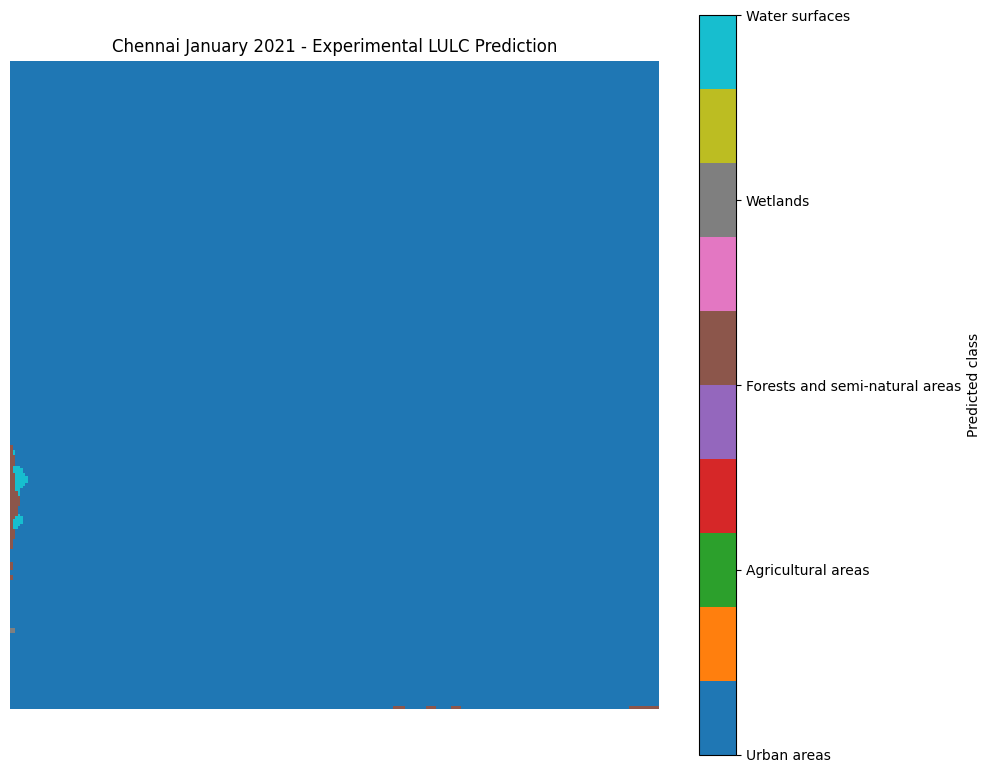


CLASS DISTRIBUTION
Urban areas: 65,361 pixels (99.73%)
Agricultural areas: 0 pixels (0.00%)
Forests and semi-natural areas: 111 pixels (0.17%)
Wetlands: 4 pixels (0.01%)
Water surfaces: 60 pixels (0.09%)


In [44]:

import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURATION
# ==========================================

checkpoint_path = (
    "/content/drive/MyDrive/Sentinel1_LULC_Project/"
    "best_sentinel1_unet_v2.pth"
)

device = torch.device("cpu")

# Check required data
assert os.path.exists(checkpoint_path), "Model checkpoint not found!"
assert 1 in monthly_pc, "January Chennai composite not found!"

# ==========================================
# 2. DEFINE ORIGINAL U-NET ARCHITECTURE
# ==========================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.bridge = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bridge(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


# ==========================================
# 3. LOAD TRAINED CHECKPOINT
# ==========================================

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model = UNet(
    in_channels=2,
    num_classes=5
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully!")
print("Training epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])


# ==========================================
# 4. PREPARE JANUARY CHENNAI DATA
# ==========================================

vh = monthly_pc[1]["vh"].values.astype(np.float32)
vv = monthly_pc[1]["vv"].values.astype(np.float32)

image = np.stack([vh, vv], axis=0)

means = np.asarray(
    checkpoint["normalization_means"],
    dtype=np.float32
).reshape(2, 1, 1)

stds = np.asarray(
    checkpoint["normalization_stds"],
    dtype=np.float32
).reshape(2, 1, 1)

image = (image - means) / stds

# Replace invalid values
image = np.nan_to_num(
    image,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("\nInput image shape:", image.shape)


# ==========================================
# 5. RUN TEST PREDICTION
# ==========================================

patch = image[:, :256, :256]

input_tensor = torch.from_numpy(
    patch.copy()
).unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    predicted_classes = torch.argmax(
        output, dim=1
    ).squeeze(0).cpu().numpy()

print("\nPrediction completed!")
print("Prediction shape:", predicted_classes.shape)
print("Predicted IDs:", np.unique(predicted_classes))


# ==========================================
# 6. DISPLAY PREDICTION MAP
# ==========================================

class_names = checkpoint["class_names"]

# Model outputs 0-4, corresponding to original labels 1-5
class_labels = [
    class_names[i + 1] for i in range(5)
]

plt.figure(figsize=(10, 8))

plt.imshow(
    predicted_classes,
    cmap="tab10",
    vmin=0,
    vmax=4,
    interpolation="nearest"
)

plt.title(
    "Chennai January 2021 - Experimental LULC Prediction"
)

cbar = plt.colorbar(
    ticks=range(5),
    label="Predicted class"
)

cbar.ax.set_yticklabels(class_labels)

plt.axis("off")
plt.tight_layout()
plt.show()


# ==========================================
# 7. CLASS DISTRIBUTION
# ==========================================

print("\nCLASS DISTRIBUTION")

total_pixels = predicted_classes.size

for i in range(5):
    count = np.sum(predicted_classes == i)
    percentage = count / total_pixels * 100

    print(
        f"{class_names[i+1]}: "
        f"{count:,} pixels ({percentage:.2f}%)"
    )


ANNUAL COMPOSITE TEST
Urban areas 99.23%
Agricultural areas 0.00%
Forests and semi-natural areas 0.37%
Wetlands 0.01%
Water surfaces 0.38%


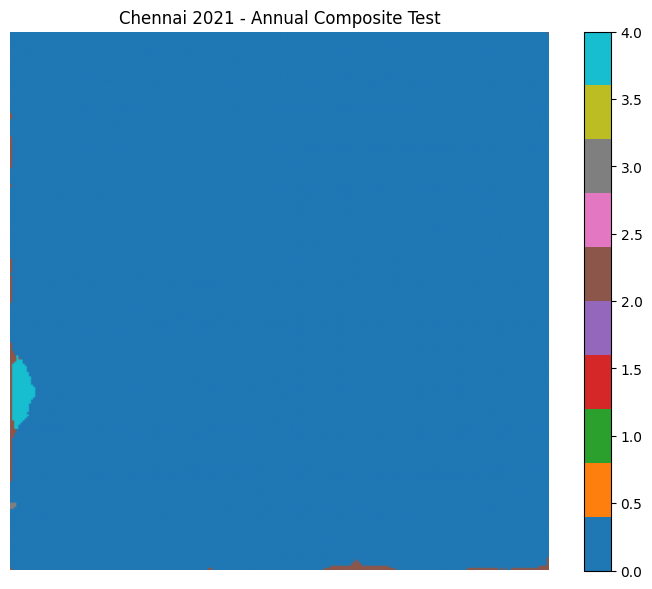

In [45]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Combine the 12 monthly composites
vh_stack = np.stack(
    [monthly_pc[m]["vh"].values for m in range(1, 13)]
)
vv_stack = np.stack(
    [monthly_pc[m]["vv"].values for m in range(1, 13)]
)

# Annual-style median
annual_vh = np.nanmedian(vh_stack, axis=0)
annual_vv = np.nanmedian(vv_stack, axis=0)

# Prepare two-band image
annual_image = np.stack(
    [annual_vh, annual_vv], axis=0
).astype(np.float32)

# Apply original training normalization
means = np.asarray(
    checkpoint["normalization_means"]
).reshape(2, 1, 1)

stds = np.asarray(
    checkpoint["normalization_stds"]
).reshape(2, 1, 1)

annual_image = (annual_image - means) / stds
annual_image = np.nan_to_num(annual_image)

# Predict first 256 x 256 patch
patch = annual_image[:, :256, :256].copy()
tensor = torch.from_numpy(patch).unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(tensor)
    pred = output.argmax(dim=1).squeeze().numpy()

# Class distribution
print("ANNUAL COMPOSITE TEST")

for i in range(5):
    pct = np.mean(pred == i) * 100
    print(checkpoint["class_names"][i+1], f"{pct:.2f}%")

# Display
plt.figure(figsize=(9, 7))
plt.imshow(pred, cmap="tab10", vmin=0, vmax=4)
plt.title("Chennai 2021 - Annual Composite Test")
plt.colorbar()
plt.axis("off")
plt.show()

Chennai means: [ 99.05241 301.74774]
Chennai stds: [ 56.713913 306.58243 ]

CHENNAI NORMALIZATION TEST
Urban areas 29.94%
Agricultural areas 0.01%
Forests and semi-natural areas 69.72%
Wetlands 0.06%
Water surfaces 0.27%


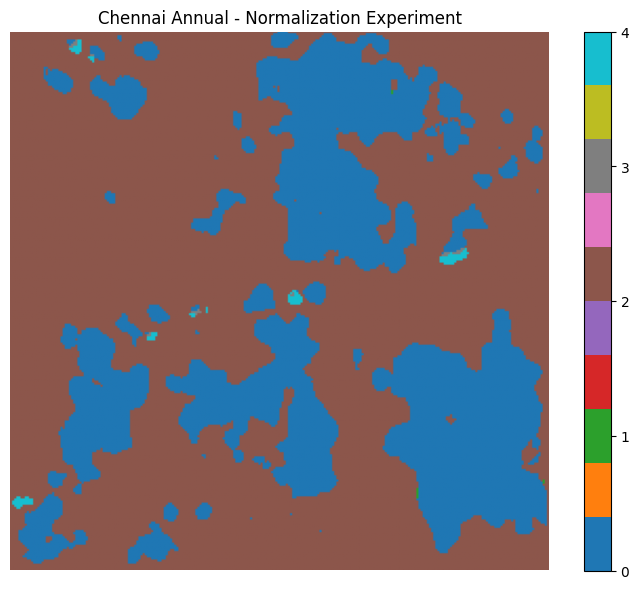

In [46]:
# ==========================================
# CHENNAI-SPECIFIC NORMALIZATION EXPERIMENT
# ==========================================

import numpy as np
import torch
import matplotlib.pyplot as plt

# Use annual Chennai composites
annual_image = np.stack([
    annual_vh,
    annual_vv
], axis=0).astype(np.float32)

# Calculate Chennai channel statistics
chennai_means = np.nanmean(
    annual_image, axis=(1, 2), keepdims=True
)

chennai_stds = np.nanstd(
    annual_image, axis=(1, 2), keepdims=True
)

print("Chennai means:", chennai_means.flatten())
print("Chennai stds:", chennai_stds.flatten())

# Normalize using Chennai statistics
normalized = (
    annual_image - chennai_means
) / (chennai_stds + 1e-6)

normalized = np.nan_to_num(normalized)

# Predict the same 256 x 256 patch
patch = normalized[:, :256, :256].copy()

tensor = torch.from_numpy(patch).unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(tensor)
    pred_chennai_norm = (
        output.argmax(dim=1).squeeze().numpy()
    )

# Class distribution
print("\nCHENNAI NORMALIZATION TEST")

for i in range(5):
    percentage = np.mean(pred_chennai_norm == i) * 100
    print(
        checkpoint["class_names"][i+1],
        f"{percentage:.2f}%"
    )

# Display
plt.figure(figsize=(9, 7))
plt.imshow(
    pred_chennai_norm,
    cmap="tab10",
    vmin=0,
    vmax=4
)
plt.title("Chennai Annual - Normalization Experiment")
plt.colorbar(ticks=range(5))
plt.axis("off")
plt.show()

FULL ANNUAL PREDICTION COMPLETED
Map dimensions: (1664, 1633)

CLASS DISTRIBUTION
Urban areas 21.50%
Agricultural areas 15.07%
Forests and semi-natural areas 63.27%
Wetlands 0.03%
Water surfaces 0.12%


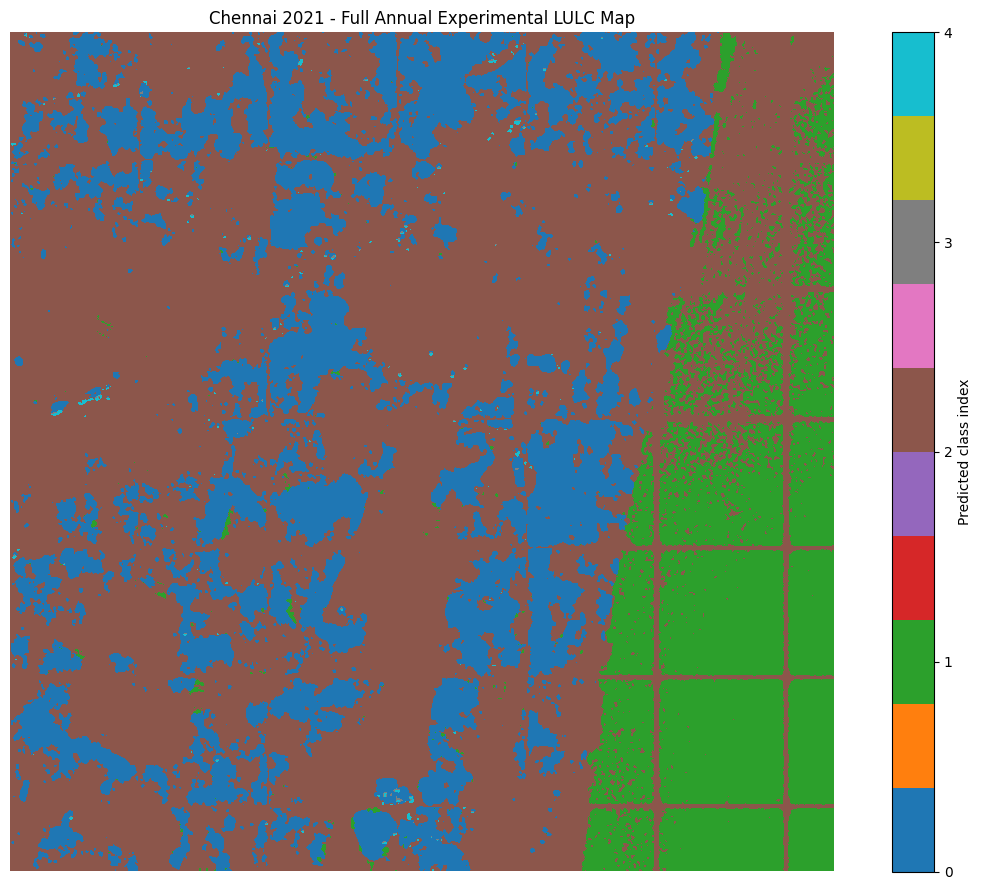


Prediction array saved successfully!


In [47]:

import numpy as np
import torch
import matplotlib.pyplot as plt
import math

# Full annual image
annual_image = np.stack([
    annual_vh,
    annual_vv
], axis=0).astype(np.float32)

# Use the same Chennai-specific statistics
normalized = (
    annual_image - chennai_means
) / (chennai_stds + 1e-6)

normalized = np.nan_to_num(
    normalized,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Pad image to multiples of 256
_, height, width = normalized.shape

pad_h = (256 - height % 256) % 256
pad_w = (256 - width % 256) % 256

padded = np.pad(
    normalized,
    ((0, 0), (0, pad_h), (0, pad_w)),
    mode="reflect"
)

padded_h, padded_w = padded.shape[1:]

# Create output
annual_prediction = np.zeros(
    (padded_h, padded_w),
    dtype=np.uint8
)

# Model prediction
model.eval()

with torch.no_grad():
    for row in range(0, padded_h, 256):
        for col in range(0, padded_w, 256):

            patch = padded[
                :, row:row+256, col:col+256
            ].copy()

            tensor = torch.from_numpy(
                patch
            ).unsqueeze(0)

            output = model(tensor)

            prediction = output.argmax(
                dim=1
            ).squeeze(0).numpy()

            annual_prediction[
                row:row+256,
                col:col+256
            ] = prediction

# Remove padding
annual_prediction = annual_prediction[:height, :width]

print("FULL ANNUAL PREDICTION COMPLETED")
print("Map dimensions:", annual_prediction.shape)

# Class distribution
print("\nCLASS DISTRIBUTION")

for i in range(5):
    percentage = np.mean(annual_prediction == i) * 100
    print(
        checkpoint["class_names"][i+1],
        f"{percentage:.2f}%"
    )

# Display full map
plt.figure(figsize=(12, 9))

plt.imshow(
    annual_prediction,
    cmap="tab10",
    vmin=0,
    vmax=4,
    interpolation="nearest"
)

plt.title("Chennai 2021 - Full Annual Experimental LULC Map")
plt.axis("off")
plt.colorbar(
    ticks=range(5),
    label="Predicted class index"
)

plt.tight_layout()
plt.show()

# Save prediction array
np.save(
    "/content/Chennai_2021_Annual_Experimental_LULC.npy",
    annual_prediction
)

print("\nPrediction array saved successfully!")


OVERLAPPING TILE PREDICTION
Urban areas 23.05%
Agricultural areas 16.19%
Forests and semi-natural areas 60.61%
Wetlands 0.03%
Water surfaces 0.12%


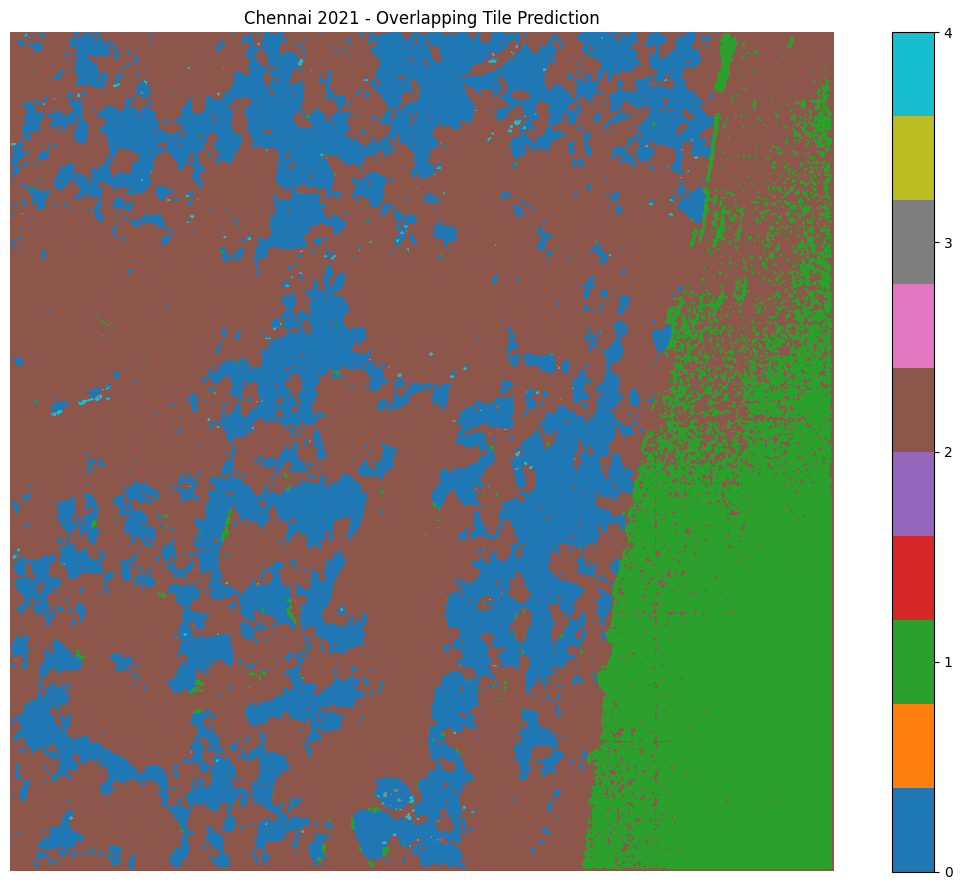

Overlapping prediction saved!


In [48]:

import numpy as np
import torch
import matplotlib.pyplot as plt

# Use the same normalized annual image
H, W = normalized.shape[1:]

PATCH = 256
STRIDE = 128

# Pad to ensure complete coverage
pad_h = max(0, PATCH - H)
pad_w = max(0, PATCH - W)

padded = np.pad(
    normalized,
    ((0, 0), (0, pad_h), (0, pad_w)),
    mode="reflect"
)

PH, PW = padded.shape[1:]

def tile_starts(length, patch, stride):
    starts = list(range(0, length - patch + 1, stride))
    if starts[-1] != length - patch:
        starts.append(length - patch)
    return starts

rows = tile_starts(PH, PATCH, STRIDE)
cols = tile_starts(PW, PATCH, STRIDE)

# Smooth weights to reduce patch-edge influence
window = np.hanning(PATCH).astype(np.float32)
window = np.maximum(window, 0.05)
weights = np.outer(window, window)

num_classes = 5

logit_sum = np.zeros(
    (num_classes, PH, PW), dtype=np.float32
)
weight_sum = np.zeros(
    (PH, PW), dtype=np.float32
)

model.eval()

with torch.no_grad():
    for r in rows:
        for c in cols:

            patch = padded[
                :, r:r+PATCH, c:c+PATCH
            ].copy()

            tensor = torch.from_numpy(
                patch
            ).unsqueeze(0)

            logits = model(tensor).squeeze(0).numpy()

            logit_sum[
                :, r:r+PATCH, c:c+PATCH
            ] += logits * weights[None, :, :]

            weight_sum[
                r:r+PATCH, c:c+PATCH
            ] += weights

# Average overlapping predictions
average_logits = (
    logit_sum / np.maximum(weight_sum[None, :, :], 1e-8)
)

overlap_prediction = np.argmax(
    average_logits, axis=0
).astype(np.uint8)

overlap_prediction = overlap_prediction[:H, :W]

# Distribution
print("OVERLAPPING TILE PREDICTION")

for i in range(5):
    pct = np.mean(overlap_prediction == i) * 100
    print(
        checkpoint["class_names"][i+1],
        f"{pct:.2f}%"
    )

# Display
plt.figure(figsize=(12, 9))
plt.imshow(
    overlap_prediction,
    cmap="tab10",
    vmin=0,
    vmax=4,
    interpolation="nearest"
)
plt.title("Chennai 2021 - Overlapping Tile Prediction")
plt.axis("off")
plt.colorbar(ticks=range(5))
plt.tight_layout()
plt.show()

# Save
np.save(
    "/content/Chennai_2021_Annual_Overlap_LULC.npy",
    overlap_prediction
)

print("Overlapping prediction saved!")


In [49]:

import os
import numpy as np
import pandas as pd
import torch
import rasterio
import matplotlib.pyplot as plt

from affine import Affine
from rasterio.crs import CRS

# ==========================================
# 1. CONFIGURATION
# ==========================================

output_dir = (
    "/content/drive/MyDrive/Sentinel1_LULC_Project/"
    "Monthly_Predictions"
)

os.makedirs(output_dir, exist_ok=True)

PATCH = 256
STRIDE = 128
NUM_CLASSES = 5

class_names = checkpoint["class_names"]

model.eval()

# Fixed annual Chennai normalization statistics
means = chennai_means.astype(np.float32)
stds = chennai_stds.astype(np.float32)

print("Starting 12-month Chennai LULC prediction...")
print("Output folder:", output_dir)


# ==========================================
# 2. OVERLAPPING PREDICTION FUNCTION
# ==========================================

def predict_month(image, model):

    _, H, W = image.shape

    pad_h = max(0, PATCH - H)
    pad_w = max(0, PATCH - W)

    padded = np.pad(
        image,
        ((0, 0), (0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    PH, PW = padded.shape[1:]

    def tile_starts(length):
        starts = list(range(
            0, length - PATCH + 1, STRIDE
        ))

        if starts[-1] != length - PATCH:
            starts.append(length - PATCH)

        return starts

    rows = tile_starts(PH)
    cols = tile_starts(PW)

    # Overlap weighting
    window = np.hanning(PATCH).astype(np.float32)
    window = np.maximum(window, 0.05)
    weights = np.outer(window, window)

    logit_sum = np.zeros(
        (NUM_CLASSES, PH, PW),
        dtype=np.float32
    )

    weight_sum = np.zeros(
        (PH, PW),
        dtype=np.float32
    )

    with torch.no_grad():

        for r in rows:
            for c in cols:

                patch = padded[
                    :, r:r+PATCH, c:c+PATCH
                ].copy()

                tensor = torch.from_numpy(
                    patch
                ).unsqueeze(0)

                logits = model(tensor).squeeze(0).cpu().numpy()

                logit_sum[
                    :, r:r+PATCH, c:c+PATCH
                ] += logits * weights[None, :, :]

                weight_sum[
                    r:r+PATCH, c:c+PATCH
                ] += weights

    average_logits = (
        logit_sum /
        np.maximum(weight_sum[None, :, :], 1e-8)
    )

    prediction = np.argmax(
        average_logits, axis=0
    ).astype(np.uint8)

    return prediction[:H, :W]


# ==========================================
# 3. GEOTIFF SPATIAL METADATA
# ==========================================

reference = monthly_pc[1]

x_coords = reference.x.values
y_coords = reference.y.values

pixel_width = float(np.median(np.diff(x_coords)))
pixel_height = float(np.median(np.diff(y_coords)))

transform = Affine(
    pixel_width, 0, float(x_coords[0]) - pixel_width / 2,
    0, pixel_height, float(y_coords[0]) - pixel_height / 2
)

crs = CRS.from_epsg(32644)

height = len(y_coords)
width = len(x_coords)


# ==========================================
# 4. PROCESS ALL 12 MONTHS
# ==========================================

summary = []

for month in range(1, 13):

    print(f"\nProcessing month {month:02d}/12...")

    # Read VH and VV
    vh = monthly_pc[month]["vh"].values.astype(np.float32)
    vv = monthly_pc[month]["vv"].values.astype(np.float32)

    image = np.stack([vh, vv], axis=0)

    # Apply SAME annual Chennai normalization
    normalized_image = (
        image - means
    ) / (stds + 1e-6)

    normalized_image = np.nan_to_num(
        normalized_image,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Predict full month
    prediction = predict_month(
        normalized_image,
        model
    )

    # Convert model indices 0-4 to original class IDs 1-5
    prediction_labels = prediction + 1

    # Class distribution
    row = {"Month": f"{month:02d}"}

    print("Class distribution:")

    for i in range(NUM_CLASSES):

        percentage = np.mean(prediction == i) * 100

        row[class_names[i+1]] = percentage

        print(
            f"{class_names[i+1]}: {percentage:.2f}%"
        )

    summary.append(row)

    # Save georeferenced GeoTIFF
    output_path = os.path.join(
        output_dir,
        f"Chennai_LULC_2021_{month:02d}.tif"
    )

    profile = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 1,
        "dtype": "uint8",
        "crs": crs,
        "transform": transform,
        "nodata": 0,
        "compress": "lzw"
    }

    with rasterio.open(
        output_path, "w", **profile
    ) as dst:

        dst.write(
            prediction_labels.astype(np.uint8),
            1
        )

        dst.set_band_description(
            1, "Predicted LULC class (1-5)"
        )

        dst.update_tags(
            month=month,
            year=2021,
            method="Experimental Sentinel-1 U-Net V2"
        )

    print("Saved:", output_path)


# ==========================================
# 5. SAVE MONTHLY SUMMARY
# ==========================================

summary_df = pd.DataFrame(summary)

csv_path = os.path.join(
    output_dir,
    "Chennai_2021_Monthly_Class_Distribution.csv"
)

summary_df.to_csv(csv_path, index=False)

print("\n===================================")
print("ALL 12 MONTHS PROCESSED!")
print("===================================")

print(summary_df.to_string(index=False))

print("\nFiles saved in:", output_dir)
print("Summary CSV:", csv_path)


Starting 12-month Chennai LULC prediction...
Output folder: /content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions

Processing month 01/12...
Class distribution:
Urban areas: 40.08%
Agricultural areas: 15.30%
Forests and semi-natural areas: 44.24%
Wetlands: 0.04%
Water surfaces: 0.34%
Saved: /content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_01.tif

Processing month 02/12...
Class distribution:
Urban areas: 30.03%
Agricultural areas: 17.70%
Forests and semi-natural areas: 52.03%
Wetlands: 0.04%
Water surfaces: 0.21%
Saved: /content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_02.tif

Processing month 03/12...
Class distribution:
Urban areas: 30.60%
Agricultural areas: 13.11%
Forests and semi-natural areas: 56.03%
Wetlands: 0.04%
Water surfaces: 0.22%
Saved: /content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_03.tif

Processing month 04/12...
Class distribution:
Urban areas: 31.39%


CSV saved: /content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_2021_Monthly_Class_Distribution.csv


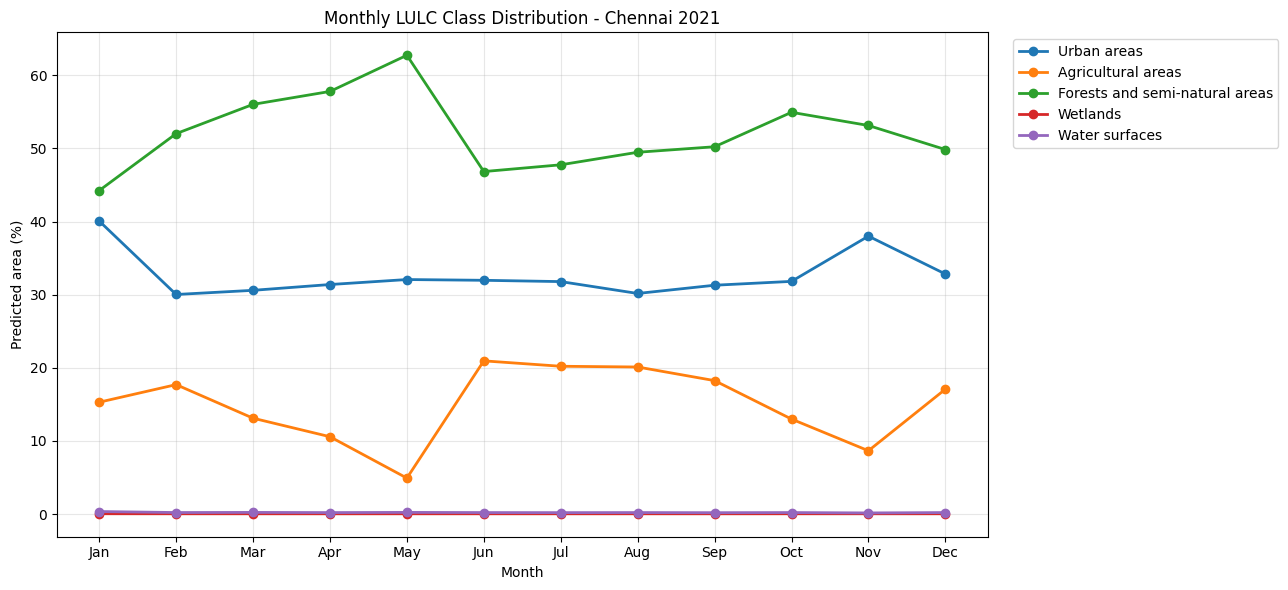


CSV and chart saved successfully!
Month  Urban areas  Agricultural areas  Forests and semi-natural areas  Wetlands  Water surfaces
  Jan    40.075854           15.296477                       44.244496  0.041659        0.341514
  Feb    30.029051           17.700507                       52.028181  0.036543        0.205718
  Mar    30.598621           13.108690                       56.032800  0.036139        0.223751
  Apr    31.392052           10.574310                       57.800944  0.033268        0.199425
  May    32.073829            4.916145                       62.750100  0.034740        0.225186
  Jun    31.969424           20.951477                       46.842173  0.035403        0.201523
  Jul    31.792705           20.212953                       47.767684  0.034446        0.192212
  Aug    30.169410           20.110941                       49.482135  0.036139        0.201375
  Sep    31.295008           18.248144                       50.237036  0.034667        0.18

In [3]:

import os
import pandas as pd
import matplotlib.pyplot as plt

output_dir = (
    "/content/drive/MyDrive/Sentinel1_LULC_Project/"
    "Monthly_Predictions"
)

os.makedirs(output_dir, exist_ok=True)

# Reconstruct the monthly results
data = {
    "Month": [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    "Urban areas": [
        40.075854, 30.029051, 30.598621, 31.392052,
        32.073829, 31.969424, 31.792705, 30.169410,
        31.295008, 31.822662, 38.009327, 32.832777
    ],
    "Agricultural areas": [
        15.296477, 17.700507, 13.108690, 10.574310,
        4.916145, 20.951477, 20.212953, 20.110941,
        18.248144, 12.989896, 8.657195, 17.074337
    ],
    "Forests and semi-natural areas": [
        44.244496, 52.028181, 56.032800, 57.800944,
        62.750100, 46.842173, 47.767684, 49.482135,
        50.237036, 54.947978, 53.143769, 49.855077
    ],
    "Wetlands": [
        0.041659, 0.036543, 0.036139, 0.033268,
        0.034740, 0.035403, 0.034446, 0.036139,
        0.034667, 0.037574, 0.037905, 0.036654
    ],
    "Water surfaces": [
        0.341514, 0.205718, 0.223751, 0.199425,
        0.225186, 0.201523, 0.192212, 0.201375,
        0.185146, 0.201891, 0.151804, 0.201155
    ]
}

df = pd.DataFrame(data)

# Save CSV
csv_path = os.path.join(
    output_dir,
    "Chennai_2021_Monthly_Class_Distribution.csv"
)

df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)

# Plot monthly trends
plt.figure(figsize=(13, 6))

for cls in data.keys():
    if cls != "Month":
        plt.plot(
            df["Month"],
            df[cls],
            marker="o",
            linewidth=2,
            label=cls
        )

plt.title("Monthly LULC Class Distribution - Chennai 2021")
plt.xlabel("Month")
plt.ylabel("Predicted area (%)")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

chart_path = os.path.join(
    output_dir,
    "Monthly_LULC_Trend_2021.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nCSV and chart saved successfully!")
print(df.to_string(index=False))


In [6]:
from google.colab import drive
import os

drive.mount('/content/gdrive')

base = "/content/gdrive/MyDrive/Sentinel1_LULC_Project"

print("\nProject folder exists:", os.path.exists(base))

if os.path.exists(base):
    print("\nProject contents:")
    for item in os.listdir(base):
        print(item)

    prediction_folder = os.path.join(
        base, "Monthly_Predictions"
    )

    print("\nMonthly Predictions folder:",
          os.path.exists(prediction_folder))

    if os.path.exists(prediction_folder):
        print("\nPrediction files:")
        for f in os.listdir(prediction_folder):
            print(f)

Mounted at /content/gdrive

Project folder exists: True

Project contents:
data
models
results
outputs
logs
drive_test.txt
best_sentinel1_unet_v2.pth
Monthly_Predictions

Monthly Predictions folder: True

Prediction files:
Chennai_LULC_2021_01.tif
Chennai_LULC_2021_02.tif
Chennai_LULC_2021_03.tif
Chennai_LULC_2021_04.tif
Chennai_LULC_2021_05.tif
Chennai_LULC_2021_06.tif
Chennai_LULC_2021_07.tif
Chennai_LULC_2021_08.tif
Chennai_LULC_2021_09.tif
Chennai_LULC_2021_10.tif
Chennai_LULC_2021_11.tif
Chennai_LULC_2021_12.tif
Chennai_2021_Monthly_Class_Distribution.csv


In [7]:

import os
import rasterio
import numpy as np
import pandas as pd

folder = (
    "/content/gdrive/MyDrive/Sentinel1_LULC_Project/"
    "Monthly_Predictions"
)

results = []

for month in range(1, 13):

    path = os.path.join(
        folder,
        f"Chennai_LULC_2021_{month:02d}.tif"
    )

    with rasterio.open(path) as src:

        arr = src.read(1)
        unique = np.unique(arr)

        results.append({
            "Month": month,
            "Dimensions": str(arr.shape),
            "CRS": str(src.crs),
            "Resolution": str(src.res),
            "Class IDs": str(unique.tolist()),
            "Valid pixels": int(np.sum(arr != 0)),
            "File size MB": round(
                os.path.getsize(path) / (1024**2), 2
            )
        })

df_check = pd.DataFrame(results)

print(df_check.to_string(index=False))
print("\nVerified files:", len(results), "/ 12")

# Verify monthly summary
csv_path = os.path.join(
    folder,
    "Chennai_2021_Monthly_Class_Distribution.csv"
)

df_summary = pd.read_csv(csv_path)

print("\nMonthly summary rows:", len(df_summary))
print("Verification completed!")


 Month   Dimensions        CRS   Resolution       Class IDs  Valid pixels  File size MB
     1 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.18
     2 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.17
     3 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.18
     4 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.19
     5 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.17
     6 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.16
     7 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.16
     8 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.16
     9 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.17
    10 (1664, 1633) EPSG:32644 (10.0, 10.0) [1, 2, 3, 4, 5]       2717312          0.18
    11 (1664, 1633) EPSG:32644 (

In [8]:
import os

base = "/content/gdrive/MyDrive/Sentinel1_LULC_Project"

for folder in ["data", "models", "results", "outputs", "logs"]:
    path = os.path.join(base, folder)

    print(f"\n--- {folder.upper()} ---")

    if os.path.exists(path):
        for item in os.listdir(path):
            print(item)


--- DATA ---

--- MODELS ---

--- RESULTS ---

--- OUTPUTS ---

--- LOGS ---


In [11]:
import ee

try:
    ee.Initialize(project="sentinel1-lulc-project")
    print("Earth Engine connected successfully!")

    collection = ee.ImageCollection(
        "ESA/WorldCover/v200"
    )

    print("WorldCover image count:",
          collection.size().getInfo())

except Exception as e:
    print("Earth Engine connection issue:", str(e))

Earth Engine connected successfully!
WorldCover image count: 1


In [14]:
import rasterio
import numpy as np

path = (
    "/content/gdrive/MyDrive/Sentinel1_LULC_Project/"
    "results/Chennai_ESA_WorldCover_2021_Aligned.tif"
)

with rasterio.open(path) as src:
    reference_aligned = src.read(1)

    print("Shape:", reference_aligned.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Transform:", src.transform)
    print("Class values:", np.unique(reference_aligned))

print("\nReference raster loaded successfully!")

Shape: (1664, 1633)
CRS: EPSG:32644
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|
Class values: [10 20 30 40 50 60 80 90]

Reference raster loaded successfully!


In [15]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    jaccard_score
)

# ESA WorldCover -> model class IDs
mapping = {
    50: 1,
    40: 2,
    10: 3,
    20: 3,
    30: 3,
    90: 4,
    95: 4,
    80: 5
}

reference_classes = np.zeros(
    reference_aligned.shape,
    dtype=np.uint8
)

for esa_id, model_id in mapping.items():
    reference_classes[
        reference_aligned == esa_id
    ] = model_id

# Exclude unmatched reference classes
valid = (
    (reference_classes > 0) &
    (prediction >= 0) &
    (prediction <= 4)
)

y_true = reference_classes[valid]
y_pred = prediction[valid] + 1

labels = [1, 2, 3, 4, 5]

names = [
    "Urban",
    "Agriculture",
    "Forest/Semi-natural",
    "Wetlands",
    "Water"
]

print("Valid pixels:", len(y_true))
print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=labels))

print("\nOverall agreement:", round(
    accuracy_score(y_true, y_pred), 4
))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))

ious = jaccard_score(
    y_true,
    y_pred,
    labels=labels,
    average=None,
    zero_division=0
)

print("\nPer-class IoU:")
for name, value in zip(names, ious):
    print(f"{name}: {value:.4f}")

print("\nMean IoU:", round(float(np.mean(ious)), 4))

Valid pixels: 2674639

Confusion matrix:
[[     0 830482  11572 450378    801]
 [     0  47607   2690  81623     27]
 [     0 174489   7433 417317    283]
 [     0   5932   1317  14090      0]
 [     0  20172 385940 222486      0]]

Overall agreement: 0.0258

Classification report:
                     precision    recall  f1-score   support

              Urban       0.00      0.00      0.00   1293233
        Agriculture       0.04      0.36      0.08    131947
Forest/Semi-natural       0.02      0.01      0.01    599522
           Wetlands       0.01      0.66      0.02     21339
              Water       0.00      0.00      0.00    628598

           accuracy                           0.03   2674639
          macro avg       0.01      0.21      0.02   2674639
       weighted avg       0.01      0.03      0.01   2674639


Per-class IoU:
Urban: 0.0000
Agriculture: 0.0409
Forest/Semi-natural: 0.0074
Wetlands: 0.0118
Water: 0.0000

Mean IoU: 0.012


In [16]:
import numpy as np

print("MODEL PREDICTION CLASS COUNTS")

for i in range(5):
    count = np.sum(prediction == i)
    print(f"Model ID {i}: {count:,}")

print("\nREFERENCE CLASS COUNTS")

for i in range(1, 6):
    count = np.sum(reference_classes == i)
    print(f"Reference ID {i}: {count:,}")

print("\nRAW ESA CLASS COUNTS")

for i in np.unique(reference_aligned):
    print(
        f"ESA ID {i}: "
        f"{np.sum(reference_aligned == i):,}"
    )

print("\nPREDICTION TRANSFORM:")
with rasterio.open(prediction_path) as src:
    print(src.transform)

print("\nREFERENCE TRANSFORM:")
with rasterio.open(aligned_path) as src:
    print(src.transform)

MODEL PREDICTION CLASS COUNTS
Model ID 0: 0
Model ID 1: 1,088,986
Model ID 2: 415,653
Model ID 3: 1,202,261
Model ID 4: 1,132

REFERENCE CLASS COUNTS
Reference ID 1: 1,299,498
Reference ID 2: 132,439
Reference ID 3: 601,650
Reference ID 4: 21,463
Reference ID 5: 628,805

RAW ESA CLASS COUNTS
ESA ID 10: 456,819
ESA ID 20: 3,949
ESA ID 30: 140,882
ESA ID 40: 132,439
ESA ID 50: 1,299,498
ESA ID 60: 33,457
ESA ID 80: 628,805
ESA ID 90: 21,463

PREDICTION TRANSFORM:
| 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|

REFERENCE TRANSFORM:
| 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|


In [17]:

import rasterio
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    jaccard_score
)

base = "/content/gdrive/MyDrive/Sentinel1_LULC_Project"

prediction_path = (
    base + "/Monthly_Predictions/Chennai_LULC_2021_01.tif"
)

reference_path = (
    base + "/results/Chennai_ESA_WorldCover_2021_Aligned.tif"
)

# Read both rasters
with rasterio.open(prediction_path) as src:
    pred = src.read(1)

with rasterio.open(reference_path) as src:
    ref = src.read(1)

assert pred.shape == ref.shape

# ESA WorldCover -> five AI4LCC-style classes
mapping = {
    50: 1,             # Built-up -> Urban
    40: 2,             # Cropland -> Agriculture
    10: 3, 20: 3, 30: 3,  # Tree, shrub, grass -> Forest/semi-natural
    90: 4,             # Herbaceous wetland -> Wetlands
    95: 4,             # Mangroves -> Wetlands, if present
    80: 5              # Permanent water -> Water
}

reference_classes = np.zeros(
    ref.shape, dtype=np.uint8
)

for esa_id, model_id in mapping.items():
    reference_classes[ref == esa_id] = model_id

# IMPORTANT: prediction already contains IDs 1-5.
# Do NOT add 1.

valid = (
    (reference_classes >= 1) &
    (reference_classes <= 5) &
    (pred >= 1) &
    (pred <= 5)
)

y_true = reference_classes[valid]
y_pred = pred[valid]

labels = [1, 2, 3, 4, 5]

names = [
    "Urban",
    "Agriculture",
    "Forest/Semi-natural",
    "Wetlands",
    "Water"
]

print("Valid comparison pixels:", len(y_true))

print("\nCORRECTED CONFUSION MATRIX")
cm = confusion_matrix(y_true, y_pred, labels=labels)
print(cm)

print("\nOVERALL ACCURACY")
oa = accuracy_score(y_true, y_pred)
print(f"{oa:.4f} ({oa*100:.2f}%)")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))

ious = jaccard_score(
    y_true, y_pred,
    labels=labels,
    average=None,
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    labels=labels,
    average=None,
    zero_division=0
)

print("\nPER-CLASS METRICS")
for name, iou, score in zip(names, ious, f1):
    print(f"{name}: IoU={iou:.4f}, F1={score:.4f}")

print("\nMACRO F1:", round(float(np.mean(f1)), 4))
print("MEAN IoU:", round(float(np.mean(ious)), 4))


Valid comparison pixels: 2683855

CORRECTED CONFUSION MATRIX
[[830482  11572 450378    801   6265]
 [ 47607   2690  81623     27    492]
 [174489   7433 417317    283   2128]
 [  5932   1317  14090      0    124]
 [ 20172 385940 222486      0    207]]

OVERALL ACCURACY
0.4660 (46.60%)

CLASSIFICATION REPORT
                     precision    recall  f1-score   support

              Urban       0.77      0.64      0.70   1299498
        Agriculture       0.01      0.02      0.01    132439
Forest/Semi-natural       0.35      0.69      0.47    601650
           Wetlands       0.00      0.00      0.00     21463
              Water       0.02      0.00      0.00    628805

           accuracy                           0.47   2683855
          macro avg       0.23      0.27      0.24   2683855
       weighted avg       0.46      0.47      0.44   2683855


PER-CLASS METRICS
Urban: IoU=0.5366, F1=0.6984
Agriculture: IoU=0.0050, F1=0.0099
Forest/Semi-natural: IoU=0.3046, F1=0.4669
Wetlands: IoU

In [18]:
import pandas as pd
import numpy as np
import os

results_dir = (
    "/content/gdrive/MyDrive/"
    "Sentinel1_LULC_Project/results"
)
os.makedirs(results_dir, exist_ok=True)

# Per-class results
metrics_df = pd.DataFrame({
    "Class": [
        "Urban",
        "Agriculture",
        "Forest/Semi-natural",
        "Wetlands",
        "Water"
    ],
    "F1_Score": [0.6984, 0.0099, 0.4669, 0.0000, 0.0006],
    "IoU": [0.5366, 0.0050, 0.3046, 0.0000, 0.0003]
})

metrics_df.to_csv(
    os.path.join(results_dir, "ESA_Validation_Class_Metrics.csv"),
    index=False
)

# Confusion matrix
cm = np.array([
    [830482, 11572, 450378, 801, 6265],
    [47607, 2690, 81623, 27, 492],
    [174489, 7433, 417317, 283, 2128],
    [5932, 1317, 14090, 0, 124],
    [20172, 385940, 222486, 0, 207]
])

cm_df = pd.DataFrame(
    cm,
    index=metrics_df["Class"],
    columns=metrics_df["Class"]
)

cm_df.to_csv(
    os.path.join(results_dir, "ESA_Validation_Confusion_Matrix.csv")
)

print("Validation results saved successfully.")
print("Overall Accuracy: 46.60%")
print("Mean IoU: 16.93%")

Validation results saved successfully.
Overall Accuracy: 46.60%
Mean IoU: 16.93%


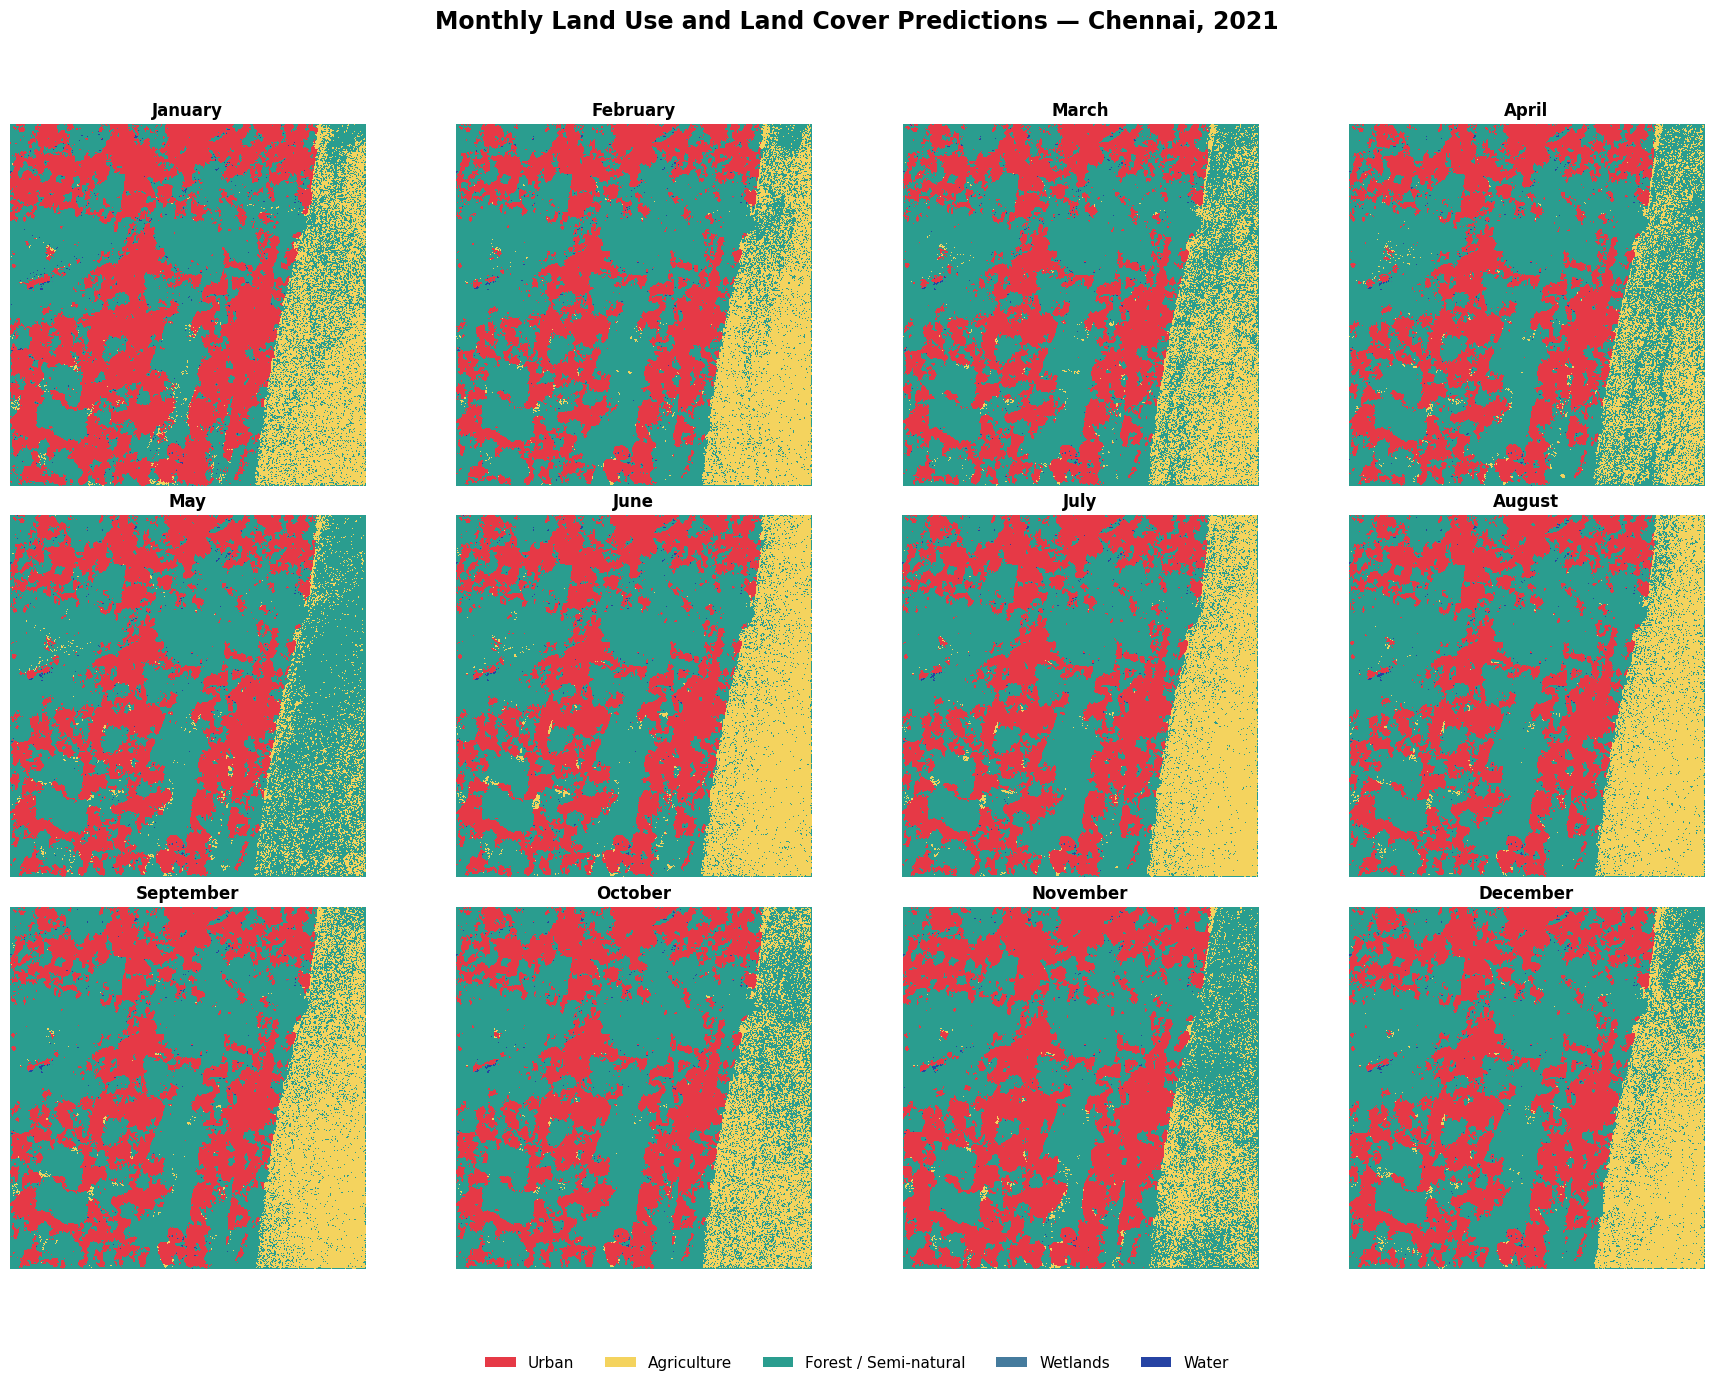

Saved: /content/gdrive/MyDrive/Sentinel1_LULC_Project/results/Chennai_2021_Monthly_LULC_Maps.png


In [19]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

base_dir = "/content/gdrive/MyDrive/Sentinel1_LULC_Project"
prediction_dir = os.path.join(base_dir, "Monthly_Predictions")
output_dir = os.path.join(base_dir, "results")

os.makedirs(output_dir, exist_ok=True)

class_names = [
    "Urban",
    "Agriculture",
    "Forest / Semi-natural",
    "Wetlands",
    "Water"
]

# Consistent colors across all months
colors = [
    "#e63946",  # Urban
    "#f4d35e",  # Agriculture
    "#2a9d8f",  # Forest
    "#457b9d",  # Wetlands
    "#2643a3"   # Water
]

cmap = ListedColormap(colors)

fig, axes = plt.subplots(3, 4, figsize=(18, 14))

for month in range(1, 13):
    ax = axes[(month - 1) // 4, (month - 1) % 4]

    filename = f"Chennai_LULC_2021_{month:02d}.tif"
    filepath = os.path.join(prediction_dir, filename)

    with rasterio.open(filepath) as src:
        data = src.read(1)

    ax.imshow(
        data,
        cmap=cmap,
        vmin=1,
        vmax=5,
        interpolation="nearest"
    )

    ax.set_title(
        f"{['January','February','March','April','May','June',\
            'July','August','September','October','November','December'][month-1]}",
        fontsize=12,
        fontweight="bold"
    )
    ax.axis("off")

legend_items = [
    Patch(facecolor=colors[i], label=class_names[i])
    for i in range(5)
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=5,
    fontsize=11,
    frameon=False
)

fig.suptitle(
    "Monthly Land Use and Land Cover Predictions — Chennai, 2021",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])

output_path = os.path.join(
    output_dir,
    "Chennai_2021_Monthly_LULC_Maps.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

In [10]:
import ee

ee.Authenticate()

In [18]:
import zarr
print("Zarr version:", zarr.__version__)

Zarr version: 3.4.2


In [19]:

import zarr
import numpy as np
from zarr.storage import ZipStore

store = ZipStore(zarr_path, mode="r")
root = zarr.open_group(store=store, mode="r")

print("Available arrays:", list(root.array_keys()))

for band in ["vh", "vv"]:
    arr = root[band]
    sample = np.asarray(arr[1000:2000, 1000:2000])
    values = sample.ravel()
    values = values[np.isfinite(values)]

    print(f"\n{band.upper()} values")
    print("P1:", np.percentile(values, 1))
    print("Median:", np.percentile(values, 50))
    print("P99:", np.percentile(values, 99))

store.close()


GroupNotFoundError: No group found in store ZipStore('zip:///root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.zarr.zip') at path ''

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

import ee

# Reconnect to Google Earth Engine
ee.Initialize(project="sentinel1-lulc-project")

# Define Chennai study area
study_area = ee.Geometry.Rectangle([80.15, 12.90, 80.30, 13.05])

# Reload Sentinel-1 data for 2021
s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VH", "VV"])
)

# Recreate monthly composites
monthly_composites = {}

for month in range(1, 13):
    start = ee.Date.fromYMD(2021, month, 1)
    end = start.advance(1, "month")
    collection = s1_chennai.filterDate(start, end)

    if collection.size().getInfo() > 0:
        monthly_composites[month] = (
            collection.median()
            .clip(study_area)
            .set("month", month)
            .set("year", 2021)
        )

print("Months recreated:", sorted(monthly_composites.keys()))
print("January bands:", monthly_composites[1].bandNames().getInfo())


Months recreated: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
January bands: ['VH', 'VV']


In [3]:

import ee

ee.Authenticate()


In [8]:
import ee

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .clip(study_area)
)

class_histogram = worldcover.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=study_area,
    scale=10,
    maxPixels=1e8,
    tileScale=4
).get("Map").getInfo()

print("WorldCover classes in Chennai study area:")
for code, count in sorted(
    class_histogram.items(),
    key=lambda item: int(item[0])
):
    print(f"Class {code}: {int(count)} pixels")

WorldCover classes in Chennai study area:
Class 10: 470095 pixels
Class 20: 3988 pixels
Class 30: 145066 pixels
Class 40: 135411 pixels
Class 50: 1334631 pixels
Class 60: 34180 pixels
Class 80: 643083 pixels
Class 90: 21874 pixels


In [9]:
# Cell 2: Inspect the Sentinel-1 dataset repository

!pip -q install -U huggingface_hub

from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

try:
    info = api.dataset_info(dataset_id)

    print("Dataset:", dataset_id)
    print("URL:", f"https://huggingface.co/datasets/{dataset_id}")
    print("\nRepository files:")

    files = api.list_repo_files(
        repo_id=dataset_id,
        repo_type="dataset"
    )

    for filename in files:
        print(filename)

    print("\nTotal files:", len(files))

except Exception as error:
    print("Dataset inspection failed.")
    print("Error:", repr(error))

print("\nDataset inspection finished.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.3.0 which is incompatible.
Dataset: wtr001/S1_AI4LCC
URL: https://huggingface.co/datasets/wtr001/S1_AI4LCC

Repository files:
.DS_Store
.cache/.DS_Store
.gitattributes
README.md
images/typology_AI4LCC.png
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.zarr.zip
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.zarr.zip

In [10]:
# Cell 3: Inspect dataset file sizes and select sample candidates

!pip -q install -U huggingface_hub

from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

info = api.dataset_info(
    dataset_id,
    files_metadata=True
)

siblings = info.siblings

print("=" * 75)
print("DATASET FILE SIZE INSPECTION")
print("=" * 75)

records = []

for item in siblings:
    name = item.rfilename
    size = getattr(item, "size", None)

    if size is None:
        size_text = "Unknown"
    else:
        size_text = f"{size / (1024 ** 2):.2f} MB"

    records.append((name, size, size_text))

print("\nFirst 25 files:\n")

for name, size, size_text in records[:25]:
    print(f"{size_text:>12} | {name}")

known_sizes = [size for _, size, _ in records if size is not None]

if known_sizes:
    print("\nTotal known size: {:.2f} GB".format(
        sum(known_sizes) / (1024 ** 3)
    ))

    print("Smallest known file: {:.2f} MB".format(
        min(known_sizes) / (1024 ** 2)
    ))

print("\nFile inspection complete.")

DATASET FILE SIZE INSPECTION

First 25 files:

     0.01 MB | .DS_Store
     0.01 MB | .cache/.DS_Store
     0.01 MB | .gitattributes
     0.01 MB | README.md
     0.08 MB | images/typology_AI4LCC.png
   441.17 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.tif
   291.61 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.zarr.zip
   471.23 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.tif
   308.98 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.zarr.zip
   200.54 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip2_reduced2020_labelclass1.tif
   123.25 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip2_reduced2020_labelclass1.zarr.zip
   226.59 MB | sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_N

In [11]:
# Cell 4: Find dataset documentation and metadata

from huggingface_hub import HfApi, hf_hub_download
import os

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

files = api.list_repo_files(
    repo_id=dataset_id,
    repo_type="dataset"
)

print("Documentation and metadata files:\n")

candidates = [
    name for name in files
    if name.lower().endswith((
        ".md", ".txt", ".json", ".yaml", ".yml", ".csv"
    ))
    and (
        "/" not in name
        or name.count("/") == 0
    )
]

for name in candidates:
    print("-", name)

print("\nRepository root files:")
for name in files:
    if "/" not in name:
        print("-", name)

# Download and display README if available
readme_name = next(
    (name for name in files if name.lower() == "readme.md"),
    None
)

if readme_name:
    readme_path = hf_hub_download(
        repo_id=dataset_id,
        filename=readme_name,
        repo_type="dataset"
    )

    print("\n" + "=" * 65)
    print("DATASET README")
    print("=" * 65)

    with open(readme_path, "r", encoding="utf-8") as f:
        print(f.read()[:12000])
else:
    print("\nNo root README.md found.")
    print("We will inspect the dataset card and metadata separately.")

Documentation and metadata files:

- README.md

Repository root files:
- .DS_Store
- .gitattributes
- README.md


README.md:   0%|          | 0.00/5.34k [00:00<?, ?B/s]


DATASET README
---
license: cc-by-4.0
task_categories:
- image-segmentation
language:
- en
tags:
- sentinel-1
- remote-sensing
- earth-observation
- zarr
- geospatial
pretty_name: Sentinel-1 Land Cover Dataset (Zarr Format)
---
# Sentinel-1 Land Cover Dataset (Zarr Format)

<!-- Provide a quick summary of the dataset. -->
## Dataset Summary
This dataset contains land-cover labels derived from the [AI4LCC benchmark dataset](https://doi.theia.data-terra.org/ai4lcc/?lang=en) and corresponding Sentinel-1 satellite imagery.
The original labels and Sentinel-1 were converted into Zarr format to enable efficient storage and scalable access for large geospatial datasets. Sentinel-1 image tiles corresponding to the label locations were added to create a paired dataset suitable for machine learning tasks such as land-cover classification and semantic segmentation.
The dataset is intended for research and development in remote sensing, Earth observation, and machine learning.

<!--It has been gen

In [12]:
# Cell 5: Select and inspect one small gap-filled Zarr archive

from huggingface_hub import HfApi, hf_hub_download
import zipfile
import os

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

print("Finding the smallest gap-filled Zarr archive...")

files = api.list_repo_tree(
    repo_id=dataset_id,
    repo_type="dataset",
    recursive=True,
    expand=True
)

candidates = []

for item in files:
    name = getattr(item, "path", "")
    size = getattr(item, "size", None)

    if (
        name.startswith("sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/")
        and name.endswith(".zarr.zip")
        and size is not None
    ):
        candidates.append((name, size))

if not candidates:
    raise RuntimeError(
        "No matching gap-filled Zarr archives found. "
        "Check the repository file listing."
    )

candidates.sort(key=lambda x: x[1])

filename, size = candidates[0]

print("\nSelected file:", filename)
print("Compressed size: {:.2f} MB".format(size / (1024 ** 2)))

print("\nDownloading the selected archive...")

local_path = hf_hub_download(
    repo_id=dataset_id,
    filename=filename,
    repo_type="dataset"
)

print("Download complete:", local_path)

print("\nInspecting archive contents...")

with zipfile.ZipFile(local_path, "r") as archive:
    members = archive.infolist()

    print("Total entries:", len(members))
    print("\nFirst 40 entries:")

    for member in members[:40]:
        print(
            member.filename,
            "| {:.2f} KB".format(member.file_size / 1024)
        )

    print("\nArchive inspection complete.")

Finding the smallest gap-filled Zarr archive...

Selected file: sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr.zip
Compressed size: 2.94 MB



sentinel1_NA_AI4LCC_reduced2020_labelcla(…): reconstructing file:   0%|          |  0.00B / 3.08MB            

sentinel1_NA_AI4LCC_reduced2020_labelcla(…): downloading bytes:           |  0.00B            

Download complete: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr.zip

Inspecting archive contents...
Total entries: 952

First 40 entries:
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/ | 0.00 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/ | 0.00 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/7.11 | 2.14 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/12.12 | 2.14 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/3.19 | 2.16 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/12.15 | 2.14 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/7.16 | 2.14 KB
sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr/vh/3.10 | 2.14 KB
sentinel1_NA_31TCL_clip3_reduced20

In [13]:
# Cell 6: Inspect Zarr groups, arrays, dimensions, and class values

!pip -q install zarr numcodecs xarray dask

import os
import zipfile
import tempfile
import json
import numpy as np

from huggingface_hub import hf_hub_download

dataset_id = "wtr001/S1_AI4LCC"

filename = (
    "sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr.zip"
)

archive_path = hf_hub_download(
    repo_id=dataset_id,
    filename=filename,
    repo_type="dataset"
)

print("Archive:", os.path.basename(archive_path))

# Extract the sample only
extract_dir = "/content/lulc_sample"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(archive_path, "r") as archive:
    archive.extractall(extract_dir)

# Locate the Zarr root
zarr_dirs = [
    os.path.join(extract_dir, name)
    for name in os.listdir(extract_dir)
    if name.endswith(".zarr")
]

if not zarr_dirs:
    raise FileNotFoundError("No extracted .zarr directory found.")

zarr_path = zarr_dirs[0]

print("\nZarr directory:", zarr_path)

# Show array metadata files
print("\nArray metadata files:")

for root, dirs, files in os.walk(zarr_path):
    for file in files:
        if file in (".zarray", ".zattrs", ".zgroup"):
            path = os.path.join(root, file)
            print("\n", os.path.relpath(path, zarr_path))

            try:
                with open(path, "r") as f:
                    print(json.dumps(json.load(f), indent=2)[:1500])
            except Exception as error:
                print("Could not read metadata:", error)

# Inspect the Zarr hierarchy
import zarr

try:
    group = zarr.open_group(zarr_path, mode="r")

    print("\nZarr hierarchy:")
    print(group.tree())

    print("\nRoot attributes:")
    print(dict(group.attrs))

except Exception as error:
    print("\nZarr inspection error:", repr(error))
    print("We will adjust the reader based on the metadata format.")

Archive: sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr.zip

Zarr directory: /content/lulc_sample/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr

Array metadata files:

 .zattrs
{}

 .zgroup
{
  "zarr_format": 2
}

 vh/.zattrs
{
  "grid_mapping": "spatial_ref",
  "_ARRAY_DIMENSIONS": [
    "y",
    "x"
  ]
}

 vh/.zarray
{
  "shape": [
    4876,
    4876
  ],
  "chunks": [
    256,
    256
  ],
  "dtype": "<f8",
  "fill_value": "NaN",
  "order": "C",
  "filters": null,
  "dimension_separator": ".",
  "compressor": {
    "id": "blosc",
    "cname": "lz4",
    "clevel": 5,
    "shuffle": 1,
    "blocksize": 0
  },
  "zarr_format": 2
}

 x/.zattrs
{
  "axis": "X",
  "long_name": "x coordinate of projection",
  "standard_name": "projection_x_coordinate",
  "units": "metre",
  "_ARRAY_DIMENSIONS": [
    "x"
  ]
}

 x/.zarray
{
  "shape": [
    4876
  ],
  "chunks": [
    4876
  ],
  "dtype": "<f8",
  "fill_value": "NaN",
  "order": "C",
  "filters": null,
 

SATELLITE SAMPLE INSPECTION
VV shape: (512, 512)
VH shape: (512, 512)
Label shape: (512, 512)

VV
  Valid pixels: 262144
  Missing pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Mean: 0.0

VH
  Valid pixels: 262144
  Missing pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Mean: 0.0

Labels
  Valid pixels: 262144
  Missing pixels: 0
  Minimum: 0.0
  Maximum: 5.0
  Mean: 2.1111602783203125

Unique label values and pixel counts:
  Label 0: 1 pixels
  Label 1: 34,235 pixels
  Label 2: 165,145 pixels
  Label 3: 62,456 pixels
  Label 5: 307 pixels


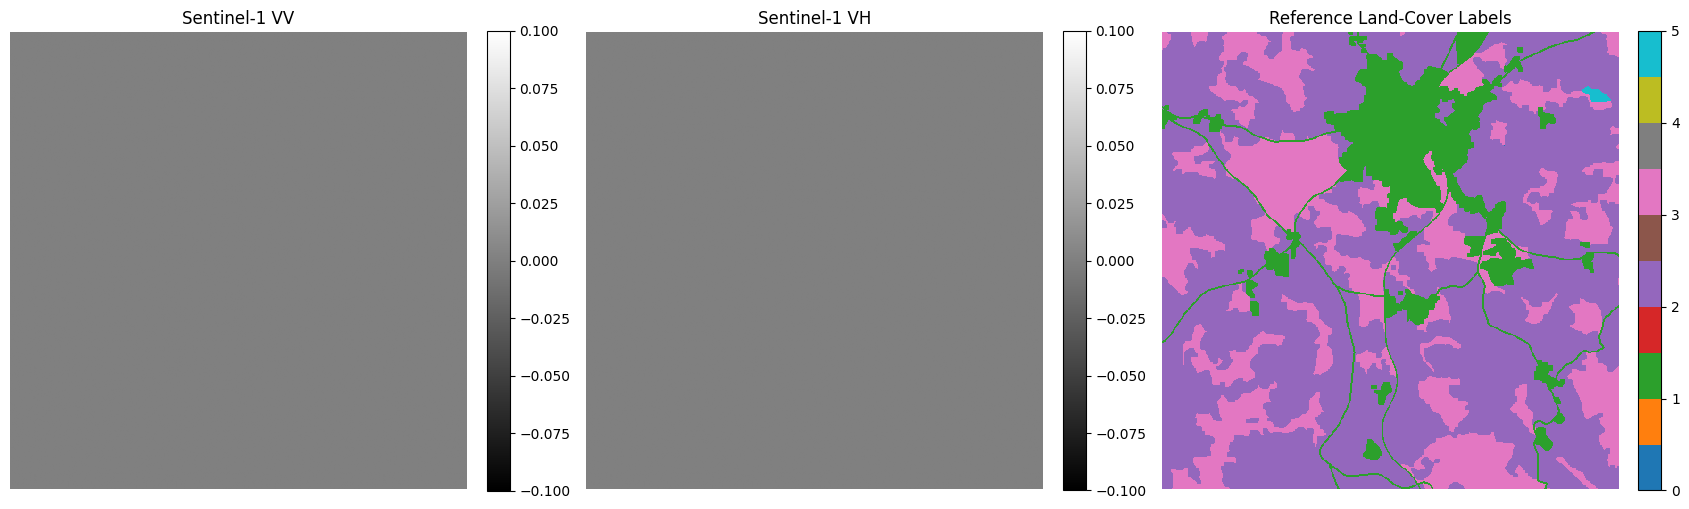


Inspection complete. Do not train yet.


In [14]:
# Cell 7: Visualize Sentinel-1 bands and inspect label classes

import numpy as np
import matplotlib.pyplot as plt
import zarr
import os

# Open the extracted Zarr dataset
zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

# Select a small window to avoid loading the entire tile
sample_size = 512
height, width = group["vv"].shape

row_start = (height - sample_size) // 2
col_start = (width - sample_size) // 2

rows = slice(row_start, row_start + sample_size)
cols = slice(col_start, col_start + sample_size)

# Load the same spatial window from both bands and the label mask
vv = np.asarray(group["vv"][rows, cols], dtype=np.float32)
vh = np.asarray(group["vh"][rows, cols], dtype=np.float32)
labels = np.asarray(group["label"][rows, cols])

# Report array information
print("=" * 60)
print("SATELLITE SAMPLE INSPECTION")
print("=" * 60)

print("VV shape:", vv.shape)
print("VH shape:", vh.shape)
print("Label shape:", labels.shape)

for name, array in [("VV", vv), ("VH", vh), ("Labels", labels)]:
    valid = np.isfinite(array)

    print(f"\n{name}")
    print("  Valid pixels:", int(valid.sum()))
    print("  Missing pixels:", int((~valid).sum()))

    if valid.any():
        values = array[valid]
        print("  Minimum:", float(values.min()))
        print("  Maximum:", float(values.max()))
        print("  Mean:", float(values.mean()))

# Inspect class IDs and frequencies
valid_labels = labels[np.isfinite(labels)]

print("\nUnique label values and pixel counts:")
values, counts = np.unique(valid_labels, return_counts=True)

for value, count in zip(values, counts):
    print(f"  Label {value:g}: {count:,} pixels")

# Display the three arrays
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, array, title in [
    (axes[0], vv, "Sentinel-1 VV"),
    (axes[1], vh, "Sentinel-1 VH"),
]:
    valid = np.isfinite(array)

    if valid.any():
        vmin, vmax = np.percentile(array[valid], [2, 98])
        image = ax.imshow(array, cmap="gray", vmin=vmin, vmax=vmax)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    else:
        ax.imshow(np.zeros_like(array), cmap="gray")

    ax.set_title(title)
    ax.axis("off")

label_image = axes[2].imshow(labels, cmap="tab10", interpolation="nearest")
axes[2].set_title("Reference Land-Cover Labels")
axes[2].axis("off")
fig.colorbar(label_image, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("\nInspection complete. Do not train yet.")

In [15]:
# Cell 8: Diagnose Sentinel-1 values across the tile

import numpy as np
import zarr

zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

vv_array = group["vv"]
vh_array = group["vh"]
label_array = group["label"]

height, width = vv_array.shape

print("=" * 65)
print("SENTINEL-1 ZERO-VALUE DIAGNOSTICS")
print("=" * 65)

# Inspect multiple locations across the tile
sample_size = 256

windows = {
    "Top-left": (0, 0),
    "Top-right": (0, width - sample_size),
    "Center": (
        (height - sample_size) // 2,
        (width - sample_size) // 2
    ),
    "Bottom-left": (height - sample_size, 0),
    "Bottom-right": (
        height - sample_size,
        width - sample_size
    ),
}

for name, (row, col) in windows.items():
    rows = slice(row, row + sample_size)
    cols = slice(col, col + sample_size)

    print(f"\n{name} window:")

    for band_name, array in [
        ("VV", vv_array),
        ("VH", vh_array),
        ("Labels", label_array),
    ]:
        data = np.asarray(array[rows, cols], dtype=np.float64)
        finite = np.isfinite(data)

        if finite.any():
            valid_data = data[finite]

            print(
                f"  {band_name}: "
                f"min={valid_data.min():.8g}, "
                f"max={valid_data.max():.8g}, "
                f"mean={valid_data.mean():.8g}, "
                f"nonzero={np.count_nonzero(valid_data):,}/"
                f"{valid_data.size:,}"
            )
        else:
            print(f"  {band_name}: no finite values")

# Check whether the central window has identical values throughout
print("\nCentral window unique values:")
for band_name, array in [("VV", vv_array), ("VH", vh_array)]:
    data = np.asarray(
        array[
            (height - sample_size) // 2:
            (height + sample_size) // 2,
            (width - sample_size) // 2:
            (width + sample_size) // 2
        ]
    )

    print(
        band_name,
        np.unique(data, return_counts=True)[0][:10]
    )

print("\nDiagnostics complete.")

SENTINEL-1 ZERO-VALUE DIAGNOSTICS

Top-left window:
  VV: min=0, max=0, mean=0, nonzero=0/65,536
  VH: min=0, max=0, mean=0, nonzero=0/65,536
  Labels: min=1, max=3, mean=2.377243, nonzero=65,536/65,536

Top-right window:
  VV: min=0, max=227, mean=38.709084, nonzero=21,600/65,536
  VH: min=0, max=126, mean=20.688095, nonzero=21,600/65,536
  Labels: min=1, max=3, mean=2.2847748, nonzero=65,536/65,536

Center window:
  VV: min=0, max=0, mean=0, nonzero=0/65,536
  VH: min=0, max=0, mean=0, nonzero=0/65,536
  Labels: min=1, max=3, mean=2.0566254, nonzero=65,536/65,536

Bottom-left window:
  VV: min=0, max=0, mean=0, nonzero=0/65,536
  VH: min=0, max=0, mean=0, nonzero=0/65,536
  Labels: min=1, max=3, mean=2.5037079, nonzero=65,536/65,536

Bottom-right window:
  VV: min=0, max=0, mean=0, nonzero=0/65,536
  VH: min=0, max=0, mean=0, nonzero=0/65,536
  Labels: min=1, max=3, mean=2.6365814, nonzero=65,536/65,536

Central window unique values:
VV [0.]
VH [0.]

Diagnostics complete.


In [16]:
# Cell 9: Measure valid Sentinel-1 coverage and locate GeoTIFF alternatives

import numpy as np
import zarr
from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"

zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

height, width = group["vv"].shape
block_size = 256

print("=" * 65)
print("FULL-TILE COVERAGE REPORT")
print("=" * 65)

total_pixels = 0
valid_both = 0
labelled_pixels = 0

for r in range(0, height, block_size):
    for c in range(0, width, block_size):
        rows = slice(r, min(r + block_size, height))
        cols = slice(c, min(c + block_size, width))

        vv = np.asarray(group["vv"][rows, cols])
        vh = np.asarray(group["vh"][rows, cols])
        labels = np.asarray(group["label"][rows, cols])

        valid = (
            np.isfinite(vv)
            & np.isfinite(vh)
            & (vv != 0)
            & (vh != 0)
        )

        labelled = np.isfinite(labels) & (labels > 0)

        total_pixels += vv.size
        valid_both += int(valid.sum())
        labelled_pixels += int(labelled.sum())

print("Tile dimensions:", height, "x", width)
print("Total pixels:", f"{total_pixels:,}")
print("Pixels with both bands nonzero:", f"{valid_both:,}")
print("Pixels with positive labels:", f"{labelled_pixels:,}")
print(
    "Usable radar coverage: {:.2f}%".format(
        100 * valid_both / total_pixels
    )
)

print("\nSearching repository for matching GeoTIFF alternatives...")

api = HfApi()
files = api.list_repo_files(
    repo_id=dataset_id,
    repo_type="dataset"
)

matches = [
    name for name in files
    if "31TCL_clip3" in name
    and (
        name.lower().endswith(".tif")
        or name.lower().endswith(".tiff")
    )
]

if matches:
    for name in matches:
        print(name)
else:
    print("No matching GeoTIFF found for this exact tile.")

print("\nCoverage check complete.")

FULL-TILE COVERAGE REPORT
Tile dimensions: 4876 x 4876
Total pixels: 23,775,376
Pixels with both bands nonzero: 38,835
Pixels with positive labels: 23,775,351
Usable radar coverage: 0.16%

Searching repository for matching GeoTIFF alternatives...
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif

Coverage check complete.


In [17]:

# Cell 10: Download and inspect the matching Sentinel-1 GeoTIFF

!pip -q install rasterio huggingface_hub

import os
import numpy as np
import rasterio
from huggingface_hub import hf_hub_download

dataset_id = "wtr001/S1_AI4LCC"

tif_repo_path = (
    "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif"
)

print("Downloading matching GeoTIFF...")
tif_path = hf_hub_download(
    repo_id=dataset_id,
    repo_type="dataset",
    filename=tif_repo_path
)

print("\nDownloaded file:", tif_path)
print("File size: {:.2f} MB".format(os.path.getsize(tif_path) / (1024 ** 2)))

with rasterio.open(tif_path) as src:
    print("\n" + "=" * 65)
    print("GEOTIFF METADATA")
    print("=" * 65)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("Data type(s):", src.dtypes)
    print("CRS:", src.crs)
    print("NoData value(s):", src.nodatavals)
    print("Band descriptions:", src.descriptions)
    print("Raster bounds:", src.bounds)

    # Inspect a representative window without loading the whole raster.
    sample_size = 512
    row_start = max(0, (src.height - sample_size) // 2)
    col_start = max(0, (src.width - sample_size) // 2)
    sample = src.read(
        window=rasterio.windows.Window(
            col_start, row_start,
            min(sample_size, src.width - col_start),
            min(sample_size, src.height - row_start)
        )
    )

    print("\nSample array shape:", sample.shape)

    for band_index in range(src.count):
        band = sample[band_index]
        valid = np.isfinite(band)

        if src.nodatavals[band_index] is not None:
            valid &= band != src.nodatavals[band_index]

        values = band[valid]
        print(f"\nBand {band_index + 1} ({src.descriptions[band_index]}):")
        print("  Valid sample pixels:", f"{values.size:,}")
        if values.size:
            print("  Min:", float(values.min()))
            print("  Max:", float(values.max()))
            print("  Mean:", float(values.mean()))
            print("  Nonzero pixels:", f"{np.count_nonzero(values):,}")
            print("  Unique values (up to 15):", np.unique(values)[:15])

    # Estimate valid coverage over the full raster, band by band.
    print("\n" + "=" * 65)
    print("FULL-RASTER BAND SUMMARY")
    print("=" * 65)

    for band_index in range(src.count):
        valid_count = 0
        nonzero_count = 0
        value_min = np.inf
        value_max = -np.inf
        value_sum = 0.0

        for _, window in src.block_windows(band_index + 1):
            block = src.read(band_index + 1, window=window)
            valid = np.isfinite(block)

            nodata = src.nodatavals[band_index]
            if nodata is not None:
                if np.isnan(nodata):
                    valid &= ~np.isnan(block)
                else:
                    valid &= block != nodata

            values = block[valid]
            if values.size:
                valid_count += values.size
                nonzero_count += int(np.count_nonzero(values))
                value_min = min(value_min, float(values.min()))
                value_max = max(value_max, float(values.max()))
                value_sum += float(values.sum(dtype=np.float64))

        total = src.width * src.height
        print(f"\nBand {band_index + 1}:")
        print("  Valid pixels:", f"{valid_count:,}", f"({100 * valid_count / total:.2f}%)")
        print("  Nonzero valid pixels:", f"{nonzero_count:,}",
              f"({100 * nonzero_count / total:.2f}% of all pixels)")
        if valid_count:
            print("  Min:", value_min)
            print("  Max:", value_max)
            print("  Mean:", value_sum / valid_count)

print("\nInspection complete. No model has been trained.")


sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B / 21.2MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            


Downloaded file: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif
File size: 20.18 MB

GEOTIFF METADATA
Width: 4876
Height: 4876
Band count: 3
Data type(s): ('float64', 'float64', 'float64')
CRS: EPSG:32631
NoData value(s): (nan, nan, nan)
Band descriptions: ('vh', 'vv', 'label')
Raster bounds: BoundingBox(left=348860.0, bottom=5002380.0, right=397620.0, top=5051140.0)

Sample array shape: (3, 512, 512)

Band 1 (vh):
  Valid sample pixels: 262,144
  Min: 0.0
  Max: 0.0
  Mean: 0.0
  Nonzero pixels: 0
  Unique values (up to 15): [0.]

Band 2 (vv):
  Valid sample pixels: 262,144
  Min: 0.0
  Max: 0.0
  Mean: 0.0
  Nonzero pixels: 0
  Unique values (up to 15): [0.]

Band 3 (label):
  Valid sample pixels: 262,144
  Min: 0.0
  Max: 5.0
  Mean: 2.0949134826660156
  Nonzero pixels: 260,100
  Unique values (up to 15): [0. 1. 2. 3. 5.

In [18]:

# Cell 11: Find usable Sentinel-1 tiles in the dataset

import os
import numpy as np
import rasterio
from huggingface_hub import HfApi, hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
MAX_TILES_TO_CHECK = 6

api = HfApi()
all_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

tif_files = sorted([
    name for name in all_files
    if name.startswith(FOLDER)
    and name.lower().endswith((".tif", ".tiff"))
    and "31TCL_clip3" not in name
])

if not tif_files:
    raise RuntimeError("No alternative GeoTIFF files found in this folder.")

candidates = tif_files[:MAX_TILES_TO_CHECK]
results = []

print(f"Checking {len(candidates)} alternative tiles...\n")

for index, repo_path in enumerate(candidates, start=1):
    print(f"[{index}/{len(candidates)}] {os.path.basename(repo_path)}")

    try:
        local_path = hf_hub_download(
            repo_id=DATASET_ID,
            repo_type="dataset",
            filename=repo_path
        )

        with rasterio.open(local_path) as src:
            if src.count < 3:
                print("  SKIPPED: Expected VH, VV and label bands.")
                continue

            total_pixels = src.width * src.height
            valid_radar_pixels = 0
            nonzero_vh = 0
            nonzero_vv = 0
            labelled_pixels = 0

            for _, window in src.block_windows(1):
                vh = src.read(1, window=window)
                vv = src.read(2, window=window)
                labels = src.read(3, window=window)

                valid_vh = np.isfinite(vh)
                valid_vv = np.isfinite(vv)
                valid_labels = np.isfinite(labels) & (labels > 0)

                if src.nodatavals[0] is not None:
                    valid_vh &= vh != src.nodatavals[0]
                if src.nodatavals[1] is not None:
                    valid_vv &= vv != src.nodatavals[1]
                if src.nodatavals[2] is not None:
                    valid_labels &= labels != src.nodatavals[2]

                both_nonzero = (
                    valid_vh & valid_vv & (vh != 0) & (vv != 0)
                )

                valid_radar_pixels += int(both_nonzero.sum())
                nonzero_vh += int((valid_vh & (vh != 0)).sum())
                nonzero_vv += int((valid_vv & (vv != 0)).sum())
                labelled_pixels += int(valid_labels.sum())

            radar_pct = 100 * valid_radar_pixels / total_pixels
            label_pct = 100 * labelled_pixels / total_pixels

            results.append({
                "file": os.path.basename(repo_path),
                "radar_pct": radar_pct,
                "label_pct": label_pct,
                "vh_nonzero_pct": 100 * nonzero_vh / total_pixels,
                "vv_nonzero_pct": 100 * nonzero_vv / total_pixels,
                "width": src.width,
                "height": src.height
            })

            print(f"  VV nonzero: {100 * nonzero_vv / total_pixels:.2f}%")
            print(f"  VH nonzero: {100 * nonzero_vh / total_pixels:.2f}%")
            print(f"  Both nonzero: {radar_pct:.2f}%")
            print(f"  Labelled pixels: {label_pct:.2f}%")

    except Exception as error:
        print("  ERROR:", repr(error))

print("\n" + "=" * 75)
print("ALTERNATIVE TILE SUMMARY")
print("=" * 75)

if results:
    results.sort(key=lambda item: item["radar_pct"], reverse=True)

    for item in results:
        print(
            f'{item["file"]}\n'
            f'  Both radar bands nonzero: {item["radar_pct"]:.2f}% | '
            f'Labels: {item["label_pct"]:.2f}%'
        )

    best = results[0]
    print("\nBest tile in this check:", best["file"])
    print("Radar coverage:", f'{best["radar_pct"]:.2f}%')
else:
    print("No alternative tiles could be evaluated.")

print("\nDo not train yet; send me this output first.")


Checking 6 alternative tiles...

[1/6] sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B /  463MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            

  VV nonzero: 99.60%
  VH nonzero: 99.60%
  Both nonzero: 99.60%
  Labelled pixels: 32.22%
[2/6] sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B /  494MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            

... (9 outputs left out)

  VV nonzero: 99.67%
  VH nonzero: 99.67%
  Both nonzero: 99.67%
  Labelled pixels: 81.99%
[6/6] sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B /  330MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            

  VV nonzero: 99.69%
  VH nonzero: 99.69%
  Both nonzero: 99.69%
  Labelled pixels: 92.30%

ALTERNATIVE TILE SUMMARY
sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
  Both radar bands nonzero: 99.69% | Labels: 92.30%
sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif
  Both radar bands nonzero: 99.67% | Labels: 81.99%
sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.tif
  Both radar bands nonzero: 99.63% | Labels: 53.98%
sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.tif
  Both radar bands nonzero: 99.60% | Labels: 32.22%
sentinel1_NA_30TXP_clip3_reduced2020_labelclass1.tif
  Both radar bands nonzero: 99.25% | Labels: 94.35%
sentinel1_NA_30TXP_clip2_reduced2020_labelclass1.tif
  Both radar bands nonzero: 41.37% | Labels: 99.26%

Best tile in this check: sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
Radar coverage: 99.69%

Do not train yet; send me this output first.


Getting the selected tile...


sentinel1_AI4LCC_NA_clips_reduced2020_la(…): reconstructing file:   0%|          |  0.00B /  330MB            

sentinel1_AI4LCC_NA_clips_reduced2020_la(…): downloading bytes:           |  0.00B            


FILE: sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
Dimensions: 3077 x 5390
CRS: EPSG:32630
Band order: ('vh', 'vv', 'label')
NoData values: (nan, nan, nan)

COVERAGE
Total pixels: 16,585,030
Pixels with both radar bands nonzero: 16,533,616 (99.69%)
Positive-label pixels: 15,307,204 (92.30%)
Pixels with radar data AND positive labels: 15,270,069 (92.07%)

LABEL CLASS DISTRIBUTION
Class ID 1: 1,652,074 pixels (10.79% of positive labels)
Class ID 2: 1,180,168 pixels (7.71% of positive labels)
Class ID 3: 11,125,388 pixels (72.68% of positive labels)
Class ID 4: 119,237 pixels (0.78% of positive labels)
Class ID 5: 1,230,337 pixels (8.04% of positive labels)

RADAR VALUE SUMMARY
VV sampled min/max/mean: 25.79776102610684 1036.5524877282335 118.21702683707711
VH sampled min/max/mean: 15.852691130976684 361.11258379908713 63.432247950234185


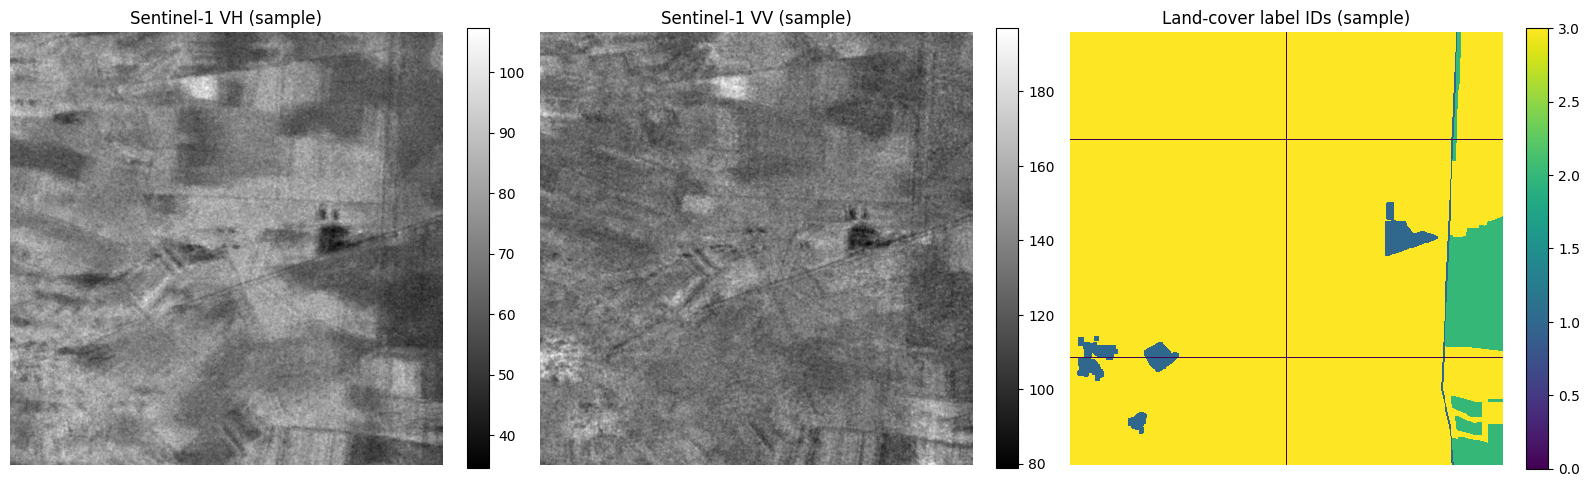


Inspection finished. Training has not started.


In [5]:

# Cell 12: Inspect the selected Sentinel-1 tile before training

!pip -q install rasterio huggingface_hub matplotlib

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
REPO_PATH = (
    "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"
)

print("Getting the selected tile...")
tif_path = hf_hub_download(
    repo_id=DATASET_ID,
    repo_type="dataset",
    filename=REPO_PATH
)

class_counts = {}
total_pixels = 0
radar_valid_pixels = 0
labelled_pixels = 0
joint_valid_pixels = 0
vv_values = []
vh_values = []

with rasterio.open(tif_path) as src:
    print("\nFILE:", os.path.basename(tif_path))
    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Band order:", src.descriptions)
    print("NoData values:", src.nodatavals)

    # Process the raster in blocks to avoid loading the full image into RAM.
    for _, window in src.block_windows(1):
        vh = src.read(1, window=window)
        vv = src.read(2, window=window)
        labels = src.read(3, window=window)

        valid_vh = np.isfinite(vh)
        valid_vv = np.isfinite(vv)
        valid_labels = np.isfinite(labels)

        if src.nodatavals[0] is not None:
            valid_vh &= vh != src.nodatavals[0]
        if src.nodatavals[1] is not None:
            valid_vv &= vv != src.nodatavals[1]
        if src.nodatavals[2] is not None:
            valid_labels &= labels != src.nodatavals[2]

        # Positive label IDs are treated as labelled pixels.
        labelled = valid_labels & (labels > 0)
        radar_valid = (
            valid_vh & valid_vv &
            (vh != 0) & (vv != 0)
        )
        joint = radar_valid & labelled

        total_pixels += labels.size
        radar_valid_pixels += int(radar_valid.sum())
        labelled_pixels += int(labelled.sum())
        joint_valid_pixels += int(joint.sum())

        ids, counts = np.unique(labels[labelled], return_counts=True)
        for class_id, count in zip(ids, counts):
            key = int(class_id)
            class_counts[key] = class_counts.get(key, 0) + int(count)

        # Keep a bounded sample for intensity statistics.
        vh_sample = vh[radar_valid]
        vv_sample = vv[radar_valid]
        if vh_sample.size:
            stride = max(1, vh_sample.size // 5000)
            vh_values.extend(vh_sample[::stride].tolist())
            vv_values.extend(vv_sample[::stride].tolist())

    print("\n" + "=" * 60)
    print("COVERAGE")
    print("=" * 60)
    print(f"Total pixels: {total_pixels:,}")
    print(
        f"Pixels with both radar bands nonzero: {radar_valid_pixels:,} "
        f"({100 * radar_valid_pixels / total_pixels:.2f}%)"
    )
    print(
        f"Positive-label pixels: {labelled_pixels:,} "
        f"({100 * labelled_pixels / total_pixels:.2f}%)"
    )
    print(
        f"Pixels with radar data AND positive labels: {joint_valid_pixels:,} "
        f"({100 * joint_valid_pixels / total_pixels:.2f}%)"
    )

    print("\n" + "=" * 60)
    print("LABEL CLASS DISTRIBUTION")
    print("=" * 60)
    for class_id in sorted(class_counts):
        count = class_counts[class_id]
        percentage = 100 * count / max(labelled_pixels, 1)
        print(
            f"Class ID {class_id}: {count:,} pixels "
            f"({percentage:.2f}% of positive labels)"
        )

    print("\n" + "=" * 60)
    print("RADAR VALUE SUMMARY")
    print("=" * 60)
    if vv_values and vh_values:
        print("VV sampled min/max/mean:",
              float(np.min(vv_values)),
              float(np.max(vv_values)),
              float(np.mean(vv_values)))
        print("VH sampled min/max/mean:",
              float(np.min(vh_values)),
              float(np.max(vh_values)),
              float(np.mean(vh_values)))

    # Read a central window for visual inspection.
    sample_size = 512
    row_start = max(0, (src.height - sample_size) // 2)
    col_start = max(0, (src.width - sample_size) // 2)
    window = rasterio.windows.Window(
        col_start, row_start,
        min(sample_size, src.width - col_start),
        min(sample_size, src.height - row_start)
    )

    vh_map = src.read(1, window=window)
    vv_map = src.read(2, window=window)
    label_map = src.read(3, window=window)

# Plot sample maps. Class IDs are shown without assigning names prematurely.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(vh_map, cmap="gray")
axes[0].set_title("Sentinel-1 VH (sample)")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(vv_map, cmap="gray")
axes[1].set_title("Sentinel-1 VV (sample)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(label_map, interpolation="nearest")
axes[2].set_title("Land-cover label IDs (sample)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print("\nInspection finished. Training has not started.")


In [7]:
import os

print("tif_path defined:", "tif_path" in globals())

if "tif_path" in globals():
    print("Path:", tif_path)
    print("File exists:", os.path.isfile(tif_path))

tif_path defined: True
Path: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
File exists: True


Typology images found:
- images/typology_AI4LCC.png


images/typology_AI4LCC.png: reconstructing file:   0%|          |  0.00B / 81.9kB            

images/typology_AI4LCC.png: downloading bytes:           |  0.00B            


Displaying: typology_AI4LCC.png


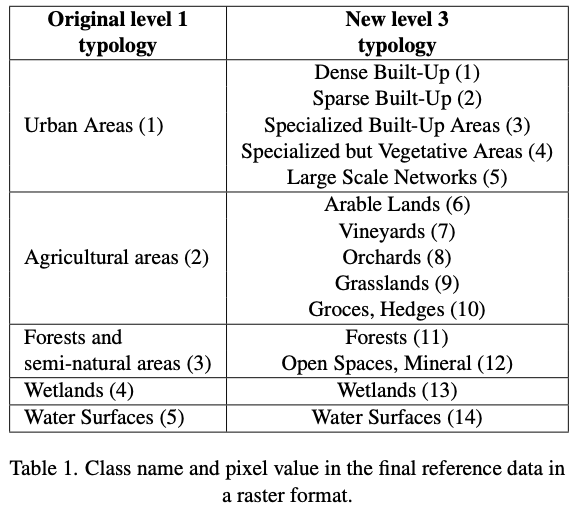


Do not assign class names or train yet.


In [20]:

# Cell 13: Find and display the official AI4LCC class typology

from huggingface_hub import HfApi, hf_hub_download
from IPython.display import display, Image
import os

DATASET_ID = "wtr001/S1_AI4LCC"

api = HfApi()
repo_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

image_files = [
    name for name in repo_files
    if "typology" in name.lower()
    and name.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]

print("Typology images found:")
for name in image_files:
    print("-", name)

if image_files:
    image_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=image_files[0]
    )
    print("\nDisplaying:", os.path.basename(image_path))
    display(Image(filename=image_path))
else:
    print("\nNo typology image found. Listing README and metadata files:")
    for name in repo_files:
        if name.lower().endswith((".md", ".json", ".csv")):
            print("-", name)

print("\nDo not assign class names or train yet.")


In [6]:

# Cell 14: Define the verified classes and training configuration

import torch

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

NUM_CLASSES = 5
IGNORE_LABEL = 0

# Model configuration
PATCH_SIZE = 256
BATCH_SIZE = 8
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3

# Input channels: Sentinel-1 VH and VV only
INPUT_CHANNELS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nLand-cover classes:")
for class_id, class_name in CLASS_NAMES.items():
    print(f"  {class_id}: {class_name}")

print("\nTraining configuration:")
print("Input channels:", INPUT_CHANNELS, "(VH, VV)")
print("Number of classes:", NUM_CLASSES)
print("Ignored label:", IGNORE_LABEL)
print("Patch size:", PATCH_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)

print("\nConfiguration ready. No training has started.")


Device: cpu

Land-cover classes:
  1: Urban areas
  2: Agricultural areas
  3: Forests and semi-natural areas
  4: Wetlands
  5: Water surfaces

Training configuration:
Input channels: 2 (VH, VV)
Number of classes: 5
Ignored label: 0
Patch size: 256
Batch size: 8
Epochs: 15
Learning rate: 0.001

Configuration ready. No training has started.


In [8]:

# Cell 15: Rebuild spatially separated training/validation patches

import os
import numpy as np
import rasterio
from tqdm.auto import tqdm

# 1. Check required inputs
assert "tif_path" in globals(), "Run Cell 12 first."
assert "CLASS_NAMES" in globals(), "Run Cell 14 first."
assert os.path.isfile(tif_path), f"GeoTIFF not found: {tif_path}"

# Expected five-class mapping
print("Class mapping:", CLASS_NAMES)
print("Source GeoTIFF:", tif_path)

# 2. Configuration
OUTPUT_DIR = "/content/lulc_training_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PATCH_SIZE = 256
STRIDE = 256
VALIDATION_FRACTION = 0.20
MIN_RADAR_VALID_FRACTION = 0.80
MIN_LABELLED_VALID_FRACTION = 0.25

train_images, train_labels, train_masks = [], [], []
val_images, val_labels, val_masks = [], [], []

# 3. Extract patches from the source GeoTIFF
with rasterio.open(tif_path) as src:
    height, width = src.height, src.width

    if src.count < 3:
        raise ValueError(
            f"Expected at least 3 bands (VH, VV, labels); found {src.count}."
        )

    split_col = int(width * (1 - VALIDATION_FRACTION))

    row_starts = range(0, height - PATCH_SIZE + 1, STRIDE)
    col_starts = range(0, width - PATCH_SIZE + 1, STRIDE)

    print("Dimensions:", height, "x", width)
    print("Training columns: 0 to", split_col)
    print("Validation columns:", split_col, "to", width)
    print("CRS:", src.crs)

    for row in tqdm(row_starts, desc="Extracting patches"):
        for col in col_starts:

            # Keep training and validation spatially separated
            if col + PATCH_SIZE <= split_col:
                destination = "train"
            elif col >= split_col:
                destination = "val"
            else:
                continue

            window = rasterio.windows.Window(
                col, row, PATCH_SIZE, PATCH_SIZE
            )

            # Original dataset band order: VH, VV, labels
            vh = src.read(1, window=window).astype(np.float32)
            vv = src.read(2, window=window).astype(np.float32)
            labels = src.read(3, window=window)

            radar_valid = (
                np.isfinite(vh) &
                np.isfinite(vv) &
                (vh != 0) &
                (vv != 0)
            )

            label_valid = (
                np.isfinite(labels) &
                np.isin(labels, list(CLASS_NAMES.keys()))
            )

            supervised_valid = radar_valid & label_valid

            if radar_valid.mean() < MIN_RADAR_VALID_FRACTION:
                continue

            if supervised_valid.mean() < MIN_LABELLED_VALID_FRACTION:
                continue

            # Label 0 is reserved for ignored/unlabelled pixels
            clean_labels = np.zeros(labels.shape, dtype=np.uint8)
            clean_labels[supervised_valid] = (
                labels[supervised_valid].astype(np.uint8)
            )

            image = np.stack([vh, vv], axis=0)
            invalid_mask = ~radar_valid

            if destination == "train":
                train_images.append(image)
                train_labels.append(clean_labels)
                train_masks.append(invalid_mask)
            else:
                val_images.append(image)
                val_labels.append(clean_labels)
                val_masks.append(invalid_mask)

# 4. Validate extracted patches
if not train_images or not val_images:
    raise RuntimeError(
        f"Insufficient patches: train={len(train_images)}, "
        f"validation={len(val_images)}. Check the source data."
    )

X_train = np.stack(train_images).astype(np.float32)
y_train = np.stack(train_labels).astype(np.uint8)
invalid_train = np.stack(train_masks)

X_val = np.stack(val_images).astype(np.float32)
y_val = np.stack(val_labels).astype(np.uint8)
invalid_val = np.stack(val_masks)

print("\nRaw training shape:", X_train.shape)
print("Raw validation shape:", X_val.shape)

# 5. Compute normalization statistics from valid training pixels only
stats_mask = (y_train > 0) & (~invalid_train)

means = np.zeros(2, dtype=np.float32)
stds = np.ones(2, dtype=np.float32)

for channel in range(2):
    values = X_train[:, channel][stats_mask]

    if values.size == 0:
        raise RuntimeError(
            f"No usable training values in channel {channel}."
        )

    means[channel] = values.mean()
    stds[channel] = max(values.std(), 1e-6)

print("Normalization means (VH, VV):", means)
print("Normalization stds (VH, VV):", stds)

# 6. Apply the same normalization to train and validation
for images, invalid_mask in (
    (X_train, invalid_train),
    (X_val, invalid_val)
):
    for channel in range(2):
        images[:, channel] = (
            images[:, channel] - means[channel]
        ) / stds[channel]

        # Keep invalid radar pixels at zero after normalization
        images[:, channel][invalid_mask] = 0.0

# 7. Save arrays and normalization parameters
np.save(os.path.join(OUTPUT_DIR, "X_train.npy"), X_train)
np.save(os.path.join(OUTPUT_DIR, "y_train.npy"), y_train)
np.save(os.path.join(OUTPUT_DIR, "X_val.npy"), X_val)
np.save(os.path.join(OUTPUT_DIR, "y_val.npy"), y_val)

np.savez(
    os.path.join(OUTPUT_DIR, "normalization.npz"),
    means=means,
    stds=stds
)

# 8. Report class counts and verify saved files
print("\nTRAINING PATCHES:", X_train.shape)
print("VALIDATION PATCHES:", X_val.shape)

print("\nTraining label counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_id} - {class_name}: "
        f"{(y_train == class_id).sum():,}"
    )

print("\nValidation label counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_id} - {class_name}: "
        f"{(y_val == class_id).sum():,}"
    )

required_files = [
    "X_train.npy",
    "y_train.npy",
    "X_val.npy",
    "y_val.npy",
    "normalization.npz"
]

missing_files = [
    name for name in required_files
    if not os.path.isfile(os.path.join(OUTPUT_DIR, name))
]

if missing_files:
    raise RuntimeError(f"Files failed to save: {missing_files}")

print("\nSaved dataset to:", OUTPUT_DIR)
print("Verified files:", sorted(os.listdir(OUTPUT_DIR)))
print("Cell 15 completed successfully.")


Class mapping: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}
Source GeoTIFF: /root/.cache/huggingface/hub/datasets--wtr001--S1_AI4LCC/snapshots/9f0e61b70b57447c97a05840a50ceae50def5943/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
Dimensions: 5390 x 3077
Training columns: 0 to 2461
Validation columns: 2461 to 3077
CRS: EPSG:32630


Extracting patches:   0%|          | 0/21 [00:00<?, ?it/s]


Raw training shape: (173, 2, 256, 256)
Raw validation shape: (42, 2, 256, 256)
Normalization means (VH, VV): [ 68.72029 126.65641]
Normalization stds (VH, VV): [19.140371 35.750645]

TRAINING PATCHES: (173, 2, 256, 256)
VALIDATION PATCHES: (42, 2, 256, 256)

Training label counts:
1 - Urban areas: 1,344,092
2 - Agricultural areas: 480,866
3 - Forests and semi-natural areas: 7,963,965
4 - Wetlands: 114,280
5 - Water surfaces: 1,217,494

Validation label counts:
1 - Urban areas: 203,588
2 - Agricultural areas: 483,617
3 - Forests and semi-natural areas: 2,027,392
4 - Wetlands: 501
5 - Water surfaces: 2,542

Saved dataset to: /content/lulc_training_data
Verified files: ['X_train.npy', 'X_val.npy', 'normalization.npz', 'y_train.npy', 'y_val.npy']
Cell 15 completed successfully.


In [9]:

# Cell 16: Retrain U-Net with updated class weights

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/lulc_training_data"

# Keep the original baseline checkpoint safe
MODEL_PATH = "/content/best_sentinel1_unet_v2.pth"

PATCH_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 15
LEARNING_RATE = 0.001
NUM_CLASSES = 5
IGNORE_INDEX = 255

# Load regenerated patches
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy")).astype(np.float32)
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy")).astype(np.uint8)
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.uint8)

assert X_train.shape[1:] == (2, 256, 256)
assert X_val.shape[1:] == (2, 256, 256)
assert len(X_train) == 173 and len(X_val) == 42

# Dataset: source labels 1-5 become model indices 0-4.
# Label 0 is ignored.
class LULCPatchDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images.copy())
        converted = labels.astype(np.int64).copy()
        converted[converted > 0] -= 1
        converted[labels == 0] = IGNORE_INDEX
        self.labels = torch.from_numpy(converted)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]

train_dataset = LULCPatchDataset(X_train, y_train)
val_dataset = LULCPatchDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Same U-Net architecture as the baseline
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bridge = DoubleConv(128, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        self.out = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bridge(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

# Updated weights in order: Urban, Agriculture, Forest, Wetlands, Water
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)

model = UNet(in_channels=2, num_classes=NUM_CLASSES).to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

norm = np.load(os.path.join(DATA_DIR, "normalization.npz"))
means = norm["means"].copy()
stds = norm["stds"].copy()

print("Device:", DEVICE)
print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Updated class weights:", class_weights.detach().cpu().numpy())
print("Model parameters:", sum(p.numel() for p in model.parameters()))

best_val_loss = float("inf")
best_epoch = -1
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()
        train_batches += 1

    model.eval()
    val_loss_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item()
            val_batches += 1

            valid = labels != IGNORE_INDEX
            predictions = logits.argmax(dim=1)
            correct += ((predictions == labels) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_loss_sum / max(train_batches, 1)
    val_loss = val_loss_sum / max(val_batches, 1)
    val_accuracy = correct / max(evaluated, 1)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val pixel accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_names": CLASS_NAMES,
            "class_weights": class_weights.detach().cpu(),
            "normalization_means": means,
            "normalization_stds": stds,
            "input_channels": ["VH", "VV"],
            "num_classes": NUM_CLASSES
        }, MODEL_PATH)

        print("  Saved best model:", MODEL_PATH)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Best model file:", MODEL_PATH)


Device: cpu
Training patches: 173
Validation patches: 42
Updated class weights: [0.45 1.1  0.6  2.5  0.9 ]
Model parameters: 1926853
Epoch 01/15 | Train loss: 1.2136 | Val loss: 1.5380 | Val pixel accuracy: 0.3154
  Saved best model: /content/best_sentinel1_unet_v2.pth
Epoch 02/15 | Train loss: 0.9617 | Val loss: 1.3518 | Val pixel accuracy: 0.4543
  Saved best model: /content/best_sentinel1_unet_v2.pth
Epoch 03/15 | Train loss: 0.8096 | Val loss: 1.8318 | Val pixel accuracy: 0.2433
Epoch 04/15 | Train loss: 0.7496 | Val loss: 1.0379 | Val pixel accuracy: 0.4975
  Saved best model: /content/best_sentinel1_unet_v2.pth
Epoch 05/15 | Train loss: 0.6487 | Val loss: 1.1813 | Val pixel accuracy: 0.6877
Epoch 06/15 | Train loss: 0.6448 | Val loss: 1.0417 | Val pixel accuracy: 0.4581
Epoch 07/15 | Train loss: 0.6084 | Val loss: 0.8891 | Val pixel accuracy: 0.7033
  Saved best model: /content/best_sentinel1_unet_v2.pth
Epoch 08/15 | Train loss: 0.5846 | Val loss: 1.1617 | Val pixel accuracy: 0.

In [10]:

import os
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet_v2.pth"
device = torch.device("cpu")

# Load validation arrays; X_val is already normalized
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.int64)

# Load the new best checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

model = UNet(in_channels=2, num_classes=5).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Convert source label IDs 1-5 to model indices 0-4.
# Ignore label 0.
y_eval = y_val.copy()
y_eval[y_eval > 0] -= 1
y_eval[y_val == 0] = 255

all_true, all_pred = [], []

with torch.no_grad():
    for start in range(0, len(X_val), 4):
        xb = torch.from_numpy(X_val[start:start + 4]).to(device)
        predictions = model(xb).argmax(dim=1).cpu().numpy()
        truth = y_eval[start:start + 4]

        valid = truth != 255
        all_true.extend(truth[valid].tolist())
        all_pred.extend(predictions[valid].tolist())

names = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]

print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Checkpoint validation loss:", checkpoint.get("val_loss", "unknown"))
print("Overall accuracy:", round(
    np.mean(np.array(all_true) == np.array(all_pred)), 4
))

print("\nClassification report:")
print(classification_report(
    all_true,
    all_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=names,
    zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    all_true,
    all_pred,
    labels=[0, 1, 2, 3, 4]
))


Checkpoint epoch: 13
Checkpoint validation loss: 0.8890116711457571
Overall accuracy: 0.7244

Classification report:
                     precision    recall  f1-score   support

              Urban       0.31      0.22      0.26    203588
        Agriculture       0.55      0.73      0.63    483617
Forest/semi-natural       0.91      0.77      0.84   2027392
           Wetlands       0.00      0.00      0.00       501
              Water       0.01      0.55      0.01      2542

           accuracy                           0.72   2717640
          macro avg       0.36      0.46      0.35   2717640
       weighted avg       0.80      0.72      0.76   2717640

Confusion matrix (rows=true, columns=predicted):
[[  45626   73583   70415       0   13964]
 [   7962  354545   80116       0   40994]
 [  91841  216372 1567076       0  152103]
 [    233      41     206       0      21]
 [    640      52     446       0    1404]]


In [11]:
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

backup_dir = "/content/drive/MyDrive/Sentinel1_LULC_Project"
os.makedirs(backup_dir, exist_ok=True)

model_path = "/content/best_sentinel1_unet_v2.pth"
backup_path = os.path.join(
    backup_dir, "best_sentinel1_unet_v2.pth"
)

shutil.copy2(model_path, backup_path)

print("Model backed up successfully:", backup_path)

Mounted at /content/drive
Model backed up successfully: /content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth


In [2]:
import os

DATA_DIR = "/content/lulc_training_data"

print("Folder exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Files found:", os.listdir(DATA_DIR))
else:
    print("Training data folder is missing.")

Folder exists: False
Training data folder is missing.


In [3]:
import os
import numpy as np

DATA_DIR = "/content/lulc_training_data"

print("Folder exists:", os.path.exists(DATA_DIR))

for name in ["X_train.npy", "y_train.npy", "X_val.npy", "y_val.npy"]:
    path = os.path.join(DATA_DIR, name)
    print(name, "exists:", os.path.exists(path))
    if os.path.exists(path):
        arr = np.load(path, mmap_mode="r")
        print("  Shape:", arr.shape, "| Data type:", arr.dtype)

Folder exists: False
X_train.npy exists: False
y_train.npy exists: False
X_val.npy exists: False
y_val.npy exists: False


VALIDATION METRICS
Valid evaluated pixels: 2,717,640
Overall accuracy (OA): 0.5526 (55.26%)
Mean IoU (mIoU): 0.2519 (25.19%)

PER-CLASS METRICS
---------------------------------------------------------------------------
Class                                  Support         IoU          F1
Urban areas                            203,588      0.1322      0.2335
Agricultural areas                     483,617      0.5448      0.7053
Forests and semi-natural areas       2,027,392      0.4619      0.6320
Wetlands                                   501      0.0000      0.0000
Water surfaces                           2,542      0.1206      0.2152

CONFUSION MATRIX
Rows = actual class; columns = predicted class
Class order: ['Urban areas', 'Agricultural areas', 'Forests and semi-natural areas', 'Wetlands', 'Water surfaces']
[[148820  28881  25145     12    730]
 [ 56196 386421  37641      8   3351]
 [864137 196759 965587     25    884]
 [   430     12     59      0      0]
 [  1590      4     43

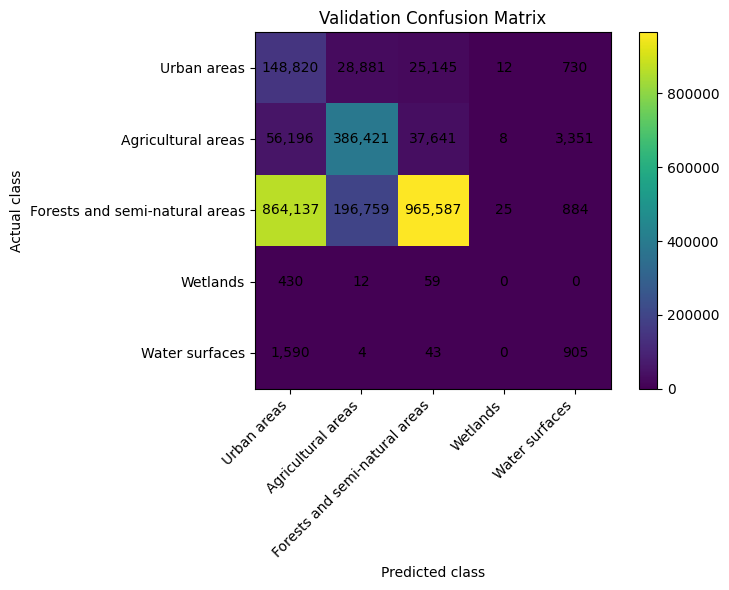


Evaluation complete. Metrics are for this held-out spatial region only.


In [24]:

# Cell 17: Evaluate the saved best U-Net checkpoint

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/content/best_sentinel1_unet.pth"
DATA_DIR = "/content/lulc_training_data"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError("Best model checkpoint not found. Run Cell 16 first.")

# Load validation arrays.
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.uint8)

# Recreate the same model architecture used for training.
model = UNet(in_channels=2, num_classes=5).to(DEVICE)

# weights_only=False is required here because the checkpoint also contains
# metadata beyond the model tensors. Only load your own trusted checkpoint.
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Dataset labels 1–5 map to prediction indices 0–4.
# Unlabelled pixels (0) map to 255 and are excluded from metrics.
y_eval = y_val.astype(np.int64)
y_eval[y_eval > 0] -= 1
y_eval[y_val == 0] = 255

all_true = []
all_pred = []

with torch.no_grad():
    for start in range(0, len(X_val), 8):
        images = torch.from_numpy(
            X_val[start:start + 8]
        ).to(DEVICE)

        logits = model(images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        true_batch = y_eval[start:start + 8]
        valid = true_batch != 255

        all_true.append(true_batch[valid])
        all_pred.append(predictions[valid])

y_true = np.concatenate(all_true)
y_pred = np.concatenate(all_pred)

NUM_CLASSES = 5
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

for true_class, pred_class in zip(y_true, y_pred):
    confusion[true_class, pred_class] += 1

true_counts = confusion.sum(axis=1)
pred_counts = confusion.sum(axis=0)
true_positive = np.diag(confusion)
false_positive = pred_counts - true_positive
false_negative = true_counts - true_positive

denominator_iou = true_positive + false_positive + false_negative
denominator_f1 = 2 * true_positive + false_positive + false_negative

iou = np.divide(
    true_positive,
    denominator_iou,
    out=np.full(NUM_CLASSES, np.nan, dtype=float),
    where=denominator_iou > 0
)

f1 = np.divide(
    2 * true_positive,
    denominator_f1,
    out=np.full(NUM_CLASSES, np.nan, dtype=float),
    where=denominator_f1 > 0
)

overall_accuracy = true_positive.sum() / max(confusion.sum(), 1)
mean_iou = np.nanmean(iou)

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

print("=" * 75)
print("VALIDATION METRICS")
print("=" * 75)
print(f"Valid evaluated pixels: {confusion.sum():,}")
print(f"Overall accuracy (OA): {overall_accuracy:.4f} ({overall_accuracy * 100:.2f}%)")
print(f"Mean IoU (mIoU): {mean_iou:.4f} ({mean_iou * 100:.2f}%)")

print("\nPER-CLASS METRICS")
print("-" * 75)
print(f"{'Class':<34}{'Support':>12}{'IoU':>12}{'F1':>12}")
for index in range(NUM_CLASSES):
    class_name = CLASS_NAMES[index + 1]
    print(
        f"{class_name:<34}"
        f"{true_counts[index]:>12,}"
        f"{iou[index]:>12.4f}"
        f"{f1[index]:>12.4f}"
    )

print("\nCONFUSION MATRIX")
print("Rows = actual class; columns = predicted class")
print("Class order:", [CLASS_NAMES[i] for i in range(1, 6)])
print(confusion)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(confusion, interpolation="nearest")
ax.set_title("Validation Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(
    [CLASS_NAMES[i] for i in range(1, 6)],
    rotation=45, ha="right"
)
ax.set_yticklabels([CLASS_NAMES[i] for i in range(1, 6)])

for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        ax.text(
            col, row, f"{confusion[row, col]:,}",
            ha="center", va="center"
        )

fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print("\nEvaluation complete. Metrics are for this held-out spatial region only.")


TRAINING PATCH CLASS COVERAGE
Urban areas                        pixels= 1,344,092 | patches containing class=147/173
Agricultural areas                 pixels=   480,866 | patches containing class=129/173
Forests and semi-natural areas     pixels= 7,963,965 | patches containing class=168/173
Wetlands                           pixels=   114,280 | patches containing class= 39/173
Water surfaces                     pixels= 1,217,494 | patches containing class= 70/173

VALIDATION PATCH CLASS COVERAGE
Urban areas                        pixels=   203,588 | patches containing class= 36/42
Agricultural areas                 pixels=   483,617 | patches containing class= 40/42
Forests and semi-natural areas     pixels= 2,027,392 | patches containing class= 42/42
Wetlands                           pixels=       501 | patches containing class=  2/42
Water surfaces                     pixels=     2,542 | patches containing class=  7/42


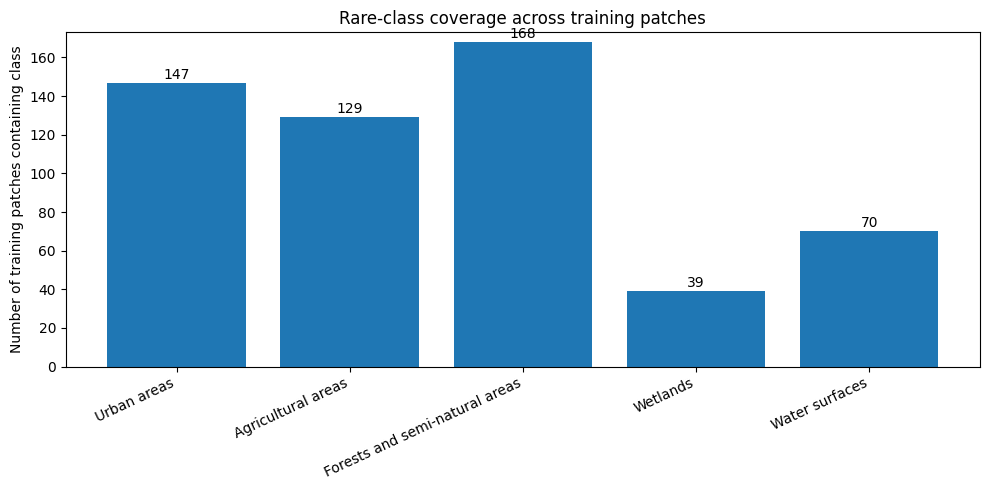


Diagnosis complete. Existing model checkpoint unchanged.


In [25]:

# Cell 18: Diagnose class distribution across training patches

import os
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/lulc_training_data"

y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

print("=" * 70)
print("TRAINING PATCH CLASS COVERAGE")
print("=" * 70)

patch_counts = {}
pixel_counts = {}

for class_id, class_name in CLASS_NAMES.items():
    per_patch = (y_train == class_id).sum(axis=(1, 2))
    patches_present = int((per_patch > 0).sum())
    pixels_total = int(per_patch.sum())

    patch_counts[class_id] = patches_present
    pixel_counts[class_id] = pixels_total

    print(
        f"{class_name:<34} "
        f"pixels={pixels_total:>10,} | "
        f"patches containing class={patches_present:>3}/{len(y_train)}"
    )

print("\n" + "=" * 70)
print("VALIDATION PATCH CLASS COVERAGE")
print("=" * 70)

for class_id, class_name in CLASS_NAMES.items():
    per_patch = (y_val == class_id).sum(axis=(1, 2))
    patches_present = int((per_patch > 0).sum())
    pixels_total = int(per_patch.sum())

    print(
        f"{class_name:<34} "
        f"pixels={pixels_total:>10,} | "
        f"patches containing class={patches_present:>3}/{len(y_val)}"
    )

class_ids = list(CLASS_NAMES.keys())
names = [CLASS_NAMES[i] for i in class_ids]
counts = [patch_counts[i] for i in class_ids]

plt.figure(figsize=(10, 5))
bars = plt.bar(names, counts)
plt.ylabel("Number of training patches containing class")
plt.title("Rare-class coverage across training patches")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, len(y_train))
for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(count),
        ha="center"
    )
plt.tight_layout()
plt.show()

print("\nDiagnosis complete. Existing model checkpoint unchanged.")


In [29]:
S

Model exists: True
X_val.npy exists: True
y_val.npy exists: True
normalization.npz exists: True
X_val shape: (42, 2, 256, 256)
y_val shape: (42, 256, 256)
Unique validation labels: [0 1 2 3 4 5]


In [45]:
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=device
)
criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Updated class weights:", criterion.weight)

Updated class weights: tensor([0.4500, 1.1000, 0.6000, 2.5000, 0.9000])


In [30]:
import numpy as np

print("Validation label distribution:")

labels, counts = np.unique(y_val, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count:,} pixels")

print("\nCheckpoint class names and metadata:")

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))
print("Number of model classes:", checkpoint.get("num_classes", "Not stored"))
print("Class names:", checkpoint.get("class_names", "Not stored"))

Validation label distribution:
Label 0: 34,872 pixels
Label 1: 203,588 pixels
Label 2: 483,617 pixels
Label 3: 2,027,392 pixels
Label 4: 501 pixels
Label 5: 2,542 pixels

Checkpoint class names and metadata:
Checkpoint keys: ['model_state_dict', 'class_names', 'class_weights', 'normalization_means', 'normalization_stds', 'input_channels', 'num_classes']
Number of model classes: 5
Class names: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}


In [31]:
import numpy as np
import os

DATA_DIR = "/content/lulc_training_data"

for filename in ["y_train.npy", "y_val.npy"]:
    path = os.path.join(DATA_DIR, filename)
    labels_array = np.load(path)

    labels, counts = np.unique(labels_array, return_counts=True)

    print(f"\n{filename}")
    total = counts.sum()

    for label, count in zip(labels, counts):
        print(
            f"Label {label}: {count:,} pixels "
            f"({count / total * 100:.2f}%)"
        )


y_train.npy
Label 0: 217,031 pixels (1.91%)
Label 1: 1,344,092 pixels (11.86%)
Label 2: 480,866 pixels (4.24%)
Label 3: 7,963,965 pixels (70.24%)
Label 4: 114,280 pixels (1.01%)
Label 5: 1,217,494 pixels (10.74%)

y_val.npy
Label 0: 34,872 pixels (1.27%)
Label 1: 203,588 pixels (7.40%)
Label 2: 483,617 pixels (17.57%)
Label 3: 2,027,392 pixels (73.66%)
Label 4: 501 pixels (0.02%)
Label 5: 2,542 pixels (0.09%)


In [32]:
import os

DATA_DIR = "/content/lulc_training_data"

for filename in os.listdir(DATA_DIR):
    print(filename)

X_train.npy
y_val.npy
y_train.npy
normalization.npz
X_val.npy


In [33]:
import numpy as np
import torch

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet.pth"

# Inspect normalization metadata
norm = np.load(f"{DATA_DIR}/normalization.npz")

print("Normalization keys:", norm.files)
for key in norm.files:
    print(key, norm[key])

# Inspect model output dimensions
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nModel input channels:", checkpoint["input_channels"])
print("Model output classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])

Normalization keys: ['means', 'stds']
means [ 68.72029 126.65641]
stds [19.140371 35.750645]

Model input channels: ['VH', 'VV']
Model output classes: 5
Class names: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}


In [34]:
import torch
import numpy as np

checkpoint = torch.load(
    "/content/best_sentinel1_unet.pth",
    map_location="cpu",
    weights_only=False
)

# Inspect the model's final output layer
for key, value in checkpoint["model_state_dict"].items():
    if "out" in key.lower() or "final" in key.lower():
        print(key, tuple(value.shape))

# Inspect labels and confirm the number of output channels
for name in ["y_train.npy", "y_val.npy"]:
    y = np.load(f"/content/lulc_training_data/{name}")
    print(f"\n{name}: unique labels = {np.unique(y)}")

print("\nExpected output classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])

out.weight (5, 32, 1, 1)
out.bias (5,)

y_train.npy: unique labels = [0 1 2 3 4 5]

y_val.npy: unique labels = [0 1 2 3 4 5]

Expected output classes: 5
Class names: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}


In [35]:
import numpy as np

DATA_DIR = "/content/lulc_training_data"

for name in ["y_train.npy", "y_val.npy"]:
    y = np.load(f"{DATA_DIR}/{name}")

    print(f"\n{name}")
    print("Shape:", y.shape)
    print("Minimum:", y.min(), "Maximum:", y.max())
    print("Unique labels:", np.unique(y))

    # Check a few individual patches
    for i in range(min(3, len(y))):
        labels, counts = np.unique(y[i], return_counts=True)
        print(f"Patch {i}:", dict(zip(labels.tolist(), counts.tolist())))


y_train.npy
Shape: (173, 256, 256)
Minimum: 0 Maximum: 5
Unique labels: [0 1 2 3 4 5]
Patch 0: {0: 17105, 1: 11454, 2: 589, 3: 851, 4: 680, 5: 34857}
Patch 1: {0: 5404, 1: 23414, 3: 5213, 5: 31505}
Patch 2: {0: 491, 1: 29625, 2: 433, 3: 34986, 4: 1}

y_val.npy
Shape: (42, 256, 256)
Minimum: 0 Maximum: 5
Unique labels: [0 1 2 3 4 5]
Patch 0: {0: 511, 1: 16874, 2: 2200, 3: 44806, 4: 321, 5: 824}
Patch 1: {0: 511, 1: 718, 2: 1330, 3: 62977}
Patch 2: {0: 511, 1: 20273, 2: 1292, 3: 42999, 4: 180, 5: 281}


In [36]:
print("map_labels exists:", "map_labels" in globals())
print("remap_labels exists:", "remap_labels" in globals())
print("IGNORE_INDEX:", globals().get("IGNORE_INDEX", "Not defined"))
print("ignore_index:", globals().get("ignore_index", "Not defined"))

map_labels exists: False
remap_labels exists: False
IGNORE_INDEX: Not defined
ignore_index: Not defined


In [37]:
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet_v2.pth"

device = torch.device("cpu")

# Load validation data
X_val = np.load(f"{DATA_DIR}/X_val.npy").astype(np.float32)
y_val = np.load(f"{DATA_DIR}/y_val.npy")

# Load the best checkpoint into the existing model
checkpoint = torch.load(
    MODEL_PATH, map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Normalize using saved training statistics
norm = np.load(f"{DATA_DIR}/normalization.npz")
X_val = (X_val - norm["means"][None, :, None, None]) / (
    norm["stds"][None, :, None, None] + 1e-8
)

all_true, all_pred = [], []

with torch.no_grad():
    for start in range(0, len(X_val), 4):
        xb = torch.from_numpy(X_val[start:start+4]).to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        for j, pred in enumerate(preds):
            truth = y_val[start+j]
            valid = (truth >= 1) & (truth <= 5)

            all_true.extend((truth[valid] - 1).tolist())
            all_pred.extend(pred[valid].tolist())

names = [
    "Urban", "Agriculture", "Forest/semi-natural",
    "Wetlands", "Water"
]

print("Confusion matrix:")
print(confusion_matrix(all_true, all_pred, labels=range(5)))

print("\nClassification report:")
print(classification_report(
    all_true, all_pred,
    labels=range(5),
    target_names=names,
    zero_division=0
))

Confusion matrix:
[[      0       0       0       0  203588]
 [      0       0       1       0  483616]
 [      0       0      12       0 2027380]
 [      0       0       0       0     501]
 [      0       0       0       0    2542]]

Classification report:
                     precision    recall  f1-score   support

              Urban       0.00      0.00      0.00    203588
        Agriculture       0.00      0.00      0.00    483617
Forest/semi-natural       0.92      0.00      0.00   2027392
           Wetlands       0.00      0.00      0.00       501
              Water       0.00      1.00      0.00      2542

           accuracy                           0.00   2717640
          macro avg       0.18      0.20      0.00   2717640
       weighted avg       0.69      0.00      0.00   2717640



In [38]:
import numpy as np
import torch

print("Model output classes:", checkpoint["num_classes"])
print("Checkpoint class names:", checkpoint["class_names"])

# Check prediction distribution on a few validation patches
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_val[:3]).float().to(device)
    logits = model(xb)
    preds = logits.argmax(dim=1).cpu().numpy()

print("\nPredicted label distribution:")
labels, counts = np.unique(preds, return_counts=True)
for label, count in zip(labels, counts):
    print(f"Output {label}: {count:,} pixels ({count / counts.sum() * 100:.2f}%)")

print("\nOriginal validation label distribution:")
labels, counts = np.unique(y_val[:3], return_counts=True)
for label, count in zip(labels, counts):
    print(f"Label {label}: {count:,} pixels ({count / counts.sum() * 100:.2f}%)")

Model output classes: 5
Checkpoint class names: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}

Predicted label distribution:
Output 2: 1 pixels (0.00%)
Output 4: 196,607 pixels (100.00%)

Original validation label distribution:
Label 0: 1,533 pixels (0.78%)
Label 1: 37,865 pixels (19.26%)
Label 2: 4,822 pixels (2.45%)
Label 3: 150,782 pixels (76.69%)
Label 4: 501 pixels (0.25%)
Label 5: 1,105 pixels (0.56%)


In [39]:
%history -n

   1:
# Cell 1: Check the project environment

import sys
import platform
import importlib.util

print("=" * 55)
print("SENTINEL-1 LULC PROJECT — ENVIRONMENT CHECK")
print("=" * 55)

print("Python version:", sys.version)
print("Platform:", platform.platform())

# Check PyTorch
if importlib.util.find_spec("torch") is not None:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)
    else:
        print("GPU not detected. Check Colab runtime settings.")
else:
    print("\nPyTorch is not installed.")

# Check core geospatial libraries
libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "rasterio",
    "geopandas",
    "sklearn",
    "huggingface_hub",
]

print("\nLibrary availability:")
for library in libraries:
    installed = importlib.util.find_spec(library) is not No

In [40]:
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet.pth"
device = torch.device("cpu")

# Load arrays exactly as saved: X_val is ALREADY normalized.
X_val = np.load(f"{DATA_DIR}/X_val.npy").astype(np.float32)
y_val = np.load(f"{DATA_DIR}/y_val.npy").astype(np.int64)

# Restore the original model architecture and best checkpoint.
checkpoint = torch.load(
    MODEL_PATH, map_location=device, weights_only=False
)
model = UNet(in_channels=2, num_classes=5).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Original label IDs 1–5 -> model indices 0–4.
# Label 0 is ignored.
y_eval = y_val.copy()
y_eval[y_eval > 0] -= 1
y_eval[y_val == 0] = 255

all_true, all_pred = [], []

with torch.no_grad():
    for start in range(0, len(X_val), 4):
        # IMPORTANT: Do not normalize X_val again.
        xb = torch.from_numpy(X_val[start:start+4]).to(device)
        predictions = model(xb).argmax(dim=1).cpu().numpy()

        truth = y_eval[start:start+4]
        valid = truth != 255

        all_true.extend(truth[valid].tolist())
        all_pred.extend(predictions[valid].tolist())

names = [
    "Urban", "Agriculture", "Forest/semi-natural",
    "Wetlands", "Water"
]

print("Overall accuracy:",
      round(np.mean(np.array(all_true) == np.array(all_pred)), 4))

print("\nClassification report:")
print(classification_report(
    all_true, all_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=names,
    zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4]))

Overall accuracy: 0.5526

Classification report:
                     precision    recall  f1-score   support

              Urban       0.14      0.73      0.23    203588
        Agriculture       0.63      0.80      0.71    483617
Forest/semi-natural       0.94      0.48      0.63   2027392
           Wetlands       0.00      0.00      0.00       501
              Water       0.15      0.36      0.22      2542

           accuracy                           0.55   2717640
          macro avg       0.37      0.47      0.36   2717640
       weighted avg       0.82      0.55      0.61   2717640

Confusion matrix (rows=true, columns=predicted):
[[148820  28881  25145     12    730]
 [ 56196 386421  37641      8   3351]
 [864137 196759 965587     25    884]
 [   430     12     59      0      0]
 [  1590      4     43      0    905]]


In [41]:
import numpy as np

names = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]

true_counts = np.bincount(all_true, minlength=5)
pred_counts = np.bincount(all_pred, minlength=5)

print("Class distribution in validation set:")
for i, name in enumerate(names):
    true_pct = 100 * true_counts[i] / len(all_true)
    pred_pct = 100 * pred_counts[i] / len(all_pred)

    print(
        f"{name:22s} | "
        f"True: {true_pct:6.2f}% | "
        f"Predicted: {pred_pct:6.2f}%"
    )

Class distribution in validation set:
Urban                  | True:   7.49% | Predicted:  39.42%
Agriculture            | True:  17.80% | Predicted:  22.52%
Forest/semi-natural    | True:  74.60% | Predicted:  37.84%
Wetlands               | True:   0.02% | Predicted:   0.00%
Water                  | True:   0.09% | Predicted:   0.22%


In [42]:
print("Model:", model.__class__.__name__)
print("Loss function:", criterion)
print("Class weights:", criterion.weight)
print("Ignore index:", criterion.ignore_index)

Model: UNet
Loss function: CrossEntropyLoss()
Class weights: tensor([0.6611, 1.1053, 0.2716, 2.2673, 0.6946])
Ignore index: 255


In [43]:
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Updated class weights:", criterion.weight)

Updated class weights: tensor([0.4500, 1.1000, 0.6000, 2.5000, 0.9000])


In [44]:
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Updated class weights:", criterion.weight)

Updated class weights: tensor([0.4500, 1.1000, 0.6000, 2.5000, 0.9000])


In [ ]:

# Cell 20: Fair evaluation of baseline vs class-aware sampling

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/lulc_training_data"

BASELINE_PATH = "/content/best_sentinel1_unet.pth"
BALANCED_PATH = "/content/best_sentinel1_unet_balanced.pth"

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

for path in [BASELINE_PATH, BALANCED_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing checkpoint: {path}")

X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.uint8)

# Convert label IDs 1–5 to model indices 0–4; ignore label 0.
y_true_all = y_val.astype(np.int64)
y_true_all[y_true_all > 0] -= 1
y_true_all[y_val == 0] = 255

def evaluate_checkpoint(checkpoint_path):
    model_eval = UNet(in_channels=2, num_classes=5).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
    model_eval.load_state_dict(checkpoint["model_state_dict"])
    model_eval.eval()

    confusion = np.zeros((5, 5), dtype=np.int64)

    with torch.no_grad():
        for start in range(0, len(X_val), 8):
            images = torch.from_numpy(
                X_val[start:start + 8]
            ).to(DEVICE)

            predictions = (
                model_eval(images)
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

            truths = y_true_all[start:start + 8]
            valid = truths != 255

            true_valid = truths[valid]
            pred_valid = predictions[valid]

            batch_counts = np.bincount(
                true_valid * 5 + pred_valid,
                minlength=25
            ).reshape(5, 5)

            confusion += batch_counts

    tp = np.diag(confusion).astype(np.float64)
    actual = confusion.sum(axis=1).astype(np.float64)
    predicted = confusion.sum(axis=0).astype(np.float64)

    union = actual + predicted - tp
    f1_denominator = actual + predicted

    iou = np.divide(
        tp, union,
        out=np.full(5, np.nan),
        where=union > 0
    )
    f1 = np.divide(
        2 * tp, f1_denominator,
        out=np.full(5, np.nan),
        where=f1_denominator > 0
    )

    oa = tp.sum() / max(confusion.sum(), 1)
    miou = np.nanmean(iou)

    return {
        "confusion": confusion,
        "oa": oa,
        "miou": miou,
        "iou": iou,
        "f1": f1,
        "support": actual,
        "predicted": predicted,
    }

baseline = evaluate_checkpoint(BASELINE_PATH)
balanced = evaluate_checkpoint(BALANCED_PATH)

print("=" * 85)
print("MODEL COMPARISON")
print("=" * 85)
print(f"{'Metric':<34}{'Baseline':>18}{'Balanced':>18}")
print("-" * 70)
print(
    f"{'Overall accuracy':<34}"
    f"{baseline['oa'] * 100:>17.2f}%"
    f"{balanced['oa'] * 100:>17.2f}%"
)
print(
    f"{'Mean IoU':<34}"
    f"{baseline['miou'] * 100:>17.2f}%"
    f"{balanced['miou'] * 100:>17.2f}%"
)

print("\nPER-CLASS COMPARISON")
print("-" * 85)
print(f"{'Class':<34}{'Base IoU':>12}{'New IoU':>12}{'Base F1':>12}{'New F1':>12}")

for index in range(5):
    name = CLASS_NAMES[index + 1]
    print(
        f"{name:<34}"
        f"{baseline['iou'][index] * 100:>11.2f}%"
        f"{balanced['iou'][index] * 100:>11.2f}%"
        f"{baseline['f1'][index] * 100:>11.2f}%"
        f"{balanced['f1'][index] * 100:>11.2f}%"
    )

print("\nBALANCED MODEL CONFUSION MATRIX")
print("Rows = actual class; columns = predicted class")
print(balanced["confusion"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, result, title in [
    (axes[0], baseline, "Baseline U-Net"),
    (axes[1], balanced, "Class-aware U-Net"),
]:
    im = ax.imshow(result["confusion"], interpolation="nearest")
    ax.set_title(
        f"{title}\nOA={result['oa'] * 100:.2f}%, "
        f"mIoU={result['miou'] * 100:.2f}%"
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xticklabels(
        [CLASS_NAMES[i] for i in range(1, 6)],
        rotation=45, ha="right"
    )
    ax.set_yticklabels([CLASS_NAMES[i] for i in range(1, 6)])

    for row in range(5):
        for col in range(5):
            ax.text(
                col, row, f"{result['confusion'][row, col]:,}",
                ha="center", va="center", fontsize=8
            )

    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

print("\nComparison complete.")
print("Both models were evaluated on the same spatial validation pixels.")


In [ ]:

# Cell 21: Find additional Sentinel-1 tiles for dataset expansion

from huggingface_hub import HfApi

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

api = HfApi()

files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

tif_files = sorted([
    f for f in files
    if f.startswith(FOLDER)
    and f.lower().endswith((".tif", ".tiff"))
])

print("Total GeoTIFF tiles found:", len(tif_files))
print("\nAvailable tiles:")
print("-" * 90)

for index, filename in enumerate(tif_files, start=1):
    print(f"{index:3}. {filename}")

print("\nListing complete. No files were downloaded or modified.")


In [ ]:

# Cell 22: Rank additional tiles by radar quality and rare-class coverage

import os
import numpy as np
import pandas as pd
import rasterio
from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
OUTPUT_CSV = "/content/additional_tile_screening.csv"

# Existing tile: do not use it as an additional independent tile.
EXISTING_TILE = "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"

api = HfApi()
repo_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

candidates = [
    f for f in sorted(repo_files)
    if f.startswith(FOLDER)
    and f.lower().endswith((".tif", ".tiff"))
    and os.path.basename(f) != EXISTING_TILE
]

results = []

print("Tiles to screen:", len(candidates))
print("This can take some time because tiles are large.\n")

for repo_path in tqdm(candidates, desc="Screening tiles"):
    try:
        local_path = hf_hub_download(
            repo_id=DATASET_ID,
            repo_type="dataset",
            filename=repo_path
        )

        with rasterio.open(local_path) as src:
            if src.count < 3:
                continue

            total_pixels = src.width * src.height
            radar_pixels = 0
            labelled_radar_pixels = 0
            class_counts = {i: 0 for i in range(1, 6)}

            for _, window in src.block_windows(1):
                vh = src.read(1, window=window)
                vv = src.read(2, window=window)
                labels = src.read(3, window=window)

                vh_valid = np.isfinite(vh) & (vh != 0)
                vv_valid = np.isfinite(vv) & (vv != 0)
                radar_valid = vh_valid & vv_valid

                label_valid = (
                    np.isfinite(labels) &
                    np.isin(labels, [1, 2, 3, 4, 5])
                )
                supervised = radar_valid & label_valid

                radar_pixels += int(radar_valid.sum())
                labelled_radar_pixels += int(supervised.sum())

                for class_id in range(1, 6):
                    class_counts[class_id] += int(
                        (supervised & (labels == class_id)).sum()
                    )

            labelled_total = sum(class_counts.values())
            wetland_count = class_counts[4]
            water_count = class_counts[5]

            results.append({
                "tile": os.path.basename(repo_path),
                "width": src.width,
                "height": src.height,
                "crs": str(src.crs),
                "radar_coverage_pct": 100 * radar_pixels / total_pixels,
                "labelled_radar_pct": 100 * labelled_radar_pixels / total_pixels,
                "labelled_pixels": labelled_total,
                "urban_pct": 100 * class_counts[1] / max(labelled_total, 1),
                "agriculture_pct": 100 * class_counts[2] / max(labelled_total, 1),
                "forest_pct": 100 * class_counts[3] / max(labelled_total, 1),
                "wetland_pct": 100 * wetland_count / max(labelled_total, 1),
                "water_pct": 100 * water_count / max(labelled_total, 1),
                "wetland_pixels": wetland_count,
                "water_pixels": water_count,
            })

    except Exception as error:
        print("\nCould not process:", os.path.basename(repo_path), repr(error))

if not results:
    raise RuntimeError("No tiles were successfully screened.")

df = pd.DataFrame(results)

# Rank by useful supervised coverage and rare-class presence.
# This is a screening heuristic, not a model-performance metric.
df["screening_score"] = (
    df["labelled_radar_pct"]
    + np.minimum(df["wetland_pct"], 5) * 2
    + np.minimum(df["water_pct"], 15)
)

df = df.sort_values(
    ["screening_score", "wetland_pixels", "water_pixels"],
    ascending=False
)

df.to_csv(OUTPUT_CSV, index=False)

print("\nTOP 15 ADDITIONAL TILES")
print(
    df[[
        "tile", "radar_coverage_pct", "labelled_radar_pct",
        "urban_pct", "agriculture_pct", "forest_pct",
        "wetland_pct", "water_pct", "wetland_pixels", "water_pixels"
    ]].head(15).round(2).to_string(index=False)
)

print("\nFull report saved to:", OUTPUT_CSV)
print("Tiles successfully screened:", len(df))


In [ ]:

# Cell 23: Check geographic bounds of the candidate and validation tiles

import os
import rasterio
from rasterio.warp import transform_bounds
from huggingface_hub import hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

tile_names = [
    "sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXR_clip3_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif",
]

for tile_name in tile_names:
    repo_path = FOLDER + tile_name
    print("\n" + "=" * 75)
    print(tile_name)

    local_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=repo_path
    )

    with rasterio.open(local_path) as src:
        geographic_bounds = transform_bounds(
            src.crs,
            "EPSG:4326",
            *src.bounds,
            densify_pts=21
        )

        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Native bounds:", src.bounds)
        print(
            "Approximate WGS84 bounds "
            "(west, south, east, north):"
        )
        print(tuple(round(v, 5) for v in geographic_bounds))

print("\nGeographic inspection complete. No training data changed.")


In [ ]:

import os
import numpy as np
import rasterio
from huggingface_hub import hf_hub_download

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

TILE_NAMES = [
    "sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXR_clip3_reduced2020_labelclass1.tif",
]

PATCH_SIZE = 256
MIN_RADAR_VALID = 0.80
MIN_LABEL_VALID = 0.25

DATA_DIR = "/content/lulc_training_data"
os.makedirs(DATA_DIR, exist_ok=True)

# --------------------------------------------------
# Load existing data and normalization
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))

norm = np.load(os.path.join(DATA_DIR, "normalization.npz"))
means = norm["means"].astype(np.float32)
stds = norm["stds"].astype(np.float32)

print("Existing training patches:", len(X_train))
print("Existing training labels:", y_train.shape)
print("Normalization means:", means)
print("Normalization stds:", stds)

new_X_parts = []
new_y_parts = []
tile_summaries = []

# --------------------------------------------------
# Process additional training tiles
# --------------------------------------------------
for tile_name in TILE_NAMES:
    print("\n" + "=" * 70)
    print("Processing:", tile_name)

    repo_path = FOLDER + tile_name
    local_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=repo_path
    )

    tile_X = []
    tile_y = []

    with rasterio.open(local_path) as src:
        if src.count < 3:
            raise ValueError(
                f"Expected VH, VV and label bands; found {src.count} "
                f"bands in {tile_name}"
            )

        print("Dimensions:", src.height, "x", src.width)
        print("CRS:", src.crs)
        print("Band descriptions:", src.descriptions)

        # Read the two radar bands and the label band.
        # This assumes the dataset's established band order: VH, VV, label.
        vh = src.read(1).astype(np.float32)
        vv = src.read(2).astype(np.float32)
        labels = src.read(3)

        radar_valid = (
            np.isfinite(vh)
            & np.isfinite(vv)
            & (vh != 0)
            & (vv != 0)
        )

        label_valid = (
            np.isfinite(labels)
            & (labels >= 1)
            & (labels <= 5)
        )

        print(
            "Radar-valid pixels:",
            f"{radar_valid.mean() * 100:.2f}%"
        )
        print(
            "Labelled pixels:",
            f"{label_valid.mean() * 100:.2f}%"
        )

        # Normalize using training statistics from the original tile.
        radar = np.stack([vh, vv], axis=0)
        radar = (radar - means[:, None, None]) / (
            stds[:, None, None] + 1e-6
        )

        # Invalid radar pixels must not contribute arbitrary values.
        radar[:, ~radar_valid] = 0.0

        # Extract non-overlapping patches.
        height, width = labels.shape
        accepted = 0
        rejected_radar = 0
        rejected_labels = 0

        for row in range(0, height - PATCH_SIZE + 1, PATCH_SIZE):
            for col in range(0, width - PATCH_SIZE + 1, PATCH_SIZE):
                r_slice = slice(row, row + PATCH_SIZE)
                c_slice = slice(col, col + PATCH_SIZE)

                patch_radar_valid = radar_valid[r_slice, c_slice]
                patch_label_valid = label_valid[r_slice, c_slice]

                if patch_radar_valid.mean() < MIN_RADAR_VALID:
                    rejected_radar += 1
                    continue

                if patch_label_valid.mean() < MIN_LABEL_VALID:
                    rejected_labels += 1
                    continue

                x_patch = radar[:, r_slice, c_slice].copy()

                # Keep original class IDs; ignore unlabelled pixels as 0.
                y_patch = labels[r_slice, c_slice].astype(np.uint8).copy()
                y_patch[~patch_label_valid] = 0

                tile_X.append(x_patch)
                tile_y.append(y_patch)
                accepted += 1

        print("Accepted patches:", accepted)
        print("Rejected for radar coverage:", rejected_radar)
        print("Rejected for label coverage:", rejected_labels)

    if tile_X:
        tile_X = np.stack(tile_X).astype(np.float32)
        tile_y = np.stack(tile_y).astype(np.uint8)

        new_X_parts.append(tile_X)
        new_y_parts.append(tile_y)

        counts = {
            class_id: int(np.count_nonzero(tile_y == class_id))
            for class_id in range(1, 6)
        }

        tile_summaries.append({
            "tile": tile_name,
            "patches": len(tile_X),
            "class_pixels": counts
        })

        print("Class pixel counts:", counts)
    else:
        print("WARNING: No patches accepted from this tile.")

# --------------------------------------------------
# Append patches to training data
# --------------------------------------------------
if not new_X_parts:
    raise RuntimeError(
        "No additional patches were accepted. Existing training data "
        "has not been changed."
    )

X_additional = np.concatenate(new_X_parts, axis=0)
y_additional = np.concatenate(new_y_parts, axis=0)

X_updated = np.concatenate([X_train, X_additional], axis=0)
y_updated = np.concatenate([y_train, y_additional], axis=0)

# Back up the original training arrays before replacing them.
np.save(os.path.join(DATA_DIR, "X_train_before_additional_tiles.npy"), X_train)
np.save(os.path.join(DATA_DIR, "y_train_before_additional_tiles.npy"), y_train)

np.save(os.path.join(DATA_DIR, "X_train.npy"), X_updated)
np.save(os.path.join(DATA_DIR, "y_train.npy"), y_updated)

print("\n" + "=" * 70)
print("TRAINING DATA UPDATED")
print("Original patches:", len(X_train))
print("Added patches:", len(X_additional))
print("Updated patches:", len(X_updated))
print("X_train shape:", X_updated.shape)
print("y_train shape:", y_updated.shape)
print("\nValidation data was not changed.")
print("Existing model checkpoints were not changed.")

print("\nTotal labelled pixels by class in updated training data:")
for class_id in range(1, 6):
    names = {
        1: "Urban",
        2: "Agriculture",
        3: "Forest/semi-natural",
        4: "Wetlands",
        5: "Water"
    }
    count = int(np.count_nonzero(y_updated == class_id))
    print(f"Class {class_id} ({names[class_id]}): {count:,}")


In [ ]:

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# Reproducibility and device
# --------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

PATCH_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 0.001
NUM_CLASSES = 5
IGNORE_INDEX = 255

# --------------------------------------------------
# Load training and unchanged validation data
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

assert X_train.shape[1:] == (2, PATCH_SIZE, PATCH_SIZE)
assert X_val.shape[1:] == (2, PATCH_SIZE, PATCH_SIZE)
assert len(X_val) == 42, "Validation set differs from the original 42 patches."

# --------------------------------------------------
# Dataset
# --------------------------------------------------
class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)

        # Class 0 is unlabelled and must be ignored by the loss.
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )

        return x, torch.from_numpy(labels.astype(np.int64))

train_dataset = LULCPatchDataset(X_train, y_train)
val_dataset = LULCPatchDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Class weights: square root of inverse class frequency
# --------------------------------------------------
class_counts = np.array([
    np.count_nonzero(y_train == class_id)
    for class_id in range(1, NUM_CLASSES + 1)
], dtype=np.float64)

if np.any(class_counts == 0):
    raise ValueError(f"A class has no training pixels: {class_counts}")

class_weights = 1.0 / np.sqrt(class_counts / class_counts.sum())
class_weights = class_weights / class_weights.mean()

print("Class counts:", class_counts.astype(np.int64))
print("Class weights:", class_weights)

weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

# --------------------------------------------------
# Compact U-Net
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)

        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

model = Sentinel1UNet().to(device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

criterion = nn.CrossEntropyLoss(
    weight=weights_tensor,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# --------------------------------------------------
# Training and validation
# --------------------------------------------------
best_val_loss = float("inf")
best_epoch = -1

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_batches = 0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()
        train_batches += 1

    model.eval()
    val_loss_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item()
            val_batches += 1

            valid = yb != IGNORE_INDEX
            predictions = logits.argmax(dim=1)
            correct += ((predictions == yb) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_loss_sum / max(train_batches, 1)
    val_loss = val_loss_sum / max(val_batches, 1)
    val_accuracy = correct / max(evaluated, 1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val pixel accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_weights": class_weights.tolist(),
            "means": means.tolist(),
            "stds": stds.tolist(),
            "class_names": [
                "Urban",
                "Agriculture",
                "Forest/semi-natural",
                "Wetlands",
                "Water"
            ],
            "input_bands": ["VH", "VV"]
        }, CHECKPOINT_PATH)

        print("  Saved best expanded model:", CHECKPOINT_PATH)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]
NUM_CLASSES = len(CLASS_NAMES)
IGNORE_INDEX = 255

# --------------------------------------------------
# Load validation data
# --------------------------------------------------
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)

        # Original labels 1–5 become model labels 0–4.
        # Original label 0 is ignored.
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )

        return x, torch.from_numpy(labels.astype(np.int64))

val_loader = DataLoader(
    LULCPatchDataset(X_val, y_val),
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Define the same U-Net architecture
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

# --------------------------------------------------
# Load best checkpoint
# --------------------------------------------------
model = Sentinel1UNet().to(device)

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint:", CHECKPOINT_PATH)
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", round(checkpoint["val_loss"], 4))
print("Device:", device)

# --------------------------------------------------
# Generate predictions and confusion matrix
# Rows = actual class, columns = predicted class
# --------------------------------------------------
confusion = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        predictions = model(xb).argmax(dim=1)

        valid = yb != IGNORE_INDEX
        actual = yb[valid].cpu().numpy()
        predicted = predictions[valid].cpu().numpy()

        encoded = actual * NUM_CLASSES + predicted
        confusion += np.bincount(
            encoded,
            minlength=NUM_CLASSES * NUM_CLASSES
        ).reshape(NUM_CLASSES, NUM_CLASSES)

# --------------------------------------------------
# Calculate OA, IoU, F1, precision and recall
# --------------------------------------------------
true_positive = np.diag(confusion).astype(np.float64)
actual_count = confusion.sum(axis=1).astype(np.float64)
predicted_count = confusion.sum(axis=0).astype(np.float64)

total = confusion.sum()
overall_accuracy = true_positive.sum() / max(total, 1)

denom_iou = actual_count + predicted_count - true_positive
iou = np.divide(
    true_positive,
    denom_iou,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=denom_iou != 0
)

denom_f1 = actual_count + predicted_count
f1 = np.divide(
    2 * true_positive,
    denom_f1,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=denom_f1 != 0
)

precision = np.divide(
    true_positive,
    predicted_count,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=predicted_count != 0
)

recall = np.divide(
    true_positive,
    actual_count,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=actual_count != 0
)

mean_iou = iou.mean()

print("\n" + "=" * 75)
print("EXPANDED MODEL — VALIDATION RESULTS")
print("=" * 75)
print(f"Evaluated pixels: {total:,}")
print(f"Overall Accuracy (OA): {overall_accuracy * 100:.2f}%")
print(f"Mean IoU (mIoU):      {mean_iou * 100:.2f}%")
print(f"Mean F1-score:        {f1.mean() * 100:.2f}%")

print("\nPer-class metrics:")
print(
    f"{'Class':<25}"
    f"{'IoU (%)':>12}"
    f"{'F1 (%)':>12}"
    f"{'Precision (%)':>17}"
    f"{'Recall (%)':>13}"
)
print("-" * 79)

for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name:<25}"
        f"{iou[i] * 100:>12.2f}"
        f"{f1[i] * 100:>12.2f}"
        f"{precision[i] * 100:>17.2f}"
        f"{recall[i] * 100:>13.2f}"
    )

print("\nConfusion matrix")
print("Rows = actual; columns = predicted")
print("Class order:", CLASS_NAMES)
print(confusion)

# Save evaluation outputs for the report.
np.save(
    "/content/confusion_matrix_expanded.npy",
    confusion
)

np.savez(
    "/content/metrics_expanded.npz",
    overall_accuracy=overall_accuracy,
    mean_iou=mean_iou,
    iou=iou,
    f1=f1,
    precision=precision,
    recall=recall,
    confusion_matrix=confusion,
    class_names=np.array(CLASS_NAMES)
)

print("\nSaved:")
print("/content/confusion_matrix_expanded.npy")
print("/content/metrics_expanded.npz")


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# --------------------------------------------------
# Load validation data and checkpoint
# --------------------------------------------------
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]

# --------------------------------------------------
# Recreate the trained U-Net
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model = Sentinel1UNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# --------------------------------------------------
# Predict validation patches
# --------------------------------------------------
with torch.no_grad():
    logits = model(
        torch.from_numpy(X_val.astype(np.float32)).to(device)
    )
    predictions = logits.argmax(dim=1).cpu().numpy()

# Model classes 0–4 correspond to reference labels 1–5.
# Reference label 0 is unlabelled.
# --------------------------------------------------
wetland_patch_indices = [
    i for i in range(len(y_val))
    if np.any(y_val[i] == 4)
]

print("Validation patches containing wetlands:", wetland_patch_indices)

if not wetland_patch_indices:
    print("No validation patches contain wetland labels.")
else:
    # Prioritize patches with the most wetland reference pixels.
    wetland_patch_indices.sort(
        key=lambda i: np.count_nonzero(y_val[i] == 4),
        reverse=True
    )

    # Display up to two patches.
    selected = wetland_patch_indices[:2]

    # Discrete class colors: 0=unlabelled, 1–5=classes.
    cmap = plt.matplotlib.colors.ListedColormap([
        "#000000",  # Unlabelled
        "#e41a1c",  # Urban
        "#ffb000",  # Agriculture
        "#238b45",  # Forest/semi-natural
        "#984ea3",  # Wetlands
        "#377eb8"   # Water
    ])

    bounds = np.arange(-0.5, 6.5, 1)
    norm = plt.matplotlib.colors.BoundaryNorm(bounds, cmap.N)

    for idx in selected:
        ground_truth = y_val[idx]
        prediction = predictions[idx] + 1

        # Ignore unlabelled pixels for the comparison.
        prediction_display = prediction.copy()
        prediction_display[ground_truth == 0] = 0

        fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

        axes[0].imshow(X_val[idx, 0], cmap="gray")
        axes[0].set_title("Sentinel-1 VH")

        axes[1].imshow(X_val[idx, 1], cmap="gray")
        axes[1].set_title("Sentinel-1 VV")

        axes[2].imshow(
            ground_truth, cmap=cmap, norm=norm, interpolation="nearest"
        )
        axes[2].set_title("Ground-truth LULC")

        axes[3].imshow(
            prediction_display,
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )
        axes[3].set_title("Model prediction")

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"Validation patch {idx} | "
            f"Reference wetland pixels: "
            f"{np.count_nonzero(ground_truth == 4):,}"
        )
        plt.tight_layout()
        plt.show()

        print(f"\nPatch {idx} class distributions:")
        for class_id, class_name in enumerate(CLASS_NAMES, start=1):
            actual_count = int(np.count_nonzero(ground_truth == class_id))
            predicted_count = int(np.count_nonzero(prediction == class_id))
            print(
                f"{class_name:<25} "
                f"Actual: {actual_count:>7,} | "
                f"Predicted: {predicted_count:>7,}"
            )


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_moderate_weights.pth"

NUM_CLASSES = 5
IGNORE_INDEX = 255
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 0.001

CLASS_NAMES = [
    "Urban", "Agriculture", "Forest/semi-natural", "Wetlands", "Water"
]

# --------------------------------------------------
# Load the same training and validation data
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )
        return x, torch.from_numpy(labels.astype(np.int64))

train_loader = DataLoader(
    LULCPatchDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    LULCPatchDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Moderate class weights.
# These are an experimental choice, not learned values.
# Class order: urban, agriculture, forest, wetlands, water.
# --------------------------------------------------
class_weights = torch.tensor(
    [1.10, 0.90, 0.90, 1.00, 1.10],
    dtype=torch.float32,
    device=device
)

print("Experimental class weights:", class_weights.cpu().numpy())

# --------------------------------------------------
# U-Net architecture
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)

model = Sentinel1UNet().to(device)
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# --------------------------------------------------
# Train; choose checkpoint using validation loss
# --------------------------------------------------
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_sum = 0.0
    train_batches = 0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

        train_sum += loss.item()
        train_batches += 1

    model.eval()
    val_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)
            val_sum += loss.item()
            val_batches += 1

            valid = yb != IGNORE_INDEX
            pred = logits.argmax(dim=1)
            correct += ((pred == yb) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_sum / max(train_batches, 1)
    val_loss = val_sum / max(val_batches, 1)
    accuracy = correct / max(evaluated, 1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {accuracy * 100:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_weights": class_weights.cpu().tolist(),
            "means": np.load(
                os.path.join(DATA_DIR, "normalization.npz")
            )["means"].tolist(),
            "stds": np.load(
                os.path.join(DATA_DIR, "normalization.npz")
            )["stds"].tolist(),
            "class_names": CLASS_NAMES,
            "input_bands": ["VH", "VV"]
        }, CHECKPOINT_PATH)
        print("  Saved best moderate-weight model.")

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)
